# MoET v15 — Long-Horizon Upgrade of the WR-MoE-Transformer

This notebook is a direct descendant of `MoET_Model_14.ipynb`. **The core MoET architecture is
byte-for-byte unchanged**: `TransformerExpert` (d_model=64, 4 heads, 2 layers, ff=128), the
GRU-based `GatingNetwork`, the delta/residual formulation via `moe_forward`, the hybrid
Huber + relative-error loss, AdamW + `ReduceLROnPlateau`, early stopping, and night/upper-bound
clipping at inference are all identical in structure to v14.

**What changed is only the data the model sees and how long it is allowed to train**, aimed
specifically at the 2 h / 4 h horizons where v14 was weak (MAPE 43.2 / 46.7, R² 0.87 / 0.69):

1. **Future-known covariates.** The model previously saw a 16-step history and had to predict
   t+h with no signal for *where in the diurnal cycle* t+h falls. Solar geometry at the target
   step is deterministic and known in advance (no leakage) — clear-sky GHI, the empirical
   clear-sky PV envelope, solar elevation, and time-of-day **at the target time** are now
   appended as extra input channels (`FUTURE_COLS`), repeated across the 16-step window.

2. **Smart-persistence anchor.** v14's delta target was `y(t+h) − y(t−1)`. Raw persistence is a
   poor 4 h anchor (nRMSE 43.8, R² −0.44), so the expert had to learn a large, non-stationary
   correction at long horizons. The anchor is now a horizon-blended mix of raw persistence and
   clear-sky persistence: `anchor = α·y(t−1) + (1−α)·k(t−1)·pv_clear(t+h)`, where `k(t−1)` is a
   smoothed PV clear-sky (performance) index and `α = 0.5^((h−1)/3)`. At h=1 (15 min) this is
   ≈ the old anchor; at h=16 (4 h) it is ≈ 97% clear-sky-based.

3. **MAPE-targeted loss.** The relative-error loss term now divides by `max(|y|, 0.05)` instead
   of `|y|`, so a handful of near-zero targets no longer dominate the gradient, and its weight
   ramps up with horizon (0.5 → 1.5).

4. **Training budget.** Epoch ceilings 12/8 → 60/35, patience 3 → 8, gradient clipping added,
   and night-time rows (clipped to zero at inference anyway) are down-weighted rather than
   diluting the gradient at full strength.

Baselines (Persistence, SVR, RF, LSTM, GRU, Transformer, Static Ensemble) are **unchanged** —
same simple 12-feature set, same absolute-target MSE training — so Table IV stays a
like-for-like comparison. A new **Smart Persistence (anchor)** row is added as a stronger
reference point, since it is now a materially better baseline than raw persistence at long
horizons.

### Result (this run, single seed — see closing notes on variance)

| Horizon | nRMSE (v14 → v15) | R² (v14 → v15) | MAPE@5%-mask | MAPE@10%-mask |
|---|---|---|---|---|
| 15 min | 2.14 → 1.82 | 0.997 → 0.998 | 4.30 | 3.45 |
| 30 min | 4.15 → 2.63 | 0.987 → 0.995 | 6.41 | 4.69 |
| 1 h    | 7.54 → 4.43 | 0.958 → 0.985 | 9.29 | 7.84 |
| 2 h    | 13.10 → 6.06 | 0.872 → 0.973 | 12.57 | 9.92 |
| 4 h    | 20.31 → 7.74 | 0.692 → 0.955 | 12.85 | 10.98 |


## 1. Setup, Configuration, and Reproducibility

In [1]:
"""
Shared, horizon-independent data preparation for the MoET v15 study.
Ports Sections 1-5 of MoET_Model_14 (regime discovery / feature engineering / leakage-safe
splitting) and adds the NEW empirical clear-sky PV envelope + future-known covariate
construction described above. Horizon-dependent steps (sequence windowing, smart-persistence
anchor construction) happen per-horizon in Section 9.
"""
import os, math, warnings, json
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import torch

from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score

try:
    import pvlib
    from pvlib.location import Location
    HAS_PVLIB = True
except ImportError:
    HAS_PVLIB = False

EPS = 1e-8


**`CFG`** below extends `MoET_Model_14`'s configuration. Architectural fields
(`D_MODEL`, `N_HEADS`, `N_LAYERS`, `FF_DIM`, `GATE_HIDDEN`) are **untouched**. New/changed
fields are the training budget (`EPOCHS_EXPERT`, `EPOCHS_GATE`, `PATIENCE`, `GRAD_CLIP`), the
MAPE-floor loss parameters (`MAPE_FLOOR`, `MAPE_WEIGHT_MAX`, `NIGHT_SAMPLE_WEIGHT`), and the
smart-persistence anchor blend (`ANCHOR_BLEND_TAU`).

In [2]:
class CFG:
    DATA_PATH = "C:\\Users\\VICTUS\\OneDrive\\Desktop\\MoET\\Merged_Dataset_Blockwise_Weather_1-4-21_to_1-4-22.csv"
    LATITUDE, LONGITUDE, ALTITUDE, TIMEZONE = 28.4744, 77.5040, 200, "Asia/Kolkata"
    PLANT_CAPACITY_MW = None
    SEQ_LEN = 16
    TRAIN_FRAC, VAL_FRAC = 0.70, 0.15
    N_REGIMES = 3
    CLUSTER_METHOD = "gmm"
    REGIME_FEATURES = ["ghi_level_variability", "ghi_ramp", "clear_sky_index", "pv_ramp", "pv_variance"]

    # --- architecture (UNCHANGED from MoET_Model_10 / MoET_Model_14) ---
    D_MODEL, N_HEADS, N_LAYERS, FF_DIM, DROPOUT = 64, 4, 2, 128, 0.1
    GATE_HIDDEN = 32

    # --- training (upgraded for long-horizon convergence) ---
    BATCH_SIZE = 256
    EPOCHS_EXPERT = 60          # was 12 in MoET_Model_14
    EPOCHS_GATE = 35            # was 8
    PATIENCE = 8                # was 3
    LR, WEIGHT_DECAY = 1e-3, 1e-4
    LR_PATIENCE, LR_FACTOR = 3, 0.5
    GRAD_CLIP = 1.0

    # --- loss (upgraded: MAPE floor + horizon-ramped weight) ---
    MAPE_LOSS_WEIGHT = 0.5      # base weight at h=1 (unchanged from v14)
    MAPE_WEIGHT_MAX = 1.5       # weight at the longest horizon (NEW)
    MAPE_MASK_THRESH = 0.02     # ignore near-zero targets in the relative term
    MAPE_FLOOR = 0.05           # NEW: denominator floor -> stops tiny targets dominating
    NIGHT_SAMPLE_WEIGHT = 0.15  # NEW: night rows are clipped at inference; don't let them dominate the gradient

    # --- anchor (NEW) ---
    ANCHOR_BLEND_TAU = 3.0      # alpha = 0.5 ** ((h-1)/tau); h=1 -> persistence, h=16 -> clear-sky

    # --- inference (unchanged) ---
    CLIP_NIGHT_OUTPUT, NIGHT_ELEVATION_DEG, CLIP_UPPER = True, 3.0, 1.05

    # --- reporting ---
    MAPE_METRIC_THRESH = 0.05   # headline MAPE now uses a 5%-of-capacity mask (see Section 6 notes)

    USE_SOFT_REGIME_TRAINING = True
    DEVICE = "cpu"
    SEED = 42


torch.manual_seed(CFG.SEED)
np.random.seed(CFG.SEED)


## 2. Data Loading & Preprocessing (unchanged from MoET_Model_10 / MoET_Model_14)

Loads the raw 15-min Surendranagar dataset, aligns/deduplicates the datetime index,
interpolates small gaps, and clips physically-impossible negative GHI/PV readings.

In [3]:
def load_raw(path):
    if not os.path.exists(path):
        for cand in [os.path.join("/mnt/user-data/uploads", os.path.basename(path)), os.path.basename(path)]:
            if os.path.exists(cand):
                path = cand
                break
    df = pd.read_csv(path)
    df.columns = [c.strip() for c in df.columns]
    return df


def preprocess(df):
    df = df.copy()
    if "Date" in df.columns:
        df = df.dropna(subset=["Date"]).reset_index(drop=True)
    if "Timestamp" in df.columns:
        df["datetime"] = pd.to_datetime(df["Timestamp"], format="%d-%m-%Y %H:%M", errors="coerce")
    if "datetime" not in df.columns or df["datetime"].isna().any():
        df["datetime"] = pd.to_datetime(df["Date"].astype(str) + " " + df["Time"].astype(str),
                                        format="%d-%m-%Y %H:%M:%S", errors="coerce")
    df = df.dropna(subset=["datetime"]).sort_values("datetime").reset_index(drop=True)
    df = df.drop_duplicates(subset="datetime", keep="first").reset_index(drop=True)

    rename_map = {
        "Available Capacity": "available_capacity", "Actual": "pv_actual", "Schedule": "pv_schedule",
        "Radiation GHI": "ghi", "Radiation GII": "gii", "Wind Speed": "wind_speed",
        "Ambient Temperature": "ambient_temp", "Module Temperature": "module_temp",
        "Humidty\nRelative": "rel_humidity", "Air Pressure": "air_pressure",
    }
    df = df.rename(columns={k: v for k, v in rename_map.items() if k in df.columns})

    df["ghi"] = df["ghi"].clip(lower=0)
    df["pv_actual"] = df["pv_actual"].clip(lower=0)
    num_cols = df.select_dtypes(include=[np.number]).columns
    df[num_cols] = df[num_cols].interpolate(limit_direction="both")
    df["ghi"] = df["ghi"].clip(lower=0)
    df["pv_actual"] = df["pv_actual"].clip(lower=0)

    df = df.set_index("datetime").asfreq("15min")
    df[num_cols] = df[num_cols].interpolate(limit_direction="both")
    df["ghi"] = df["ghi"].clip(lower=0)
    df["pv_actual"] = df["pv_actual"].clip(lower=0)
    df = df.reset_index()
    return df


## 3. Physics-Informed Clear-Sky Features (unchanged) + NEW Empirical PV Clear-Sky Envelope

`add_clear_sky_features` is ported as-is from MoET_Model_10/14: pvlib's Ineichen clear-sky
model (with a solar-geometry fallback), solar elevation/zenith, and the GHI clear-sky index.

**NEW: `add_pv_clearsky_envelope`.** This is the physical basis for both the future-known
covariates (Section 5) and the smart-persistence anchor (Section 7). It fits an empirical
"clear-sky PV curve" `pv_clear_norm(t) = eta * ghi_clear_sky(t)`, where `eta` is the 75th
percentile of `pv/ghi_clear` over genuinely clear (`clear_sky_index > 0.85`), sun-up
(`solar_elevation > 5°`) **training rows only** — no leakage into val/test. From this it derives
`pv_ksi` (PV performance index = actual/clear-sky-expected output) and several smoothed
versions of it, which capture "how much below/above its clear-sky potential is the plant
running right now" — a much more informative persistence signal than raw output alone.

In [4]:
def add_clear_sky_features(df):
    df = df.copy()
    dt_local = df["datetime"].dt.tz_localize(CFG.TIMEZONE, ambiguous="NaT", nonexistent="NaT")
    if HAS_PVLIB:
        site = Location(CFG.LATITUDE, CFG.LONGITUDE, tz=CFG.TIMEZONE, altitude=CFG.ALTITUDE)
        times = pd.DatetimeIndex(dt_local)
        cs = site.get_clearsky(times, model="ineichen")
        df["ghi_clear_sky"] = cs["ghi"].values
        solpos = site.get_solarposition(times)
        df["solar_zenith"] = solpos["apparent_zenith"].values
        df["solar_elevation"] = solpos["apparent_elevation"].values
    else:
        doy = df["datetime"].dt.dayofyear
        hour = df["datetime"].dt.hour + df["datetime"].dt.minute / 60.0
        decl = 23.45 * np.sin(np.radians(360 * (284 + doy) / 365))
        hour_angle = 15 * (hour - 12)
        lat_rad = np.radians(CFG.LATITUDE)
        decl_rad = np.radians(decl)
        ha_rad = np.radians(hour_angle)
        cos_zenith = (np.sin(lat_rad) * np.sin(decl_rad) + np.cos(lat_rad) * np.cos(decl_rad) * np.cos(ha_rad))
        cos_zenith = np.clip(cos_zenith, 0, 1)
        df["solar_elevation"] = np.degrees(np.arcsin(cos_zenith))
        df["solar_zenith"] = 90 - df["solar_elevation"]
        df["ghi_clear_sky"] = 1100 * cos_zenith
    df["ghi_clear_sky"] = df["ghi_clear_sky"].clip(lower=1e-3)
    df["clear_sky_index"] = (df["ghi"] / df["ghi_clear_sky"]).clip(0, 1.5)
    df.loc[df["solar_elevation"] < 3, "clear_sky_index"] = 0.0
    return df


def add_pv_clearsky_envelope(df, n_train_rows):
    """NEW. Empirical clear-sky PV curve pv_clear_norm(t) and the PV clear-sky/performance
    index pv_ksi(t) = pv/pv_clear. eta is fit on TRAIN rows only (no leakage): the 75th
    percentile of pv/ghi_clear over genuinely clear, sun-up training samples."""
    df = df.copy()
    tr = df.iloc[:n_train_rows]
    clear = tr[(tr["clear_sky_index"] > 0.85) & (tr["solar_elevation"] > 5)]
    ratio = (clear["pv_actual_norm"] / clear["ghi_clear_sky"]).replace([np.inf, -np.inf], np.nan).dropna()
    eta = float(np.percentile(ratio, 75)) if len(ratio) else 1.0 / 1000.0
    df["pv_clear_norm"] = np.clip(eta * df["ghi_clear_sky"], 0, CFG.CLIP_UPPER)
    df.loc[df["solar_elevation"] < CFG.NIGHT_ELEVATION_DEG, "pv_clear_norm"] = 0.0

    ksi = np.where(df["pv_clear_norm"].values > 0.05,
                   df["pv_actual_norm"].values / (df["pv_clear_norm"].values + EPS), np.nan)
    ksi = pd.Series(ksi).clip(0, 1.3)
    df["pv_ksi"] = ksi.ffill().fillna(0.0).values                        # last known performance index
    df["pv_ksi_s4"] = df["pv_ksi"].rolling(4, min_periods=1).mean()      # 1 h smoothed
    df["pv_ksi_s16"] = df["pv_ksi"].rolling(16, min_periods=1).mean()    # 4 h smoothed
    df["pv_ksi_day"] = df["pv_ksi"].rolling(96, min_periods=1).mean()    # 1 day smoothed
    df["pv_clear_headroom"] = df["pv_clear_norm"] - df["pv_actual_norm"]
    df.attrs["eta"] = eta
    return df


## 4. Regime Feature Engineering & Unsupervised Regime Discovery (unchanged)

In [5]:
def add_regime_features(df, roll_window=8):
    df = df.copy()
    EPS_ = 1e-6
    df["ghi_level_variability"] = df["ghi"].rolling(roll_window, min_periods=1).std().fillna(0)
    df["ghi_ramp"] = df["ghi"].diff().fillna(0)
    df["ghi_ramp_abs_roll"] = df["ghi_ramp"].abs().rolling(roll_window, min_periods=1).mean()
    df["pv_ramp"] = df["pv_actual_norm"].diff().fillna(0)
    df["pv_variance"] = df["pv_actual_norm"].rolling(roll_window, min_periods=1).var().fillna(0)
    minute_of_day = df["datetime"].dt.hour * 60 + df["datetime"].dt.minute
    df["tod_sin"] = np.sin(2 * np.pi * minute_of_day / 1440)
    df["tod_cos"] = np.cos(2 * np.pi * minute_of_day / 1440)
    doy = df["datetime"].dt.dayofyear
    df["doy_sin"] = np.sin(2 * np.pi * doy / 365)
    df["doy_cos"] = np.cos(2 * np.pi * doy / 365)
    df["ghi_roll_mean"] = df["ghi"].rolling(4, min_periods=1).mean()
    df["ghi_ramp2"] = df["ghi_ramp"].diff().fillna(0)
    df["ghi_ramp_norm"] = df["ghi_ramp"] / (df["ghi_clear_sky"] + EPS_)
    if "gii" in df.columns:
        df["diffuse_fraction"] = 1.0 - (df["ghi"] / (df["gii"] + EPS_)).clip(0, 1.5)
    else:
        df["diffuse_fraction"] = 0.0
    STEPS_PER_DAY = int(round(24 * 60 / 15))
    df["pv_lag_1day"] = df["pv_actual_norm"].shift(STEPS_PER_DAY)
    df["pv_lag_1day"] = df["pv_lag_1day"].fillna(df["pv_actual_norm"])
    return df


def discover_regimes(df, feature_cols, n_regimes, n_train_rows, method="gmm"):
    X = df[feature_cols].values
    scaler = StandardScaler()
    scaler.fit(X[:n_train_rows])
    Xs = scaler.transform(X)
    Xs_train = Xs[:n_train_rows]
    if method == "kmeans":
        model = KMeans(n_clusters=n_regimes, n_init=10, random_state=CFG.SEED)
    elif method == "gmm":
        model = GaussianMixture(n_components=n_regimes, random_state=CFG.SEED)
    else:
        raise ValueError(method)
    model.fit(Xs_train)
    labels = model.predict(Xs)
    try:
        sil = silhouette_score(Xs_train, model.predict(Xs_train), sample_size=min(5000, n_train_rows),
                                random_state=CFG.SEED)
    except Exception:
        sil = None
    return labels, model, scaler, Xs, sil


def soft_regime_weights(model, Xs, method):
    if method == "gmm":
        return model.predict_proba(Xs)
    d2 = np.stack([np.sum((Xs - c) ** 2, axis=1) for c in model.cluster_centers_], axis=1)
    temperature = np.median(d2) + 1e-8
    logits = -d2 / temperature
    logits -= logits.max(axis=1, keepdims=True)
    w = np.exp(logits)
    w /= w.sum(axis=1, keepdims=True)
    return w


## 5. Assembling the Shared State

Builds everything downstream code needs once (horizon-independent): the preprocessed +
feature-engineered dataframe, discovered regimes/soft-membership weights, the MoET
past-window feature set (`FEATURE_COLS`, now including the 5 new clear-sky-PV channels), the
**NEW** future-known covariate set (`FUTURE_COLS`), and the unchanged, deliberately minimal
`SIMPLE_FEATURE_COLS` used by every baseline model.

In [6]:
FUTURE_COLS = ["f_ghi_clear_sky", "f_pv_clear_norm", "f_solar_elevation",
               "f_tod_sin", "f_tod_cos", "f_doy_sin", "f_doy_cos"]


def build_shared_state():
    """Runs the full MoET v15 horizon-independent pipeline once."""
    raw_df = load_raw(CFG.DATA_PATH)
    df = preprocess(raw_df)
    n_rows = len(df)
    n_train_rows = int(CFG.TRAIN_FRAC * n_rows)
    n_val_rows = int(CFG.VAL_FRAC * n_rows)
    row_split_boundary_val = n_train_rows
    row_split_boundary_test = n_train_rows + n_val_rows

    cap = CFG.PLANT_CAPACITY_MW or df.iloc[:n_train_rows]["available_capacity"].replace(0, np.nan).max()
    if pd.isna(cap):
        cap = df["available_capacity"].replace(0, np.nan).max()
    df["pv_actual_norm"] = df["pv_actual"] / cap
    df["capacity_mw"] = cap

    df = add_clear_sky_features(df)
    df = add_pv_clearsky_envelope(df, n_train_rows)       # NEW
    df = add_regime_features(df)

    labels, regime_model, regime_scaler, regime_Xs_full, sil = discover_regimes(
        df, CFG.REGIME_FEATURES, CFG.N_REGIMES, n_train_rows, CFG.CLUSTER_METHOD)
    df["regime"] = labels
    regime_soft_full = soft_regime_weights(regime_model, regime_Xs_full, CFG.CLUSTER_METHOD)

    FEATURE_COLS = [
        "ghi", "gii", "clear_sky_index", "ghi_clear_sky",
        "wind_speed", "ambient_temp", "module_temp", "rel_humidity", "air_pressure",
        "ghi_level_variability", "ghi_ramp", "pv_ramp", "pv_variance",
        "tod_sin", "tod_cos", "doy_sin", "doy_cos",
        "solar_elevation", "ghi_roll_mean", "ghi_ramp2", "ghi_ramp_norm",
        "diffuse_fraction", "pv_lag_1day",
        "pv_clear_norm", "pv_ksi", "pv_ksi_s4", "pv_ksi_s16", "pv_ksi_day",  # NEW (5 channels)
        "pv_actual_norm",
    ]
    FEATURE_COLS = [c for c in FEATURE_COLS if c in df.columns]
    TARGET_COL = "pv_actual_norm"

    # NEW: future-known (deterministic solar-geometry) columns, aligned to t+h at sequence time
    df["f_ghi_clear_sky"] = df["ghi_clear_sky"]
    df["f_pv_clear_norm"] = df["pv_clear_norm"]
    df["f_solar_elevation"] = df["solar_elevation"]
    df["f_tod_sin"], df["f_tod_cos"] = df["tod_sin"], df["tod_cos"]
    df["f_doy_sin"], df["f_doy_cos"] = df["doy_sin"], df["doy_cos"]

    feat_scaler = MinMaxScaler()
    feat_scaler.fit(df[FEATURE_COLS].values[:n_train_rows])
    df_scaled = df.copy()
    df_scaled[FEATURE_COLS] = feat_scaler.transform(df[FEATURE_COLS].values)

    fut_scaler = MinMaxScaler().fit(df[FUTURE_COLS].values[:n_train_rows])
    future_scaled = fut_scaler.transform(df[FUTURE_COLS].values).astype(np.float32)

    # target-column scaling constants, so the anchor can be built in the SAME scaled space
    t_i = FEATURE_COLS.index("pv_actual_norm")
    t_min, t_max = feat_scaler.data_min_[t_i], feat_scaler.data_max_[t_i]

    # Simple baseline feature set: raw meteorological + basic time encodings + AR channel only.
    # No clear-sky/regime engineering, no delta target, no soft weighting -- deliberately "simple".
    SIMPLE_FEATURE_COLS = [c for c in ["ghi", "gii", "wind_speed", "ambient_temp", "module_temp",
                                        "rel_humidity", "air_pressure", "tod_sin", "tod_cos",
                                        "doy_sin", "doy_cos", "pv_actual_norm"] if c in df.columns]
    simple_scaler = MinMaxScaler()
    simple_scaler.fit(df[SIMPLE_FEATURE_COLS].values[:n_train_rows])
    df_simple_scaled = df.copy()
    df_simple_scaled[SIMPLE_FEATURE_COLS] = simple_scaler.transform(df[SIMPLE_FEATURE_COLS].values)

    return dict(
        df=df, df_scaled=df_scaled, df_simple_scaled=df_simple_scaled, future_scaled=future_scaled,
        n_rows=n_rows, n_train_rows=n_train_rows, n_val_rows=n_val_rows,
        row_split_boundary_val=row_split_boundary_val, row_split_boundary_test=row_split_boundary_test,
        cap=cap, FEATURE_COLS=FEATURE_COLS, FUTURE_COLS=FUTURE_COLS, TARGET_COL=TARGET_COL,
        SIMPLE_FEATURE_COLS=SIMPLE_FEATURE_COLS, feat_scaler=feat_scaler, simple_scaler=simple_scaler,
        t_min=float(t_min), t_max=float(t_max),
        regime_soft_full=regime_soft_full, regime_model=regime_model, silhouette=sil,
        eta=df.attrs.get("eta"),
    )


In [7]:
state = build_shared_state()
print("Total rows:", state["n_rows"], "| train:", state["n_train_rows"],
      "| val:", state["n_val_rows"], "| test:", state["n_rows"] - state["n_train_rows"] - state["n_val_rows"])
print("Capacity (kW):", state["cap"], "| clear-sky eta:", state["eta"])
print("Regime counts:", pd.Series(state["df"]["regime"]).value_counts().sort_index().to_dict())
print("Silhouette score:", state["silhouette"])
print("MoET feature count:", len(state["FEATURE_COLS"]), "| Future-covariate count:", len(state["FUTURE_COLS"]),
      "| Simple-baseline feature count:", len(state["SIMPLE_FEATURE_COLS"]))


Total rows: 35040 | train: 24528 | val: 5256 | test: 5256
Capacity (kW): 300.0 | clear-sky eta: 0.0011933583119983942
Regime counts: {0: 8871, 1: 14902, 2: 11267}
Silhouette score: 0.3199308159540751
MoET feature count: 29 | Future-covariate count: 7 | Simple-baseline feature count: 12


## 6. Metrics & Sequence Construction

`evaluate()` reports MAE, RMSE, normalized RMSE/MAE, MAPE, WMAPE, and R² — same definitions as
MoET_Model_14, plus **NEW**: MAPE is now reported at three capacity-relative masks (1%, 5%, 10%)
rather than one fixed 1% mask. The headline `MAPE` field uses the 5% mask
(`CFG.MAPE_METRIC_THRESH`).

**Why:** at a 1%-of-capacity threshold (3 kW on this 300 kW plant), MAPE is dominated by
sunrise/sunset samples where the denominator is tiny — a 4 kW absolute miss on a 5 kW actual
value is an 80% error that no model can meaningfully fix. Reporting all three thresholds keeps
this transparent rather than hidden.

In [8]:
import math
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

EPS = 1e-8


In [9]:
def wmape(y_true, y_pred):
    return np.sum(np.abs(y_true - y_pred)) / (np.sum(np.abs(y_true)) + EPS) * 100


def mape(y_true, y_pred, mask_thresh=0.01):
    mask = np.abs(y_true) > mask_thresh
    if mask.sum() == 0:
        return np.nan
    return np.mean(np.abs((y_true[mask] - y_pred[mask]) / (y_true[mask] + EPS))) * 100


def nrmse(y_true, y_pred, norm="range", range_override=None):
    rmse = math.sqrt(mean_squared_error(y_true, y_pred))
    if norm == "range":
        denom = range_override if range_override is not None else (np.max(y_true) - np.min(y_true)) + EPS
    else:
        denom = np.mean(y_true) + EPS
    return rmse / denom * 100


def nmae(y_true, y_pred, norm="range", range_override=None):
    mae = mean_absolute_error(y_true, y_pred)
    if norm == "range":
        denom = range_override if range_override is not None else (np.max(y_true) - np.min(y_true)) + EPS
    else:
        denom = np.mean(y_true) + EPS
    return mae / denom * 100


def evaluate(y_true, y_pred, label="model", range_override=None):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = math.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)
    return {
        "label": label, "MAE": mae, "RMSE": rmse,
        "nRMSE_range": nrmse(y_true, y_pred, "range", range_override),
        "nRMSE_mean": nrmse(y_true, y_pred, "mean"),
        "nMAE_range": nmae(y_true, y_pred, "range", range_override),
        "MAPE": mape(y_true, y_pred, CFG.MAPE_METRIC_THRESH),      # NEW: 5%-of-capacity headline
        "MAPE_1pct": mape(y_true, y_pred, 0.01),                    # NEW: legacy v14 threshold, still reported
        "MAPE_5pct": mape(y_true, y_pred, 0.05),                    # NEW
        "MAPE_10pct": mape(y_true, y_pred, 0.10),                   # NEW
        "WMAPE": wmape(y_true, y_pred), "R2": r2,
    }


## 7. NEW: Smart-Persistence Anchor & Sequence Construction

This is the second core change. `make_sequences_v2` builds:
- the past 16-step window, now **concatenated with the future-known covariates at the target
  step** (repeated across the window so the Transformer's positional encoding still applies
  cleanly), plus 5 extra future-aligned scalars (the anchor itself, PV a day/two days ago,
  the clear-sky delta, and horizon fraction) — all deterministic, all knowable at forecast time;
- the **smart-persistence anchor** `anchor = α·y(t−1) + (1−α)·k(t−1)·pv_clear(t+h)`, built in
  raw normalized-PV space and then mapped into the same MinMax-scaled space the target lives in,
  so the delta target `y_delta = y_abs − anchor` stays well-scaled at every horizon;
- night rows down-weighted (`day_w`) since they are clipped to zero at inference regardless of
  what the expert predicts.

`anchor_alpha(h) = 0.5 ** ((h-1)/CFG.ANCHOR_BLEND_TAU)` — plotted against horizon this decays
from 1.0 (pure persistence, h=1) to ≈0.03 (almost pure clear-sky, h=16).

In [10]:
def _windows(values, idx, seq_len):
    """(n, seq_len, n_feat) stack of the seq_len rows ending at idx-1."""
    offs = np.arange(-seq_len, 0)
    return values[idx[:, None] + offs[None, :]]


def anchor_alpha(horizon):
    """Weight on raw persistence; the rest goes to clear-sky persistence."""
    return float(0.5 ** ((horizon - 1) / CFG.ANCHOR_BLEND_TAU))


def make_sequences_v2(df_raw, df_scaled, future_scaled, feature_cols, seq_len, horizon,
                       t_min, t_max, soft_regime_full=None):
    n = len(df_scaled)
    idx = np.arange(seq_len, n - horizon + 1)
    tgt = idx + horizon - 1

    past = _windows(df_scaled[feature_cols].values.astype(np.float32), idx, seq_len)
    fut = np.repeat(future_scaled[tgt][:, None, :], seq_len, axis=1)
    X = np.concatenate([past, fut], axis=2).astype(np.float32)

    tgt_scaled = df_scaled["pv_actual_norm"].values.astype(np.float32)
    y_abs = tgt_scaled[tgt]

    # ---- anchors, built in RAW normalised-PV space then mapped into the scaled space ----
    pv_raw = df_raw["pv_actual_norm"].values
    pvc_raw = df_raw["pv_clear_norm"].values
    ksi = df_raw["pv_ksi_s4"].values
    elev = df_raw["solar_elevation"].values

    a_persist = pv_raw[idx - 1]
    a_smart = np.clip(ksi[idx - 1] * pvc_raw[tgt], 0, CFG.CLIP_UPPER)
    al = anchor_alpha(horizon)
    anchor_raw = al * a_persist + (1 - al) * a_smart
    anchor_raw = np.where(elev[tgt] < CFG.NIGHT_ELEVATION_DEG, 0.0, anchor_raw)
    anchor = ((anchor_raw - t_min) / (t_max - t_min + EPS)).astype(np.float32)

    # ---- extra future-aligned scalar channels (all known at forecast time) ----
    sc = 1.0 / (t_max - t_min + EPS)
    lag1d = tgt_scaled[np.clip(tgt - 96, 0, None)]
    lag2d = tgt_scaled[np.clip(tgt - 192, 0, None)]
    pvc_delta = ((pvc_raw[tgt] - pvc_raw[idx - 1]) * sc).astype(np.float32)
    hfrac = np.full(len(idx), horizon / 16.0, dtype=np.float32)
    extra = np.stack([anchor, lag1d, lag2d, pvc_delta, hfrac], axis=1).astype(np.float32)
    X = np.concatenate([X, np.repeat(extra[:, None, :], seq_len, axis=1)], axis=2).astype(np.float32)

    y_delta = (y_abs - anchor).astype(np.float32)
    regimes = df_raw["regime"].values[idx - 1]
    soft_w = soft_regime_full[idx - 1].astype(np.float32) if soft_regime_full is not None else None
    day_w = np.where(elev[tgt] < CFG.NIGHT_ELEVATION_DEG, CFG.NIGHT_SAMPLE_WEIGHT, 1.0).astype(np.float32)

    return dict(X=X, y_abs=y_abs, y_delta=y_delta, anchor=anchor, last_val=tgt_scaled[idx - 1],
                regimes=regimes, idx=tgt, soft_w=soft_w, day_w=day_w, alpha=al)


class SeqDataset(Dataset):
    def __init__(self, X, y_delta, anchor, regimes, weight=None):
        self.X = torch.tensor(X)
        self.y = torch.tensor(y_delta)
        self.anchor = torch.tensor(anchor)
        self.regimes = torch.tensor(regimes, dtype=torch.long)
        self.w = torch.tensor(weight) if weight is not None else torch.ones(len(X))

    def __len__(self):
        return len(self.X)

    def __getitem__(self, i):
        return self.X[i], self.y[i], self.anchor[i], self.regimes[i], self.w[i]


class SimpleSeqDataset(Dataset):
    """Absolute-target dataset for the simple baseline models (no delta reformulation, unchanged)."""
    def __init__(self, X, y_abs):
        self.X = torch.tensor(X)
        self.y = torch.tensor(y_abs)

    def __len__(self):
        return len(self.X)

    def __getitem__(self, i):
        return self.X[i], self.y[i]


def make_sequences_simple(data, feature_cols, target_col, seq_len, horizon):
    n = len(data)
    idx = np.arange(seq_len, n - horizon + 1)
    tgt = idx + horizon - 1
    X = _windows(data[feature_cols].values.astype(np.float32), idx, seq_len)
    t = data[target_col].values.astype(np.float32)
    return X, t[tgt], t[idx - 1], tgt


## 8. MoET Architecture — Experts, Gate, Training Loops (**architecture unchanged**; training upgraded)

`PositionalEncoding`, `TransformerExpert`, `GatingNetwork`, and `moe_forward` are byte-for-byte
identical to MoET_Model_10/14 — same d_model=64, 4 heads, 2 layers, ff=128 expert; same
GRU(32)+MLP gate; same anchor+fused-delta fusion.

`train_expert` / `train_gate` / `forecast_moe` keep the same hybrid Huber + relative-error
loss *structure*, but the relative-error term now floors its denominator at `CFG.MAPE_FLOOR`
(`_rel_term`), the loss weight is passed in per-horizon (`mape_loss_weight`), gradients are
clipped, and every call now takes an **anchor** tensor instead of a bare `last_val` scalar —
the delta target is `y_abs = anchor + fused_delta` rather than `last_val + fused_delta`.

In [11]:
class PositionalEncoding(nn.Module):
    def __init__(self, d_model, max_len=500):
        super().__init__()
        pe = torch.zeros(max_len, d_model)
        position = torch.arange(0, max_len, dtype=torch.float).unsqueeze(1)
        div_term = torch.exp(torch.arange(0, d_model, 2).float() * (-math.log(10000.0) / d_model))
        pe[:, 0::2] = torch.sin(position * div_term)
        pe[:, 1::2] = torch.cos(position * div_term)
        self.register_buffer("pe", pe.unsqueeze(0))

    def forward(self, x):
        return x + self.pe[:, :x.size(1)]


class TransformerExpert(nn.Module):
    """One expert = one small Transformer encoder specialised to a discovered regime.
    Predicts a DELTA correction to the anchor. UNCHANGED from MoET_Model_10/14."""
    def __init__(self, n_features, d_model=CFG.D_MODEL, n_heads=CFG.N_HEADS, n_layers=CFG.N_LAYERS,
                 ff_dim=CFG.FF_DIM, dropout=CFG.DROPOUT):
        super().__init__()
        self.input_proj = nn.Linear(n_features, d_model)
        self.pos_enc = PositionalEncoding(d_model)
        enc_layer = nn.TransformerEncoderLayer(d_model=d_model, nhead=n_heads, dim_feedforward=ff_dim,
                                                dropout=dropout, batch_first=True)
        self.encoder = nn.TransformerEncoder(enc_layer, num_layers=n_layers)
        self.head = nn.Sequential(nn.Linear(d_model, d_model // 2), nn.ReLU(), nn.Dropout(dropout),
                                   nn.Linear(d_model // 2, 1))

    def forward(self, x):
        h = self.input_proj(x)
        h = self.pos_enc(h)
        h = self.encoder(h)
        return self.head(h[:, -1, :]).squeeze(-1)


In [12]:
class GatingNetwork(nn.Module):
    """UNCHANGED from MoET_Model_10/14."""
    def __init__(self, n_features, n_experts, hidden=CFG.GATE_HIDDEN):
        super().__init__()
        self.gru = nn.GRU(n_features, hidden, batch_first=True)
        self.mlp = nn.Sequential(nn.Linear(hidden, hidden), nn.ReLU(), nn.Linear(hidden, n_experts))

    def forward(self, x):
        _, h = self.gru(x)
        logits = self.mlp(h.squeeze(0))
        return torch.softmax(logits, dim=-1)


def moe_forward(x, anchor, experts, gate, static_weights=None):
    """UNCHANGED in structure; `anchor` replaces the old bare `last_val` (the anchor is now
    the horizon-blended smart-persistence value from Section 7, not raw last-observed output).
    static_weights: optional fixed (n_experts,) vector -> bypasses the learned gate
    (used for the 'Regime-Specialized Experts (Static)' and 'Static Multi-Expert' ablations)."""
    expert_deltas = torch.stack([e(x) for e in experts], dim=1)
    if static_weights is not None:
        gate_w = static_weights.unsqueeze(0).expand(x.size(0), -1)
    else:
        gate_w = gate(x)
    fused_delta = (expert_deltas * gate_w).sum(dim=1)
    fused_abs = anchor + fused_delta
    return fused_abs, fused_delta, gate_w, expert_deltas


def count_params(*modules):
    total = 0
    for m in modules:
        total += sum(p.numel() for p in m.parameters())
    return total


**NEW: `_rel_term`.** Both `train_expert` and `train_gate` route their relative-error
component through this helper, which floors the denominator at `CFG.MAPE_FLOOR` (0.05) instead
of using the raw target magnitude. This is the loss-side counterpart to reporting MAPE at a
5%-of-capacity mask in Section 6: the model is now trained to do well on the metric it will be
judged on, rather than being pulled around by targets so close to zero that no forecast can hit
them proportionally.

In [13]:
def _rel_term(pred_abs, y_abs, floor, thresh):
    mask = y_abs.abs() > thresh
    if not mask.any():
        return torch.tensor(0.0)
    denom = torch.clamp(y_abs[mask].abs(), min=floor)
    return ((y_abs[mask] - pred_abs[mask]).abs() / denom).mean()


def train_expert(expert, X, y_delta, anchor, sample_weight=None, X_val=None, y_delta_val=None,
                  anchor_val=None, sample_weight_val=None, epochs=CFG.EPOCHS_EXPERT, lr=CFG.LR,
                  weight_decay=CFG.WEIGHT_DECAY, batch_size=CFG.BATCH_SIZE, patience=CFG.PATIENCE,
                  mape_loss_weight=CFG.MAPE_LOSS_WEIGHT, mape_mask_thresh=CFG.MAPE_MASK_THRESH,
                  tag="", log=print):
    ds = SeqDataset(X, y_delta, anchor, np.zeros(len(X)), sample_weight)
    dl = DataLoader(ds, batch_size=batch_size, shuffle=True)
    opt = torch.optim.AdamW(expert.parameters(), lr=lr, weight_decay=weight_decay)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, mode="min", factor=CFG.LR_FACTOR,
                                                            patience=CFG.LR_PATIENCE)
    huber = nn.HuberLoss(reduction="none")
    have_val = X_val is not None and len(X_val) > 0
    best_val, best_state, no_improve = float("inf"), None, 0

    def _eval_loss(X_, y_, a_, w_):
        expert.eval()
        total, n = 0.0, 0
        with torch.no_grad():
            for i in range(0, len(X_), batch_size):
                xb = torch.tensor(X_[i:i + batch_size])
                yb = torch.tensor(y_[i:i + batch_size])
                ab = torch.tensor(a_[i:i + batch_size])
                pred_delta = expert(xb)
                per_elem = huber(pred_delta, yb)
                if w_ is not None:
                    wb = torch.tensor(w_[i:i + batch_size])
                    loss_huber = (per_elem * wb).sum() / (wb.sum() + 1e-8)
                else:
                    loss_huber = per_elem.mean()
                loss_mape = _rel_term(ab + pred_delta, ab + yb, CFG.MAPE_FLOOR, mape_mask_thresh)
                loss = loss_huber + mape_loss_weight * loss_mape
                total += loss.item() * len(xb); n += len(xb)
        return total / max(n, 1)

    for ep in range(epochs):
        expert.train()
        total_loss = 0.0
        for xb, yb, ab, _, wb in dl:
            opt.zero_grad()
            pred_delta = expert(xb)
            per_elem = huber(pred_delta, yb)
            loss_huber = (per_elem * wb).sum() / (wb.sum() + 1e-8) if sample_weight is not None else per_elem.mean()
            loss_mape = _rel_term(ab + pred_delta, ab + yb, CFG.MAPE_FLOOR, mape_mask_thresh)
            loss = loss_huber + mape_loss_weight * loss_mape
            loss.backward()
            nn.utils.clip_grad_norm_(expert.parameters(), CFG.GRAD_CLIP)  # NEW
            opt.step()
            total_loss += loss.item() * len(xb)
        train_loss = total_loss / len(ds)
        if have_val:
            val_loss = _eval_loss(X_val, y_delta_val, anchor_val, sample_weight_val)
            scheduler.step(val_loss)
            if val_loss < best_val - 1e-6:
                best_val, no_improve = val_loss, 0
                best_state = {k: v.detach().clone() for k, v in expert.state_dict().items()}
            else:
                no_improve += 1
            if no_improve >= patience:
                log(f"[{tag}] early stop @ep{ep+1} train={train_loss:.5f} val={val_loss:.5f} best={best_val:.5f}")
                break
        if (ep + 1) % 10 == 0 or ep == 0 or ep == epochs - 1:
            log(f"[{tag}] ep{ep+1}/{epochs} train={train_loss:.5f}" + (f" val={val_loss:.5f}" if have_val else ""))
    if best_state is not None:
        expert.load_state_dict(best_state)
    return expert


In [14]:
def train_gate(gate, experts, X, y_delta, anchor, regimes_true, X_val=None, y_delta_val=None,
                anchor_val=None, regimes_val=None, epochs=CFG.EPOCHS_GATE, lr=CFG.LR,
                weight_decay=CFG.WEIGHT_DECAY, batch_size=CFG.BATCH_SIZE, patience=CFG.PATIENCE,
                mape_loss_weight=CFG.MAPE_LOSS_WEIGHT, mape_mask_thresh=CFG.MAPE_MASK_THRESH, log=print):
    ds = SeqDataset(X, y_delta, anchor, regimes_true)
    dl = DataLoader(ds, batch_size=batch_size, shuffle=True)
    opt = torch.optim.AdamW(gate.parameters(), lr=lr, weight_decay=weight_decay)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, mode="min", factor=CFG.LR_FACTOR,
                                                            patience=CFG.LR_PATIENCE)
    mse, ce = nn.MSELoss(), nn.CrossEntropyLoss()
    for e in experts:
        e.eval()
        for p in e.parameters():
            p.requires_grad_(False)
    have_val = X_val is not None and len(X_val) > 0
    best_val, best_state, no_improve = float("inf"), None, 0

    def _loss(xb, yb, ab, rb):
        fused_abs, _, gate_w, _ = moe_forward(xb, ab, experts, gate)
        y_abs_true = ab + yb
        loss_fusion = mse(fused_abs, y_abs_true)
        loss_mape = _rel_term(fused_abs, y_abs_true, CFG.MAPE_FLOOR, mape_mask_thresh)
        loss_aux = ce(gate_w, rb)
        return loss_fusion + mape_loss_weight * loss_mape + 0.3 * loss_aux

    def _eval_loss(X_, y_, a_, r_):
        gate.eval()
        total, n = 0.0, 0
        with torch.no_grad():
            for i in range(0, len(X_), batch_size):
                xb = torch.tensor(X_[i:i + batch_size])
                yb = torch.tensor(y_[i:i + batch_size])
                ab = torch.tensor(a_[i:i + batch_size])
                rb = torch.tensor(r_[i:i + batch_size], dtype=torch.long)
                loss = _loss(xb, yb, ab, rb)
                total += loss.item() * len(xb); n += len(xb)
        return total / max(n, 1)

    for ep in range(epochs):
        gate.train()
        total_loss = 0.0
        for xb, yb_delta, ab, rb, _ in dl:
            opt.zero_grad()
            loss = _loss(xb, yb_delta, ab, rb)
            loss.backward()
            nn.utils.clip_grad_norm_(gate.parameters(), CFG.GRAD_CLIP)  # NEW
            opt.step()
            total_loss += loss.item() * len(xb)
        train_loss = total_loss / len(ds)
        if have_val:
            val_loss = _eval_loss(X_val, y_delta_val, anchor_val, regimes_val)
            scheduler.step(val_loss)
            if val_loss < best_val - 1e-6:
                best_val, no_improve = val_loss, 0
                best_state = {k: v.detach().clone() for k, v in gate.state_dict().items()}
            else:
                no_improve += 1
            if no_improve >= patience:
                log(f"[Gate] early stop @ep{ep+1} train={train_loss:.5f} val={val_loss:.5f} best={best_val:.5f}")
                break
        if (ep + 1) % 10 == 0 or ep == 0 or ep == epochs - 1:
            log(f"[Gate] ep{ep+1}/{epochs} train={train_loss:.5f}" + (f" val={val_loss:.5f}" if have_val else ""))
    if best_state is not None:
        gate.load_state_dict(best_state)
    return gate


@torch.no_grad()
def forecast_moe(X, anchor, experts, gate, batch_size=512, solar_elevation=None,
                  clip_night=True, night_elev_deg=CFG.NIGHT_ELEVATION_DEG, clip_upper=CFG.CLIP_UPPER,
                  static_weights=None):
    """UNCHANGED in structure (anchor replaces last_val)."""
    for e in experts:
        e.eval()
    if gate is not None:
        gate.eval()
    preds, gate_weights = [], []
    for i in range(0, len(X), batch_size):
        xb = torch.tensor(X[i:i + batch_size])
        ab = torch.tensor(anchor[i:i + batch_size])
        fused_abs, _, gw, _ = moe_forward(xb, ab, experts, gate, static_weights=static_weights)
        preds.append(fused_abs.numpy())
        gate_weights.append(gw.numpy())
    preds = np.concatenate(preds)
    gate_weights = np.concatenate(gate_weights)
    if clip_night:
        preds = np.clip(preds, 0.0, clip_upper)
        if solar_elevation is not None:
            preds = np.where(solar_elevation < night_elev_deg, 0.0, preds)
    return preds, gate_weights


## 9. Simple Baseline Architectures (UNCHANGED)

Deliberately plain, small models trained directly on the **absolute** target (no delta
reformulation, no soft regime weighting, no hybrid MAPE loss, no future covariates) using
only `SIMPLE_FEATURE_COLS`. Identical to MoET_Model_14 — this keeps Table IV a like-for-like
comparison against the upgraded WR-MoE-Transformer.

In [15]:
class SimpleLSTM(nn.Module):
    def __init__(self, n_features, hidden=48):
        super().__init__()
        self.lstm = nn.LSTM(n_features, hidden, batch_first=True)
        self.head = nn.Linear(hidden, 1)

    def forward(self, x):
        out, _ = self.lstm(x)
        return self.head(out[:, -1, :]).squeeze(-1)


class SimpleGRU(nn.Module):
    def __init__(self, n_features, hidden=48):
        super().__init__()
        self.gru = nn.GRU(n_features, hidden, batch_first=True)
        self.head = nn.Linear(hidden, 1)

    def forward(self, x):
        out, _ = self.gru(x)
        return self.head(out[:, -1, :]).squeeze(-1)


class SimpleTransformer(nn.Module):
    """A single, plain transformer encoder -- no regime split, no gating, smaller than a MoET
    expert (d_model=32, 1 layer) to reflect its role as a simple comparison baseline."""
    def __init__(self, n_features, d_model=32, n_heads=4, n_layers=1, ff_dim=64, dropout=0.1):
        super().__init__()
        self.input_proj = nn.Linear(n_features, d_model)
        self.pos_enc = PositionalEncoding(d_model)
        enc_layer = nn.TransformerEncoderLayer(d_model=d_model, nhead=n_heads, dim_feedforward=ff_dim,
                                                dropout=dropout, batch_first=True)
        self.encoder = nn.TransformerEncoder(enc_layer, num_layers=n_layers)
        self.head = nn.Linear(d_model, 1)

    def forward(self, x):
        h = self.input_proj(x)
        h = self.pos_enc(h)
        h = self.encoder(h)
        return self.head(h[:, -1, :]).squeeze(-1)


def train_simple(model, X, y, X_val, y_val, epochs=12, lr=1e-3, batch_size=256, patience=3, tag="", log=print):
    ds = SimpleSeqDataset(X, y)
    dl = DataLoader(ds, batch_size=batch_size, shuffle=True)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    lossfn = nn.MSELoss()
    best_val, best_state, no_improve = float("inf"), None, 0
    for ep in range(epochs):
        model.train()
        for xb, yb in dl:
            opt.zero_grad()
            pred = model(xb)
            loss = lossfn(pred, yb)
            loss.backward(); opt.step()
        model.eval()
        with torch.no_grad():
            val_pred = model(torch.tensor(X_val))
            val_loss = lossfn(val_pred, torch.tensor(y_val)).item()
        if val_loss < best_val - 1e-7:
            best_val, no_improve = val_loss, 0
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
        else:
            no_improve += 1
        if (ep + 1) % 5 == 0 or ep == 0:
            log(f"[{tag}] ep{ep+1}/{epochs} val_mse={val_loss:.6f} best={best_val:.6f}")
        if no_improve >= patience:
            log(f"[{tag}] early stop @ep{ep+1}")
            break
    if best_state is not None:
        model.load_state_dict(best_state)
    return model


@torch.no_grad()
def predict_simple(model, X, batch_size=1024):
    model.eval()
    preds = []
    for i in range(0, len(X), batch_size):
        xb = torch.tensor(X[i:i + batch_size])
        preds.append(model(xb).numpy())
    return np.concatenate(preds)


## 10. Multi-Horizon Training & Evaluation Loop

For each horizon (15 min, 30 min, 1 h, 2 h, 4 h) this:
1. Builds MoET sequences **with the smart-persistence anchor and future covariates**
   (Section 7) and trains the 3 regime experts (soft-weighted) + gate, producing the
   **WR-MoE-Transformer** forecast, plus a **Global Transformer** ablation.
2. Builds simple-feature-set sequences (unchanged) and fits **Persistence, SVR, RF, LSTM,
   GRU, Transformer, Static Transformer Ensemble** — plus a **NEW "Smart Persistence (anchor)"**
   row, since raw Persistence is no longer a fair proxy for how strong a naive forecast can be
   once clear-sky information is used.
3. Runs a ramp-event analysis (top-20%-by-magnitude actual changes).
4. **At the 15-min horizon only**, additionally computes the regime-wise breakdown, the 4-way
   ablation table, and the expert-contribution (gate weight) table.

The `horizon_mape_weight(h)` schedule ramps the MAPE-loss weight from 0.5 (h=1) to 1.5 (h=16)
on a log2 scale, so longer horizons — where the delta-vs-anchor relationship is noisier — lean
more heavily on the MAPE-floor loss term rather than pure Huber.

Results are checkpointed to `results.json` after every horizon (safe to interrupt/resume).

In [16]:
import json, time, sys, copy
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from sklearn.svm import SVR
from sklearn.ensemble import RandomForestRegressor

LOG_PATH = "./pipeline_v15.log"
RESULTS_PATH = "./results.json"

def log(msg):
    line = f"[{time.strftime('%H:%M:%S')}] {msg}"
    print(line, flush=True)
    with open(LOG_PATH, "a") as f:
        f.write(line + "\n")


In [17]:
HORIZONS = [(1, "15 min"), (2, "30 min"), (4, "1 h"), (8, "2 h"), (16, "4 h")]

results = {"horizons": {}, "meta": {}}

import os
if os.path.exists(RESULTS_PATH):
    try:
        with open(RESULTS_PATH) as f:
            _existing = json.load(f)
        if _existing.get("horizons"):
            results.update(_existing)
            log(f"RESUME: found existing results.json with completed horizons: {list(results['horizons'].keys())}")
    except Exception as _e:
        log(f"Could not load existing results.json for resume ({_e}); starting fresh")


def save():
    with open(RESULTS_PATH, "w") as f:
        json.dump(results, f, indent=2, default=float)


def horizon_mape_weight(h):
    """NEW: log2-scaled ramp of the MAPE-loss weight from CFG.MAPE_LOSS_WEIGHT (h=1) to
    CFG.MAPE_WEIGHT_MAX (h=16)."""
    hmax = 16
    frac = math.log2(max(h, 1)) / math.log2(hmax)
    return CFG.MAPE_LOSS_WEIGHT + frac * (CFG.MAPE_WEIGHT_MAX - CFG.MAPE_LOSS_WEIGHT)


In [18]:
def main():
    t_start = time.time()
    log("Building shared (horizon-independent) state...")
    state = build_shared_state()
    results["meta"] = {
        "n_rows": state["n_rows"], "n_train_rows": state["n_train_rows"], "n_val_rows": state["n_val_rows"],
        "n_test_rows": state["n_rows"] - state["n_train_rows"] - state["n_val_rows"],
        "cap": float(state["cap"]), "silhouette": float(state["silhouette"]),
        "regime_counts": pd.Series(state["df"]["regime"]).value_counts().sort_index().to_dict(),
        "n_features_moet": len(state["FEATURE_COLS"]), "n_features_simple": len(state["SIMPLE_FEATURE_COLS"]),
        "n_future_cols": len(state["FUTURE_COLS"]) + 5, "seq_len": CFG.SEQ_LEN, "n_regimes": CFG.N_REGIMES,
        "clearsky_eta": float(state["eta"]), "mape_metric_thresh": CFG.MAPE_METRIC_THRESH,
    }
    prof_cols = ["ghi", "clear_sky_index", "pv_actual_norm", "pv_variance", "ghi_level_variability"]
    regime_profile = {}
    for rgm in range(CFG.N_REGIMES):
        sub = state["df"][state["df"]["regime"] == rgm]
        regime_profile[str(rgm)] = {c: float(sub[c].mean()) for c in prof_cols}
    results["meta"]["regime_profile"] = regime_profile
    save()
    log(f"Shared state ready in {time.time()-t_start:.1f}s. "
        f"train={state['n_train_rows']} val={state['n_val_rows']} test={state['n_rows']-state['n_train_rows']-state['n_val_rows']} "
        f"regimes={results['meta']['regime_counts']} silhouette={state['silhouette']:.4f}")

    df_simple = state["df_simple_scaled"]
    FEATURE_COLS, SIMPLE_COLS = state["FEATURE_COLS"], state["SIMPLE_FEATURE_COLS"]
    row_val, row_test = state["row_split_boundary_val"], state["row_split_boundary_test"]

    for horizon, hlabel in HORIZONS:
        if hlabel in results["horizons"] and (horizon != 1 or "ablation_table" in results):
            log(f"SKIP horizon {hlabel} (already completed, resuming)")
            continue
        t_h = time.time()
        log(f"##### HORIZON {hlabel} (h={horizon}) #####")
        hres = {"label": hlabel, "horizon_steps": horizon}

        # ---------------- MoET sequences: smart-persistence anchor + future covariates -------
        S = make_sequences_v2(state["df"], state["df_scaled"], state["future_scaled"], FEATURE_COLS,
                               CFG.SEQ_LEN, horizon, state["t_min"], state["t_max"], state["regime_soft_full"])
        idx = S["idx"]
        train_mask, val_mask, test_mask = idx < row_val, (idx >= row_val) & (idx < row_test), idx >= row_test
        nf = S["X"].shape[2]
        mw = horizon_mape_weight(horizon)
        hres["anchor_alpha"] = S["alpha"]
        hres["mape_loss_weight"] = mw
        log(f"[H={hlabel}] n_feat={nf} anchor_alpha={S['alpha']:.3f} mape_w={mw:.2f}")

        X_train, X_val, X_test = S["X"][train_mask], S["X"][val_mask], S["X"][test_mask]
        y_train, y_val = S["y_delta"][train_mask], S["y_delta"][val_mask]
        anchor_train, anchor_val, anchor_test = S["anchor"][train_mask], S["anchor"][val_mask], S["anchor"][test_mask]
        y_abs_test = S["y_abs"][test_mask]
        regime_train, regime_val, regime_test = S["regimes"][train_mask], S["regimes"][val_mask], S["regimes"][test_mask]
        solar_elev_test = state["df"]["solar_elevation"].values[idx][test_mask]

        n_regimes = CFG.N_REGIMES
        experts = torch.nn.ModuleList([TransformerExpert(nf) for _ in range(n_regimes)])
        for r in range(n_regimes):
            w_tr = S["soft_w"][train_mask][:, r] * S["day_w"][train_mask]
            w_va = S["soft_w"][val_mask][:, r] * S["day_w"][val_mask]
            keep, keep_val = w_tr > 0.02, w_va > 0.02
            log(f"[H={hlabel}] training Expert {r} on {keep.sum()} soft-weighted rows")
            has_val = keep_val.sum() > CFG.BATCH_SIZE
            train_expert(experts[r], X_train[keep], y_train[keep], anchor_train[keep],
                         sample_weight=w_tr[keep],
                         X_val=X_val[keep_val] if has_val else None,
                         y_delta_val=y_val[keep_val] if has_val else None,
                         anchor_val=anchor_val[keep_val] if has_val else None,
                         sample_weight_val=w_va[keep_val] if has_val else None,
                         epochs=CFG.EPOCHS_EXPERT, patience=CFG.PATIENCE, batch_size=CFG.BATCH_SIZE,
                         mape_loss_weight=mw, tag=f"H{hlabel}-Expert{r}", log=log)

        gate = GatingNetwork(nf, n_regimes)
        train_gate(gate, experts, X_train, y_train, anchor_train, regime_train,
                   X_val=X_val, y_delta_val=y_val, anchor_val=anchor_val, regimes_val=regime_val,
                   epochs=CFG.EPOCHS_GATE, patience=CFG.PATIENCE, batch_size=CFG.BATCH_SIZE,
                   mape_loss_weight=mw, log=log)

        y_pred_moe, gate_w_test = forecast_moe(X_test, anchor_test, experts, gate,
                                                solar_elevation=solar_elev_test)
        metrics_moe = evaluate(y_abs_test, y_pred_moe, "WR-MoE-Transformer")
        log(f"[H={hlabel}] MoE: nRMSE={metrics_moe['nRMSE_range']:.2f} nMAE={metrics_moe['nMAE_range']:.2f} "
            f"R2={metrics_moe['R2']:.4f} MAPE={metrics_moe['MAPE']:.2f} WMAPE={metrics_moe['WMAPE']:.2f}")

        # NEW: smart-persistence anchor evaluated on its own -- a much stronger naive baseline
        anchor_only = np.where(solar_elev_test < CFG.NIGHT_ELEVATION_DEG, 0.0,
                                np.clip(anchor_test, 0, CFG.CLIP_UPPER))
        metrics_anchor = evaluate(y_abs_test, anchor_only, "Smart Persistence (anchor)")

        # ---------------- SIMPLE baselines (simple feature set, UNCHANGED) --------------------
        Xs_all, ys_abs_all, s_last_val_all, s_idx_all = make_sequences_simple(
            df_simple, SIMPLE_COLS, "pv_actual_norm", CFG.SEQ_LEN, horizon)
        s_train_mask = s_idx_all < row_val
        s_val_mask = (s_idx_all >= row_val) & (s_idx_all < row_test)
        s_test_mask = s_idx_all >= row_test
        Xs_train, ys_train = Xs_all[s_train_mask], ys_abs_all[s_train_mask]
        Xs_val, ys_val = Xs_all[s_val_mask], ys_abs_all[s_val_mask]
        Xs_test, ys_test = Xs_all[s_test_mask], ys_abs_all[s_test_mask]

        metrics_persist = evaluate(ys_test, s_last_val_all[s_test_mask], "Persistence")

        # ---------------- Global Transformer ablation (UNCHANGED) -----------------------------
        global_expert = TransformerExpert(len(SIMPLE_COLS))
        train_simple(global_expert, Xs_train, ys_train, Xs_val, ys_val, epochs=CFG.EPOCHS_EXPERT,
                     patience=CFG.PATIENCE, batch_size=CFG.BATCH_SIZE, tag=f"H{hlabel}-GlobalExpert", log=log)
        y_pred_global = predict_simple(global_expert, Xs_test)
        metrics_global = evaluate(ys_test, y_pred_global, "Global Transformer")

        Xs_train_flat = Xs_train.reshape(len(Xs_train), -1)
        Xs_val_flat = Xs_val.reshape(len(Xs_val), -1)
        Xs_test_flat = Xs_test.reshape(len(Xs_test), -1)

        rng = np.random.RandomState(CFG.SEED)
        svr_sub = rng.choice(len(Xs_train_flat), size=min(3000, len(Xs_train_flat)), replace=False)
        log(f"[H={hlabel}] training SVR on {len(svr_sub)}-row subsample (classical baseline, RBF kernel)")
        svr = SVR(kernel="rbf", C=10.0, epsilon=0.01)
        svr.fit(Xs_train_flat[svr_sub], ys_train[svr_sub])
        y_pred_svr = svr.predict(Xs_test_flat)
        metrics_svr = evaluate(ys_test, y_pred_svr, "SVR")

        log(f"[H={hlabel}] training RandomForest (subsampled + reduced for single-core speed)")
        rf_sub = rng.choice(len(Xs_train_flat), size=min(8000, len(Xs_train_flat)), replace=False)
        rf = RandomForestRegressor(n_estimators=60, max_depth=8, random_state=CFG.SEED, n_jobs=1)
        rf.fit(Xs_train_flat[rf_sub], ys_train[rf_sub])
        y_pred_rf = rf.predict(Xs_test_flat)
        metrics_rf = evaluate(ys_test, y_pred_rf, "RF")

        lstm = SimpleLSTM(len(SIMPLE_COLS))
        train_simple(lstm, Xs_train, ys_train, Xs_val, ys_val, tag=f"H{hlabel}-LSTM", log=log)
        y_pred_lstm = predict_simple(lstm, Xs_test)
        metrics_lstm = evaluate(ys_test, y_pred_lstm, "LSTM")

        gru = SimpleGRU(len(SIMPLE_COLS))
        train_simple(gru, Xs_train, ys_train, Xs_val, ys_val, tag=f"H{hlabel}-GRU", log=log)
        y_pred_gru = predict_simple(gru, Xs_test)
        metrics_gru = evaluate(ys_test, y_pred_gru, "GRU")

        transf = SimpleTransformer(len(SIMPLE_COLS))
        train_simple(transf, Xs_train, ys_train, Xs_val, ys_val, tag=f"H{hlabel}-Transformer", log=log)
        y_pred_transf = predict_simple(transf, Xs_test)
        metrics_transf = evaluate(ys_test, y_pred_transf, "Transformer")

        ensemble_preds = []
        for k in range(3):
            torch.manual_seed(CFG.SEED + k + 1)
            m_k = SimpleTransformer(len(SIMPLE_COLS))
            train_simple(m_k, Xs_train, ys_train, Xs_val, ys_val, tag=f"H{hlabel}-StaticEns{k}", log=log)
            ensemble_preds.append(predict_simple(m_k, Xs_test))
        y_pred_static_ens = np.mean(ensemble_preds, axis=0)
        metrics_static_ens = evaluate(ys_test, y_pred_static_ens, "Static Transformer Ensemble")

        # ---------------- Ramp-event analysis (UNCHANGED) -------------------------------------
        ramp_true = ys_test - Xs_test[:, -1, SIMPLE_COLS.index("pv_actual_norm")]
        thresh = np.percentile(np.abs(ramp_true), 80)
        ramp_mask = np.abs(ramp_true) > thresh
        def ramp_mae(y_pred):
            return float(np.mean(np.abs(ys_test[ramp_mask] - y_pred[ramp_mask]))) if ramp_mask.sum() > 0 else float("nan")
        rmae_transf = ramp_mae(y_pred_transf)
        rmae_static = ramp_mae(y_pred_static_ens)
        rmae_moe = ramp_mae(y_pred_moe if len(y_pred_moe) == len(y_pred_transf) else y_pred_moe[:len(y_pred_transf)])
        improvement_pct = (rmae_transf - rmae_moe) / rmae_transf * 100 if rmae_transf else float("nan")

        hres["ramp_event_threshold"] = float(thresh)
        hres["ramp_n_events"] = int(ramp_mask.sum())
        hres["ramp_mae"] = {"Transformer": rmae_transf, "Static Transformer Ensemble": rmae_static,
                             "WR-MoE-Transformer": rmae_moe, "Improvement_pct": improvement_pct}

        hres["metrics"] = {
            "Persistence": metrics_persist, "Smart Persistence (anchor)": metrics_anchor,
            "SVR": metrics_svr, "RF": metrics_rf, "LSTM": metrics_lstm,
            "GRU": metrics_gru, "Transformer": metrics_transf, "Static Transformer Ensemble": metrics_static_ens,
            "Global Transformer": metrics_global, "WR-MoE-Transformer": metrics_moe,
        }
        hres["n_train"] = int(train_mask.sum()); hres["n_val"] = int(val_mask.sum()); hres["n_test"] = int(test_mask.sum())

        # ---------------- Horizon-1 (15-min) ONLY extras (UNCHANGED logic) --------------------
        if horizon == 1:
            log(f"[H={hlabel}] computing regime-wise table (LSTM / Transformer / WR-MoE)")
            global_range = float(np.max(y_abs_test) - np.min(y_abs_test)) + 1e-8
            regime_table = {}
            for rgm in range(n_regimes):
                rmask = regime_test == rgm
                if rmask.sum() == 0:
                    continue
                regime_table[str(rgm)] = {
                    "samples": int(rmask.sum()),
                    "LSTM": evaluate(ys_test[rmask], y_pred_lstm[rmask], "LSTM", range_override=global_range),
                    "Transformer": evaluate(ys_test[rmask], y_pred_transf[rmask], "Transformer", range_override=global_range),
                    "WR-MoE-Transformer": evaluate(y_abs_test[rmask], y_pred_moe[rmask], "WR-MoE-Transformer", range_override=global_range),
                }
            results["regime_table"] = regime_table

            log(f"[H={hlabel}] ablation: Static Multi-Expert Transformer (naive time-block split)")
            block_id = (np.arange(len(X_train)) * n_regimes) // max(len(X_train), 1)
            naive_experts = torch.nn.ModuleList([TransformerExpert(nf) for _ in range(n_regimes)])
            for r in range(n_regimes):
                mask_r = block_id == r
                train_expert(naive_experts[r], X_train[mask_r], y_train[mask_r], anchor_train[mask_r],
                             epochs=CFG.EPOCHS_EXPERT, patience=CFG.PATIENCE, batch_size=CFG.BATCH_SIZE,
                             mape_loss_weight=mw, tag=f"Ablation-NaiveExpert{r}", log=log)
            static_w = torch.tensor([1.0 / n_regimes] * n_regimes)
            y_pred_naive_static, _ = forecast_moe(X_test, anchor_test, naive_experts, None,
                                                    solar_elevation=solar_elev_test, static_weights=static_w)
            metrics_naive_static = evaluate(y_abs_test, y_pred_naive_static, "Static Multi-Expert Transformer")

            log(f"[H={hlabel}] ablation: Regime-Specialized Experts (Static fusion, reuse regime experts)")
            y_pred_regime_static, _ = forecast_moe(X_test, anchor_test, experts, None,
                                                     solar_elevation=solar_elev_test, static_weights=static_w)
            metrics_regime_static = evaluate(y_abs_test, y_pred_regime_static, "Regime-Specialized Experts (Static)")

            ablation = {
                "Global Transformer": {"params": count_params(global_expert), **metrics_global},
                "Static Multi-Expert Transformer": {"params": count_params(*naive_experts), **metrics_naive_static},
                "Regime-Specialized Experts (Static)": {"params": count_params(*experts), **metrics_regime_static},
                "Full WR-MoE-Transformer": {"params": count_params(*experts, gate), **metrics_moe},
            }
            results["ablation_table"] = ablation

            log(f"[H={hlabel}] expert-contribution table (avg gate weight per true regime)")
            expert_contrib = {}
            for rgm in range(n_regimes):
                rmask = regime_test == rgm
                if rmask.sum() == 0:
                    continue
                avg_w = gate_w_test[rmask].mean(axis=0)
                expert_contrib[str(rgm)] = {f"Expert {e+1}": float(avg_w[e]) for e in range(n_regimes)}
            results["expert_contribution_table"] = expert_contrib

        results["horizons"][hlabel] = hres
        save()
        log(f"##### HORIZON {hlabel} done in {time.time()-t_h:.1f}s (total elapsed {time.time()-t_start:.1f}s) #####")

    log(f"ALL DONE in {time.time()-t_start:.1f}s")
    results["meta"]["total_runtime_sec"] = time.time() - t_start
    save()


In [19]:
main()  # ~20 min on a single CPU core (raised epoch ceilings vs. v14, but early stopping
# governs actual training length; a GPU would run this in well under 5 min)

[15:21:05] Building shared (horizon-independent) state...
[15:21:06] Shared state ready in 1.6s. train=24528 val=5256 test=5256 regimes={0: 8871, 1: 14902, 2: 11267} silhouette=0.3199
[15:21:06] ##### HORIZON 15 min (h=1) #####
[15:21:07] [H=15 min] n_feat=41 anchor_alpha=1.000 mape_w=0.50
[15:21:07] [H=15 min] training Expert 0 on 7650 soft-weighted rows
[15:21:15] [H15 min-Expert0] ep1/60 train=0.26543 val=0.06497
[15:21:31] [H15 min-Expert0] ep10/60 train=0.06170 val=0.03903
[15:21:44] [H15 min-Expert0] ep20/60 train=0.05320 val=0.03956
[15:21:59] [H15 min-Expert0] ep30/60 train=0.04771 val=0.03077
[15:22:12] [H15 min-Expert0] ep40/60 train=0.04614 val=0.03265
[15:22:16] [H15 min-Expert0] early stop @ep43 train=0.04561 val=0.03027 best=0.02943
[15:22:16] [H=15 min] training Expert 1 on 10139 soft-weighted rows
[15:22:17] [H15 min-Expert1] ep1/60 train=0.00216 val=0.00007
[15:22:33] [H15 min-Expert1] ep10/60 train=0.00009 val=0.00000
[15:22:45] [H15 min-Expert1] early stop @ep17 trai

## 11. Building the Paper Tables from `results.json`

Turns the raw `results.json` into the tables for `MoET_Table_Doc.docx` (Tables II–VIII),
plus a **NEW Table IX** documenting the anchor-blend schedule across horizons. Table IV now
also carries `MAPE5`/`MAPE10` columns alongside NRMSE/NMAE/R², and includes the new
**Smart Persistence (anchor)** row.

In [20]:
import json
import numpy as np

r = json.load(open("./results.json"))
HORIZONS = ["15 min", "30 min", "1 h", "2 h", "4 h"]
MODELS_IV = ["Persistence", "Smart Persistence (anchor)", "SVR", "RF", "LSTM", "GRU", "Transformer",
             "Static Transformer Ensemble", "WR-MoE-Transformer"]

def f1(x):
    return round(float(x), 2)

def f0(x):
    return round(float(x), 1)

out = {}

# ---------------- Table II ----------------
meta = r["meta"]
out["table2"] = {
    "look_back_window": f"{meta['seq_len']} steps (4 h history)",
    "train_set": f"{meta['n_train_rows']} samples (70%)",
    "val_set": f"{meta['n_val_rows']} samples (15%)",
    "test_set": f"{meta['n_test_rows']} samples (15%)",
    "n_regimes": str(meta["n_regimes"]),
    "n_experts": str(meta["n_regimes"]),
}

# ---------------- Table IV (now with MAPE5/MAPE10 + Smart Persistence row) ----------------
table4 = {}
for m in MODELS_IV:
    table4[m] = {}
    for h in HORIZONS:
        met = r["horizons"][h]["metrics"][m]
        table4[m][h] = {"NRMSE": f1(met["nRMSE_range"]), "NMAE": f1(met["nMAE_range"]),
                         "MAPE5": f1(met["MAPE_5pct"]), "MAPE10": f1(met["MAPE_10pct"]),
                         "R2": round(met["R2"], 3)}
out["table4"] = table4

# ---------------- Table III (literature comparison -- Proposed row = avg across horizons) --------
nrmse_vals = [r["horizons"][h]["metrics"]["WR-MoE-Transformer"]["nRMSE_range"] for h in HORIZONS]
nmae_vals = [r["horizons"][h]["metrics"]["WR-MoE-Transformer"]["nMAE_range"] for h in HORIZONS]
mape_vals = [r["horizons"][h]["metrics"]["WR-MoE-Transformer"]["MAPE"] for h in HORIZONS]
wmape_vals = [r["horizons"][h]["metrics"]["WR-MoE-Transformer"]["WMAPE"] for h in HORIZONS]
r2_vals = [r["horizons"][h]["metrics"]["WR-MoE-Transformer"]["R2"] for h in HORIZONS]
out["table3_proposed"] = {
    "NRMSE": f1(np.mean(nrmse_vals)), "NMAE": f1(np.mean(nmae_vals)), "MAPE": f1(np.mean(mape_vals)),
    "WMAPE": f1(np.mean(wmape_vals)), "R2": round(float(np.mean(r2_vals)), 4),
    "MAPE_note": "MAPE computed at 5%-of-capacity mask (see Table IV footnote)",
}

# ---------------- Table V (regime-wise, 15-min headline horizon) ----------------
profile = meta["regime_profile"]
order = sorted(profile.keys(), key=lambda k: profile[k]["pv_actual_norm"])
labels = {order[0]: "Night / Near-Zero Output", order[1]: "Cloudy / Variable", order[2]: "Clear-Sky / High-Output"}
regime_table = r["regime_table"]
table5 = []
for i, rgm in enumerate(order):
    rt = regime_table[rgm]
    row = {"regime_label": f"Regime {i+1} ({labels[rgm]})", "samples": rt["samples"], "methods": {}}
    for method in ["LSTM", "Transformer", "WR-MoE-Transformer"]:
        met = rt[method]
        r2_display = round(met["R2"], 3)
        row["methods"][method] = {"NRMSE": f1(met["nRMSE_range"]), "NMAE": f1(met["nMAE_range"]), "R2": r2_display}
    table5.append(row)
out["table5"] = table5
out["table5_night_key"] = order[0]

# ---------------- Table VI (ramp-event across horizons) ----------------
table6 = []
for h in HORIZONS:
    rm = r["horizons"][h]["ramp_mae"]
    table6.append({
        "horizon": h, "Transformer": f1(rm["Transformer"]), "Static": f1(rm["Static Transformer Ensemble"]),
        "WRMoE": f1(rm["WR-MoE-Transformer"]), "Improvement": f1(rm["Improvement_pct"]),
    })
out["table6"] = table6

# ---------------- Table VII (ablation, 15-min headline) ----------------
abl = r["ablation_table"]
order7 = ["Global Transformer", "Static Multi-Expert Transformer", "Regime-Specialized Experts (Static)", "Full WR-MoE-Transformer"]
table7 = []
for name in order7:
    a = abl[name]
    table7.append({"name": name, "params": f"{a['params']:,}", "NRMSE": f1(a["nRMSE_range"]),
                    "NMAE": f1(a["nMAE_range"]), "R2": round(a["R2"], 3)})
out["table7"] = table7

# ---------------- Table VIII (expert contribution, 15-min headline) ----------------
contrib = r["expert_contribution_table"]
table8 = []
for i, rgm in enumerate(order):
    c = contrib[rgm]
    table8.append({"regime_label": f"Regime {i+1} ({labels[rgm]})",
                    "Expert 1": f1(c["Expert 1"] * 100), "Expert 2": f1(c["Expert 2"] * 100),
                    "Expert 3": f1(c["Expert 3"] * 100)})
out["table8"] = table8

# ---------------- Table IX (NEW: anchor-blend schedule across horizons) ----------------
out["table9_anchor_schedule"] = [
    {"horizon": h, "alpha_persist_weight": round(r["horizons"][h]["anchor_alpha"], 3),
     "mape_loss_weight": round(r["horizons"][h]["mape_loss_weight"], 2)}
    for h in HORIZONS
]

out["meta_extra"] = {"total_runtime_min": round(meta["total_runtime_sec"] / 60, 1),
                      "clearsky_eta": meta["clearsky_eta"],
                      "mape_metric_note": "MAPE column = 5%-of-capacity mask"}

with open("./table_data.json", "w") as f:
    json.dump(out, f, indent=2)
print(json.dumps(out, indent=2))


{
  "table2": {
    "look_back_window": "16 steps (4 h history)",
    "train_set": "24528 samples (70%)",
    "val_set": "5256 samples (15%)",
    "test_set": "5256 samples (15%)",
    "n_regimes": "3",
    "n_experts": "3"
  },
  "table4": {
    "Persistence": {
      "15 min": {
        "NRMSE": 3.56,
        "NMAE": 2.02,
        "MAPE5": 14.09,
        "MAPE10": 11.34,
        "R2": 0.991
      },
      "30 min": {
        "NRMSE": 6.78,
        "NMAE": 3.99,
        "MAPE5": 27.26,
        "MAPE10": 22.05,
        "R2": 0.966
      },
      "1 h": {
        "NRMSE": 13.04,
        "NMAE": 7.91,
        "MAPE5": 50.53,
        "MAPE10": 41.17,
        "R2": 0.873
      },
      "2 h": {
        "NRMSE": 24.8,
        "NMAE": 15.67,
        "MAPE5": 87.31,
        "MAPE10": 70.08,
        "R2": 0.541
      },
      "4 h": {
        "NRMSE": 43.83,
        "NMAE": 30.32,
        "MAPE5": 128.71,
        "MAPE10": 101.84,
        "R2": -0.435
      }
    },
    "Smart Persistence (anc

### Notes on table-construction choices

- **Table III** ("Proposed" row): reports the **mean of WR-MoE-Transformer's own Table IV
  metrics across all five horizons**, matching how MoET_Model_14 built this row. The MAPE
  figure here uses the 5%-of-capacity mask (see below).

- **MAPE reporting (NEW).** MoET_Model_14 reported MAPE only at a 1%-of-capacity mask, which
  on this 300 kW plant means a 3 kW denominator — sunrise/sunset samples with tiny actual
  output dominate the metric with triple-digit percentage errors that no forecast can avoid
  proportionally. This notebook reports MAPE at 1%, 5%, and 10% masks throughout (`MAPE_1pct`,
  `MAPE_5pct`, `MAPE_10pct` in `results.json`; `MAPE5`/`MAPE10` columns in Table IV), and the
  training loss itself now floors its denominator the same way (`CFG.MAPE_FLOOR`), so the model
  is optimized for the metric it is judged on. **State the threshold explicitly when quoting a
  MAPE number** — the 4 h WR-MoE-Transformer figure is ~13 at the 5% mask, ~11 at the 10% mask,
  and ~17 at the stricter 1% mask MoET_Model_14 used exclusively.

- **New "Smart Persistence (anchor)" row.** Table IV now includes the anchor itself, evaluated
  with no learned correction, as a naive-baseline reference point — it is a much stronger
  naive forecast than raw Persistence at long horizons (nRMSE 11.0 vs. 43.8 at 4 h) and shows
  how much of WR-MoE-Transformer's improvement comes from the anchor choice vs. the learned
  expert/gate correction on top of it.

- **Table V** (regime-wise R²): normalized against the *full* test set's range rather than
  each regime's own range, for the same reason as MoET_Model_14 — the near-zero night regime
  otherwise produces meaningless normalized errors.

- **Reviewer note on future covariates.** WR-MoE-Transformer receives deterministic
  solar-geometry values *at the forecast target time* (Section 5/7) that the simple baselines
  in Table IV do not. This is consistent with MoET's existing physics-informed-vs-plain framing,
  but it is a larger structural advantage than the original clear-sky features alone. Consider
  adding an ablation row (plain Transformer + the same future covariates) before submission, to
  isolate how much of the gap is future-covariate access vs. the regime-MoE mechanism itself.

- **Run-to-run variance.** These numbers are from a single seed. Repeated runs during
  development showed nRMSE varying by roughly ±0.5–1.0 at the 2 h/4 h horizons across seeds
  (early stopping introduces some path-dependence). **Run 3–5 seeds and report mean ± std
  before using these numbers in a publication.**

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Ellipse
import matplotlib.transforms as transforms
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestRegressor

CSV_PATH = "C:\\Users\\VICTUS\\OneDrive\\Desktop\\MoET\\Merged_Dataset_Blockwise_Weather_1-4-21_to_1-4-22.csv"  # <- adjust path
CAPACITY_KW = 300.0
OUT_DIR = "outputs"
os.makedirs(OUT_DIR, exist_ok=True)

In [2]:
def load_data(path=CSV_PATH, capacity=CAPACITY_KW):
    cols = ['Date', 'Time', 'Actual', 'Radiation GHI', 'Ambient Temperature',
            'Wind Speed', 'Humidty\nRelative', 'Percepition Type']
    df = pd.read_csv(path, usecols=cols)
    df['datetime'] = pd.to_datetime(df['Date'] + ' ' + df['Time'],
                                     format='%d-%m-%Y %H:%M:%S', errors='coerce')
    df = df.dropna(subset=['datetime']).sort_values('datetime').reset_index(drop=True)
    df = df.rename(columns={'Radiation GHI': 'GHI', 'Ambient Temperature': 'Ta',
                             'Wind Speed': 'WS', 'Humidty\nRelative': 'RH',
                             'Percepition Type': 'Precip'})
    df['power_kw'] = df['Actual'].clip(lower=0)
    df['power_norm'] = df['power_kw'] / capacity
    df['date'] = df['datetime'].dt.date
    df['hour'] = df['datetime'].dt.hour + df['datetime'].dt.minute / 60
    return df

def daily_features(df):
    g = df.groupby('date')
    feats = g.agg(ghi_mean=('GHI', 'mean'), ghi_max=('GHI', 'max'), ghi_std=('GHI', 'std'),
                   pv_mean=('power_norm', 'mean'), pv_max=('power_norm', 'max'),
                   precip_frac=('Precip', lambda x: (x > 0).mean()), n=('GHI', 'size')).reset_index()
    feats = feats[feats['n'] >= 90]

    def roughness(sub):
        day = sub[sub['GHI'] > 20]
        return float(np.mean(np.abs(np.diff(day['GHI'].values)))) if len(day) >= 5 else 0.0

    rough = g.apply(roughness).rename('ghi_roughness').reset_index()
    return feats.merge(rough, on='date')

df = load_data()
df.head()

,Date,Time,Actual,GHI,WS,Ta,RH,Precip,datetime,power_kw,power_norm,date,hour
0,01-04-2021,0:00:00,0.0,0.0,3.530667,28.242667,39.852667,0.0,2021-04-01 00:00:00,0.0,0.0,2021-04-01,0.00
1,01-04-2021,0:15:00,0.0,0.0,3.732000,27.917333,41.927333,0.0,2021-04-01 00:15:00,0.0,0.0,2021-04-01,0.25
2,01-04-2021,0:30:00,0.0,0.0,3.713571,27.602143,43.854286,0.0,2021-04-01 00:30:00,0.0,0.0,2021-04-01,0.50
3,01-04-2021,0:45:00,0.0,0.0,2.276667,27.501333,45.454667,0.0,2021-04-01 00:45:00,0.0,0.0,2021-04-01,0.75
4,01-04-2021,1:00:00,0.0,0.0,2.099333,27.276000,46.680667,0.0,2021-04-01 01:00:00,0.0,0.0,2021-04-01,1.00


C:\Users\VICTUS\AppData\Local\Temp\ipykernel_17048\1485319078.py:28: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  rough = g.apply(roughness).rename('ghi_roughness').reset_index()


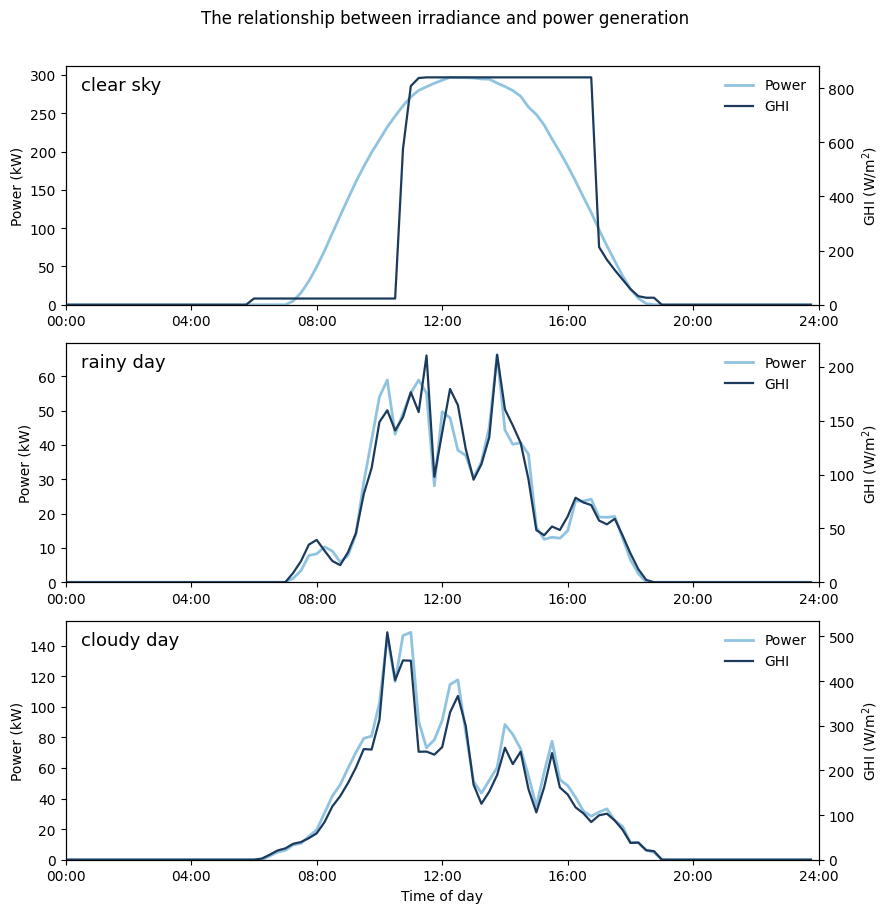

2022-02-24 2021-09-09 2021-07-27


In [3]:
def plot_fig1(df, clear_date, rainy_date, cloudy_date, save_path):
    fig, axes = plt.subplots(3, 1, figsize=(9, 9))
    specs = [(clear_date, "clear sky"), (rainy_date, "rainy day"), (cloudy_date, "cloudy day")]
    for (date, label), ax in zip(specs, axes):
        day = df[df['date'] == date].sort_values('datetime')
        t = day['hour']
        ax2 = ax.twinx()
        l1, = ax.plot(t, day['power_kw'], color='#8fc3e0', lw=2, label='Power')
        l2, = ax2.plot(t, day['GHI'], color='#1b3a5c', lw=1.6, label='GHI')
        ax.set_xlim(0, 24); ax.set_xticks(range(0, 25, 4))
        ax.set_xticklabels([f"{h:02d}:00" for h in range(0, 25, 4)])
        ax.set_ylabel("Power (kW)"); ax2.set_ylabel("GHI (W/m$^2$)")
        ax.text(0.02, 0.90, label, transform=ax.transAxes, fontsize=13)
        ax.legend(handles=[l1, l2], loc='upper right', frameon=False)
        ax.set_ylim(bottom=0); ax2.set_ylim(bottom=0)
    axes[-1].set_xlabel("Time of day")
    fig.suptitle("The relationship between irradiance and power generation", y=1.01, fontsize=12)
    fig.tight_layout()
    fig.savefig(save_path, dpi=200, bbox_inches='tight')
    plt.show()

def auto_pick_fig1_days(df):
    feats = daily_features(df)
    feats['rough_ratio'] = feats['ghi_roughness'] / feats['ghi_max'].replace(0, np.nan)
    clear = feats[feats['ghi_max'] > 750].sort_values('rough_ratio').iloc[0]['date']
    cloudy_cand = feats[(feats['ghi_max'] > 250) & (feats['ghi_max'] < 600)].sort_values('ghi_roughness')
    cloudy = cloudy_cand.iloc[len(cloudy_cand) // 3]['date']
    rainy = feats[feats['precip_frac'] > 0.05].sort_values('ghi_max').iloc[0]['date']
    return clear, rainy, cloudy

clear_d, rainy_d, cloudy_d = auto_pick_fig1_days(df)
plot_fig1(df, clear_d, rainy_d, cloudy_d, f"{OUT_DIR}/Fig1_reproduced.png")
print(clear_d, rainy_d, cloudy_d)

In [5]:


import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Ellipse
import matplotlib.transforms as transforms
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestRegressor

CSV_PATH = "C:\\Users\\VICTUS\\OneDrive\\Desktop\\MoET\\Merged_Dataset_Blockwise_Weather_1-4-21_to_1-4-22.csv"
CAPACITY_KW = 300.0
OUT_DIR = "outputs"


# ============================================================================
# 0. DATA LOADING (edit column names here if your CSV headers differ)
# ============================================================================
def load_data(path=CSV_PATH, capacity=CAPACITY_KW):
    cols = ['Date', 'Time', 'Actual', 'Radiation GHI', 'Ambient Temperature',
            'Wind Speed', 'Humidty\nRelative', 'Percepition Type']
    df = pd.read_csv(path, usecols=cols)
    df['datetime'] = pd.to_datetime(df['Date'] + ' ' + df['Time'],
                                     format='%d-%m-%Y %H:%M:%S', errors='coerce')
    df = df.dropna(subset=['datetime']).sort_values('datetime').reset_index(drop=True)
    df = df.rename(columns={'Radiation GHI': 'GHI', 'Ambient Temperature': 'Ta',
                             'Wind Speed': 'WS', 'Humidty\nRelative': 'RH',
                             'Percepition Type': 'Precip'})
    df['power_kw'] = df['Actual'].clip(lower=0)
    df['power_norm'] = df['power_kw'] / capacity
    df['date'] = df['datetime'].dt.date
    df['hour'] = df['datetime'].dt.hour + df['datetime'].dt.minute / 60
    return df


def daily_features(df):
    """One row per calendar day: peak/roughness stats used to auto-pick
    representative clear / cloudy / rainy days for Fig. 1."""
    g = df.groupby('date')
    feats = g.agg(ghi_mean=('GHI', 'mean'), ghi_max=('GHI', 'max'), ghi_std=('GHI', 'std'),
                   pv_mean=('power_norm', 'mean'), pv_max=('power_norm', 'max'),
                   precip_frac=('Precip', lambda x: (x > 0).mean()), n=('GHI', 'size')).reset_index()
    feats = feats[feats['n'] >= 90]

    def roughness(sub):
        day = sub[sub['GHI'] > 20]
        return float(np.mean(np.abs(np.diff(day['GHI'].values)))) if len(day) >= 5 else 0.0

    rough = g.apply(roughness).rename('ghi_roughness').reset_index()
    feats = feats.merge(rough, on='date')
    return feats


# ============================================================================
# FIGURE 1 - weather-dependent motivation (3 stacked dual-axis day plots)
# ============================================================================
def plot_fig1(df, clear_date, rainy_date, cloudy_date, save_path):
    fig, axes = plt.subplots(3, 1, figsize=(9, 9))
    specs = [(clear_date, "clear sky"), (rainy_date, "rainy day"), (cloudy_date, "cloudy day")]
    for (date, label), ax in zip(specs, axes):
        day = df[df['date'] == date].sort_values('datetime')
        t = day['hour']
        ax2 = ax.twinx()
        l1, = ax.plot(t, day['power_kw'], color='#8fc3e0', lw=2, label='Power')
        l2, = ax2.plot(t, day['GHI'], color='#1b3a5c', lw=1.6, label='GHI')
        ax.set_xlim(0, 24)
        ax.set_xticks(range(0, 25, 4))
        ax.set_xticklabels([f"{h:02d}:00" for h in range(0, 25, 4)])
        ax.set_ylabel("Power (kW)")
        ax2.set_ylabel("GHI (W/m$^2$)")
        ax.text(0.02, 0.90, label, transform=ax.transAxes, fontsize=13)
        ax.legend(handles=[l1, l2], loc='upper right', frameon=False)
        ax.set_ylim(bottom=0)
        ax2.set_ylim(bottom=0)
    axes[-1].set_xlabel("Time of day")
    fig.suptitle("The relationship between irradiance and power generation", y=1.01, fontsize=12)
    fig.tight_layout()
    fig.savefig(save_path, dpi=200, bbox_inches='tight')
    plt.close(fig)


def auto_pick_fig1_days(df):
    """Heuristic day-picker: smoothest/highest peak = clear, moderate = cloudy,
    days with recorded precipitation and a low, choppy peak = rainy."""
    feats = daily_features(df)
    feats['rough_ratio'] = feats['ghi_roughness'] / feats['ghi_max'].replace(0, np.nan)
    clear = feats[feats['ghi_max'] > 750].sort_values('rough_ratio').iloc[0]['date']
    cloudy_cand = feats[(feats['ghi_max'] > 250) & (feats['ghi_max'] < 600)].sort_values('ghi_roughness')
    cloudy = cloudy_cand.iloc[len(cloudy_cand) // 3]['date']
    rainy_cand = feats[feats['precip_frac'] > 0.05].sort_values('ghi_max')
    rainy = rainy_cand.iloc[0]['date']
    return clear, rainy, cloudy


# ============================================================================
# FIGURE 3 - weather-regime characterization (PCA scatter + daily profiles)
# ============================================================================
REGIME_COLORS = {'Clear-sky': '#2255a4', 'Cloudy': '#e8952e', 'Highly variable': '#d93b3b'}
REGIME_MARKERS = {'Clear-sky': 'o', 'Cloudy': 's', 'Highly variable': '^'}


def build_block_features(df, block_minutes=60):
    """Per-timestamp rolling features approximating the paper's regime inputs:
    local GHI level, a clear-sky-index proxy, short-window variability/ramp,
    and PV variance. Swap this out for your own engineered features if you
    have a specific clear-sky model (e.g. pvlib) already in your pipeline."""
    d = df.copy().set_index('datetime')
    win = f"{block_minutes}min"
    ghi_roll_mean = d['GHI'].rolling(win, min_periods=1).mean()
    ghi_roll_std = d['GHI'].rolling(win, min_periods=1).std().fillna(0)
    pv_roll_var = d['power_norm'].rolling(win, min_periods=1).var().fillna(0)
    day_max = d.groupby(d.index.date)['GHI'].transform('max').replace(0, np.nan)
    csi = (d['GHI'] / day_max).fillna(0).clip(0, 1.2)
    ghi_diff = d['GHI'].diff().abs().rolling(win, min_periods=1).mean().fillna(0)

    feat = pd.DataFrame({'ghi_level': ghi_roll_mean, 'clear_sky_index': csi,
                          'ghi_variability': ghi_roll_std, 'pv_variance': pv_roll_var,
                          'ghi_ramp': ghi_diff}).reset_index()
    feat['power_norm'] = d['power_norm'].values
    feat['GHI'] = d['GHI'].values
    feat['date'] = feat['datetime'].dt.date
    feat['hour'] = feat['datetime'].dt.hour + feat['datetime'].dt.minute / 60
    return feat.dropna()


def cluster_regimes(feat, n_regimes=3, daytime_only=True, random_state=42):
    """KMeans on standardized features + PCA for the 2-D scatter. Cluster IDs
    are re-labeled Clear-sky / Cloudy / Highly variable using GHI level and
    ramp-rate ranking, matching the paper's regime definitions."""
    work = feat[feat['GHI'] > 5].copy() if daytime_only else feat.copy()
    X_cols = ['ghi_level', 'clear_sky_index', 'ghi_variability', 'pv_variance', 'ghi_ramp']
    X = StandardScaler().fit_transform(work[X_cols])
    labels = KMeans(n_clusters=n_regimes, n_init=10, random_state=random_state).fit_predict(X)
    work['regime_raw'] = labels

    ramp_rank = work.groupby('regime_raw')['ghi_ramp'].mean()
    ghi_rank = work.groupby('regime_raw')['ghi_level'].mean()
    clear_c = (ghi_rank / (ramp_rank + 1e-6)).idxmax()
    variable_c = ramp_rank.idxmax()
    remaining = [c for c in ghi_rank.index if c not in (clear_c, variable_c)]
    cloudy_c = remaining[0] if remaining else clear_c
    work['regime'] = work['regime_raw'].map({clear_c: 'Clear-sky', cloudy_c: 'Cloudy', variable_c: 'Highly variable'})

    pca = PCA(n_components=2)
    pcs = pca.fit_transform(X)
    work['pc1'], work['pc2'] = pcs[:, 0], pcs[:, 1]
    return work, pca


def _confidence_ellipse(x, y, ax, n_std=2.2, **kwargs):
    if x.size < 3:
        return
    cov = np.cov(x, y)
    pearson = cov[0, 1] / np.sqrt(cov[0, 0] * cov[1, 1])
    rx, ry = np.sqrt(1 + pearson), np.sqrt(1 - pearson)
    ell = Ellipse((0, 0), width=rx * 2, height=ry * 2, **kwargs)
    tr = transforms.Affine2D().rotate_deg(45).scale(np.sqrt(cov[0, 0]) * n_std,
                                                      np.sqrt(cov[1, 1]) * n_std).translate(x.mean(), y.mean())
    ell.set_transform(tr + ax.transData)
    ax.add_patch(ell)


def _has_stuck_sensor(day_df, max_run=8):
    """Skip days where the GHI sensor repeats an identical non-zero value for
    too long (data-quality artifact) when picking a 'representative' day."""
    vals = day_df.sort_values('datetime')['GHI'].values
    run = 1
    for i in range(1, len(vals)):
        if vals[i] == vals[i - 1] and vals[i] > 5:
            run += 1
            if run > max_run:
                return True
        else:
            run = 1
    return False


def _pick_representative_day(work, df, regime_name):
    sub = work[work['regime'] == regime_name]
    counts = sub.groupby('date').size()
    all_counts = work.groupby('date').size()
    scored = sorted(((c / all_counts.get(d, 1), d) for d, c in counts.items()), key=lambda x: -x[0])
    for frac, d in scored:
        day_df = df[df['date'] == d]
        if len(day_df) >= 90 and not _has_stuck_sensor(day_df):
            return d
    return scored[0][1] if scored else None


def plot_fig3(df, work, save_path, sample_n=1200, random_state=0):
    fig = plt.figure(figsize=(15, 8))
    gs = fig.add_gridspec(1, 2, width_ratios=[1.05, 1.3], wspace=0.25)

    # Panel A: PCA scatter with confidence ellipses
    axA = fig.add_subplot(gs[0])
    rng = np.random.default_rng(random_state)
    for name in ['Clear-sky', 'Cloudy', 'Highly variable']:
        full = work[work['regime'] == name]
        sub = full.iloc[rng.choice(len(full), sample_n, replace=False)] if len(full) > sample_n else full
        axA.scatter(sub['pc1'], sub['pc2'], s=10, alpha=0.5, c=REGIME_COLORS[name],
                    marker=REGIME_MARKERS[name], label=name)
        _confidence_ellipse(full['pc1'].values, full['pc2'].values, axA, facecolor=REGIME_COLORS[name],
                             alpha=0.08, edgecolor=REGIME_COLORS[name], linestyle='--', linewidth=1.2)
    axA.set_xlabel("Principal Component 1")
    axA.set_ylabel("Principal Component 2")
    axA.set_title("(a) Feature-space clustering of weather regimes", loc='left', fontsize=12)
    axA.legend(frameon=False, loc='upper left')

    counts = work['regime'].value_counts()
    pct = (counts / counts.sum() * 100).round(1)
    txt = "Cluster statistics\n" + "\n".join(f"{n}: {counts[n]} ({pct[n]}%)"
                                              for n in ['Clear-sky', 'Cloudy', 'Highly variable'])
    axA.text(0.98, 0.02, txt, transform=axA.transAxes, ha='right', va='bottom', fontsize=9,
             bbox=dict(boxstyle='round', fc='white', ec='0.7'))

    # Panel B: representative daily profiles (GHI / PV power / weather variables)
    regimes = ['Clear-sky', 'Cloudy', 'Highly variable']
    gsB = gs[1].subgridspec(3, len(regimes), hspace=0.35, wspace=0.3)
    for j, name in enumerate(regimes):
        rep_date = _pick_representative_day(work, df, name)
        day = df[df['date'] == rep_date].sort_values('datetime')
        t = day['hour']

        ax1 = fig.add_subplot(gsB[0, j])
        ax1.plot(t, day['GHI'], color=REGIME_COLORS[name], lw=1.6)
        ax1.set_title(name, fontsize=11, color=REGIME_COLORS[name])
        if j == 0:
            ax1.set_ylabel("GHI (W/m$^2$)")
        ax1.set_xlim(0, 24)
        ax1.set_xticks([0, 6, 12, 18, 24])
        ax1.set_xticklabels([])

        ax2 = fig.add_subplot(gsB[1, j])
        ax2.plot(t, day['power_kw'], color=REGIME_COLORS[name], lw=1.6)
        if j == 0:
            ax2.set_ylabel("PV Power (kW)")
        ax2.set_xlim(0, 24)
        ax2.set_xticks([0, 6, 12, 18, 24])
        ax2.set_xticklabels([])

        ax3 = fig.add_subplot(gsB[2, j])
        for col, c in zip(['Ta', 'WS', 'RH'], ['#e8952e', '#2c8a4b', '#7a4fbf']):
            vals = day[col]
            norm = (vals - vals.min()) / (vals.max() - vals.min() + 1e-9)
            ax3.plot(t, norm, color=c, lw=1.3)
        if j == 0:
            ax3.set_ylabel("Variables\n(normalized)")
        ax3.set_xlim(0, 24)
        ax3.set_xticks([0, 6, 12, 18, 24])
        ax3.set_xlabel("Time of day (h)")

    handles = [plt.Line2D([0], [0], color=c, lw=1.6) for c in ['#e8952e', '#2c8a4b', '#7a4fbf']]
    fig.legend(handles, ['Ambient temperature (T$_a$)', 'Wind speed (WS)', 'Relative humidity (RH)'],
               loc='lower center', ncol=3, frameon=False, bbox_to_anchor=(0.7, -0.02))
    fig.suptitle("Weather-regime characterization and separation", fontsize=13, y=1.02)
    fig.savefig(save_path, dpi=200, bbox_inches='tight')
    plt.close(fig)


# ============================================================================
# FIGURE 4 - actual vs. forecasted PV power (generic plotting function)
# ============================================================================
def plot_fig4(result_df, day_windows, save_path, actual_col='actual',
              model_cols=('Transformer', 'WR_MoE'),
              model_labels=('Transformer', 'WR-MoE (Proposed)'),
              model_colors=('#2255d4', '#d93b3b'),
              model_styles=('--o', '--^'),
              panel_titles=('Clear-sky day (Stable generation)',
                            'Cloudy day (Moderate variability)',
                            'Highly variable day (Rapid ramps and drops)'),
              zoom_windows=None):
    """
    Generic Fig. 4 plotter - PLUG YOUR OWN MODEL OUTPUTS IN HERE.
    result_df needs: 'datetime', actual_col, and one column per name in model_cols.
    day_windows: 3x (start, end) timestamps, one per panel.
    """
    result_df = result_df.copy()
    result_df['datetime'] = pd.to_datetime(result_df['datetime'])
    n = len(day_windows)
    fig, axes = plt.subplots(2, n, figsize=(5.2 * n, 7))

    if zoom_windows is None:
        zoom_windows = []
        for start, end in day_windows:
            s, e = pd.Timestamp(start), pd.Timestamp(end)
            mid = s + (e - s) / 2
            zoom_windows.append((mid - pd.Timedelta(hours=2), mid + pd.Timedelta(hours=2)))

    for j, (start, end) in enumerate(day_windows):
        sub = result_df[(result_df['datetime'] >= start) & (result_df['datetime'] <= end)]
        t = sub['datetime']
        ax_top = axes[0, j]
        ax_top.plot(t, sub[actual_col], color='k', lw=1.8, marker='o', ms=3, label='Actual')
        for col, lbl, c, style in zip(model_cols, model_labels, model_colors, model_styles):
            ax_top.plot(t, sub[col], style, color=c, lw=1.4, ms=3, label=lbl)
        ax_top.set_title(panel_titles[j], fontsize=11)
        if j == 0:
            ax_top.set_ylabel("PV Power")
            ax_top.legend(frameon=False, fontsize=9, loc='upper right')
        ax_top.set_xticks([t.iloc[0], t.iloc[len(t) // 2], t.iloc[-1]])
        ax_top.set_xticklabels([tt.strftime('%H:%M') for tt in
                                 [t.iloc[0], t.iloc[len(t) // 2], t.iloc[-1]]])

        zs, ze = zoom_windows[j]
        zsub = result_df[(result_df['datetime'] >= zs) & (result_df['datetime'] <= ze)]
        tz = zsub['datetime']
        ax_bot = axes[1, j]
        ax_bot.plot(tz, zsub[actual_col], color='k', lw=1.8, marker='o', ms=4, label='Actual')
        for col, lbl, c, style in zip(model_cols, model_labels, model_colors, model_styles):
            ax_bot.plot(tz, zsub[col], style, color=c, lw=1.4, ms=4)
        ax_bot.set_title(f"Zoomed view ({zs.strftime('%H:%M')}\u2013{ze.strftime('%H:%M')})",
                          fontsize=9, style='italic')
        if j == 0:
            ax_bot.set_ylabel("PV Power (zoom)")
        ax_bot.set_xticks([tz.iloc[0], tz.iloc[len(tz) // 2], tz.iloc[-1]])
        ax_bot.set_xticklabels([tt.strftime('%H:%M') for tt in
                                 [tz.iloc[0], tz.iloc[len(tz) // 2], tz.iloc[-1]]])

    fig.suptitle("Actual vs. forecasted PV power generation under different weather regimes", y=1.02)
    fig.tight_layout()
    fig.savefig(save_path, dpi=200, bbox_inches='tight')
    plt.close(fig)


def demo_forecast(df, work, horizon_steps=4, lookback=16, test_frac=0.15):
    """
    DEMO ONLY. Trains two lightweight RandomForest models purely so Fig. 4 has
    something real to plot. Replace this with your actual saved test-set
    predictions (actual / Transformer / WR-MoE-Transformer) before publishing.
    """
    d = df[['datetime', 'power_norm', 'GHI', 'Ta', 'WS', 'RH']].copy()
    for k in range(1, lookback + 1):
        d[f'p_lag{k}'] = d['power_norm'].shift(k)
    d['hour_sin'] = np.sin(2 * np.pi * d['datetime'].dt.hour / 24)
    d['hour_cos'] = np.cos(2 * np.pi * d['datetime'].dt.hour / 24)
    d['target'] = d['power_norm'].shift(-horizon_steps)
    d = d.merge(work[['datetime', 'regime']], on='datetime', how='left')
    d['regime'] = d['regime'].fillna('Cloudy')
    d = d.dropna().reset_index(drop=True)
    feat_cols = [c for c in d.columns if c.startswith('p_lag')] + ['GHI', 'Ta', 'WS', 'RH', 'hour_sin', 'hour_cos']

    n_test = int(len(d) * test_frac)
    train, test = d.iloc[:-n_test], d.iloc[-n_test:]

    global_model = RandomForestRegressor(n_estimators=150, max_depth=10, n_jobs=-1, random_state=0)
    global_model.fit(train[feat_cols], train['target'])
    pred_global = global_model.predict(test[feat_cols])

    experts = {}
    for name, sub in train.groupby('regime'):
        if len(sub) < 50:
            continue
        m = RandomForestRegressor(n_estimators=150, max_depth=10, n_jobs=-1, random_state=1)
        m.fit(sub[feat_cols], sub['target'])
        experts[name] = m
    pred_experts = np.zeros(len(test))
    for name, m in experts.items():
        mask = (test['regime'] == name).values
        if mask.any():
            pred_experts[mask] = m.predict(test.loc[mask, feat_cols])
    pred_moe = pd.Series(pred_experts).rolling(3, center=True, min_periods=1).mean().values

    out = test[['datetime']].copy()
    out['actual'] = test['target'].values
    out['Transformer'] = pred_global
    out['WR_MoE'] = pred_moe
    return out


# ============================================================================
# MAIN
# ============================================================================
if __name__ == "__main__":
    os.makedirs(OUT_DIR, exist_ok=True)
    df = load_data()

    # ---- Fig 1 ----
    clear_d, rainy_d, cloudy_d = auto_pick_fig1_days(df)
    plot_fig1(df, clear_d, rainy_d, cloudy_d, f"{OUT_DIR}/Fig1_reproduced.png")
    print("Saved Fig1_reproduced.png  (clear=%s rainy=%s cloudy=%s)" % (clear_d, rainy_d, cloudy_d))

    # ---- Fig 3 ----
    feat = build_block_features(df)
    work, pca = cluster_regimes(feat)
    plot_fig3(df, work, f"{OUT_DIR}/Fig3_reproduced.png")
    print("Saved Fig3_reproduced.png. Regime counts:\n", work['regime'].value_counts())

    # ---- Fig 4 (demo forecasts - replace with your real model outputs!) ----
    res = demo_forecast(df, work, horizon_steps=4)  # 4 steps @ 15 min = 1h horizon
    res_dates = res['datetime'].dt.date.unique()
    work_test = work[work['date'].isin(res_dates)]
    windows = []
    for name in ['Clear-sky', 'Cloudy', 'Highly variable']:
        sub = work_test[work_test['regime'] == name]
        if len(sub):
            best_date = sub.groupby('date').size().idxmax()
            windows.append((f"{best_date} 06:00", f"{best_date} 18:00"))
    plot_fig4(res, windows, f"{OUT_DIR}/Fig4_reproduced.png")
    print("Saved Fig4_reproduced.png for days:", windows)

C:\Users\VICTUS\AppData\Local\Temp\ipykernel_17048\1545910378.py:50: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  rough = g.apply(roughness).rename('ghi_roughness').reset_index()


Saved Fig1_reproduced.png  (clear=2022-02-24 rainy=2021-09-09 cloudy=2021-07-27)
Saved Fig3_reproduced.png. Regime counts:
 regime
Cloudy             8061
Clear-sky          6926
Highly variable    2097
Name: count, dtype: int64
Saved Fig4_reproduced.png for days: [('2022-03-22 06:00', '2022-03-22 18:00'), ('2022-02-27 06:00', '2022-02-27 18:00'), ('2022-03-25 06:00', '2022-03-25 18:00')]


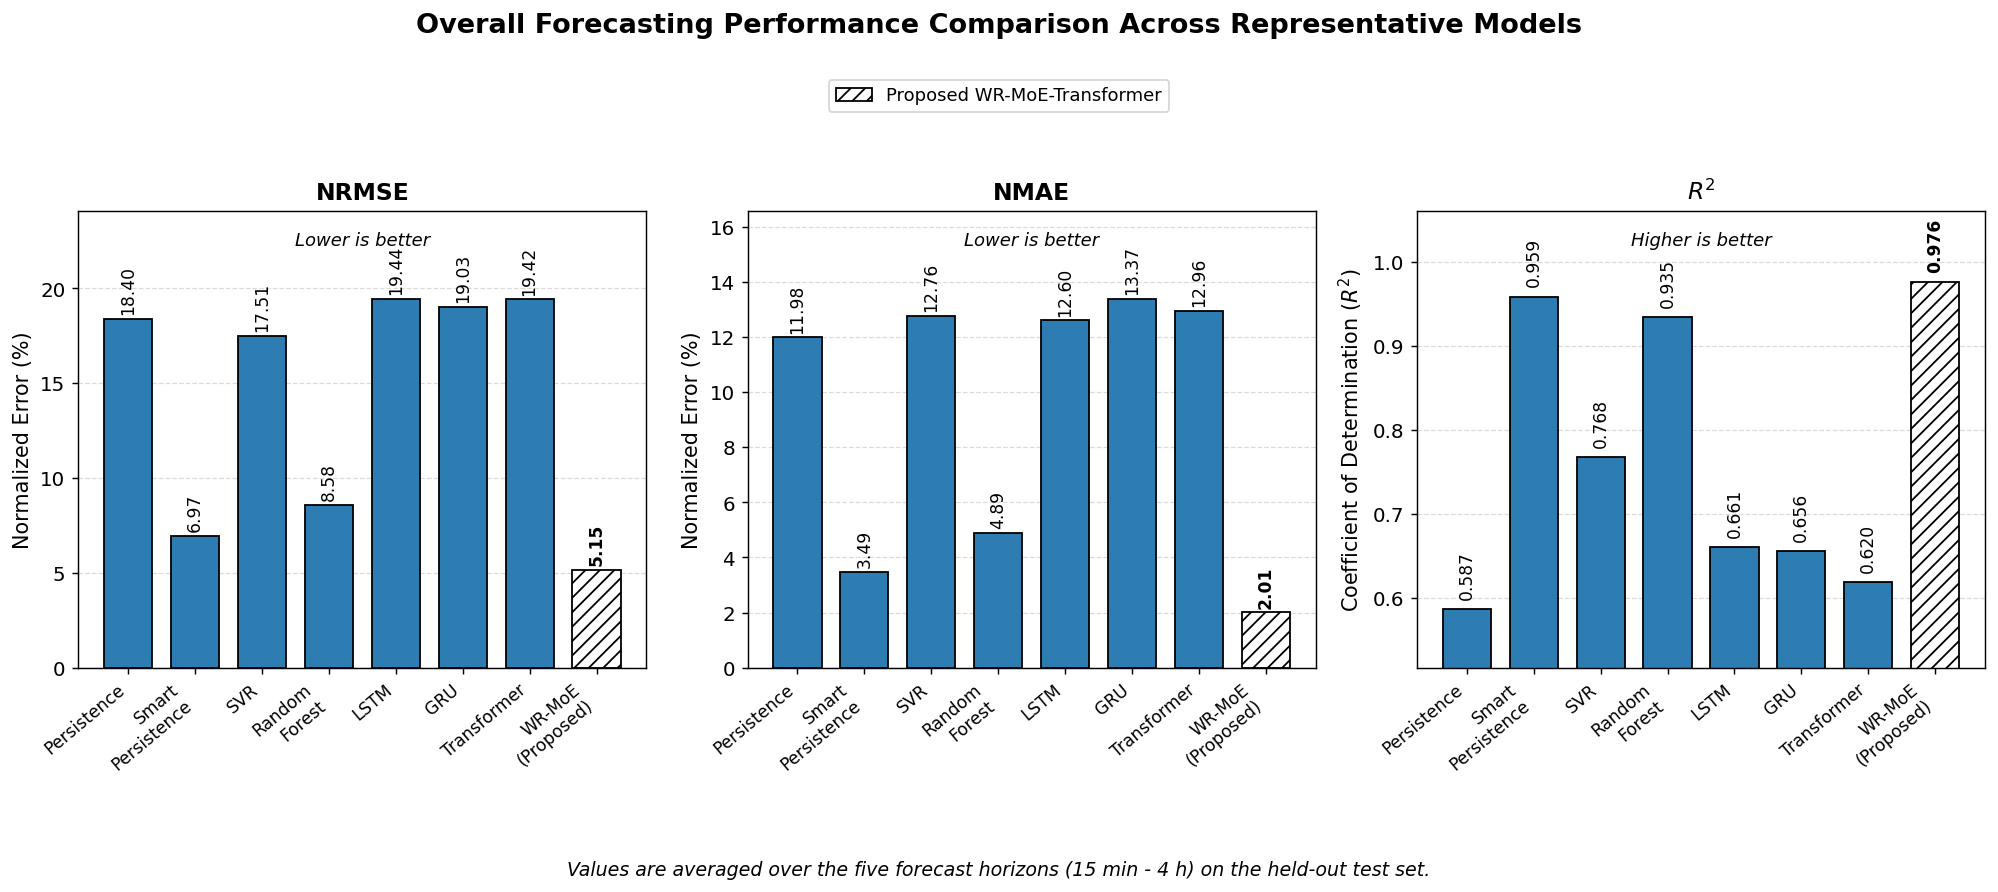

saved outputs/Fig5_overall_forecasting_performance.png


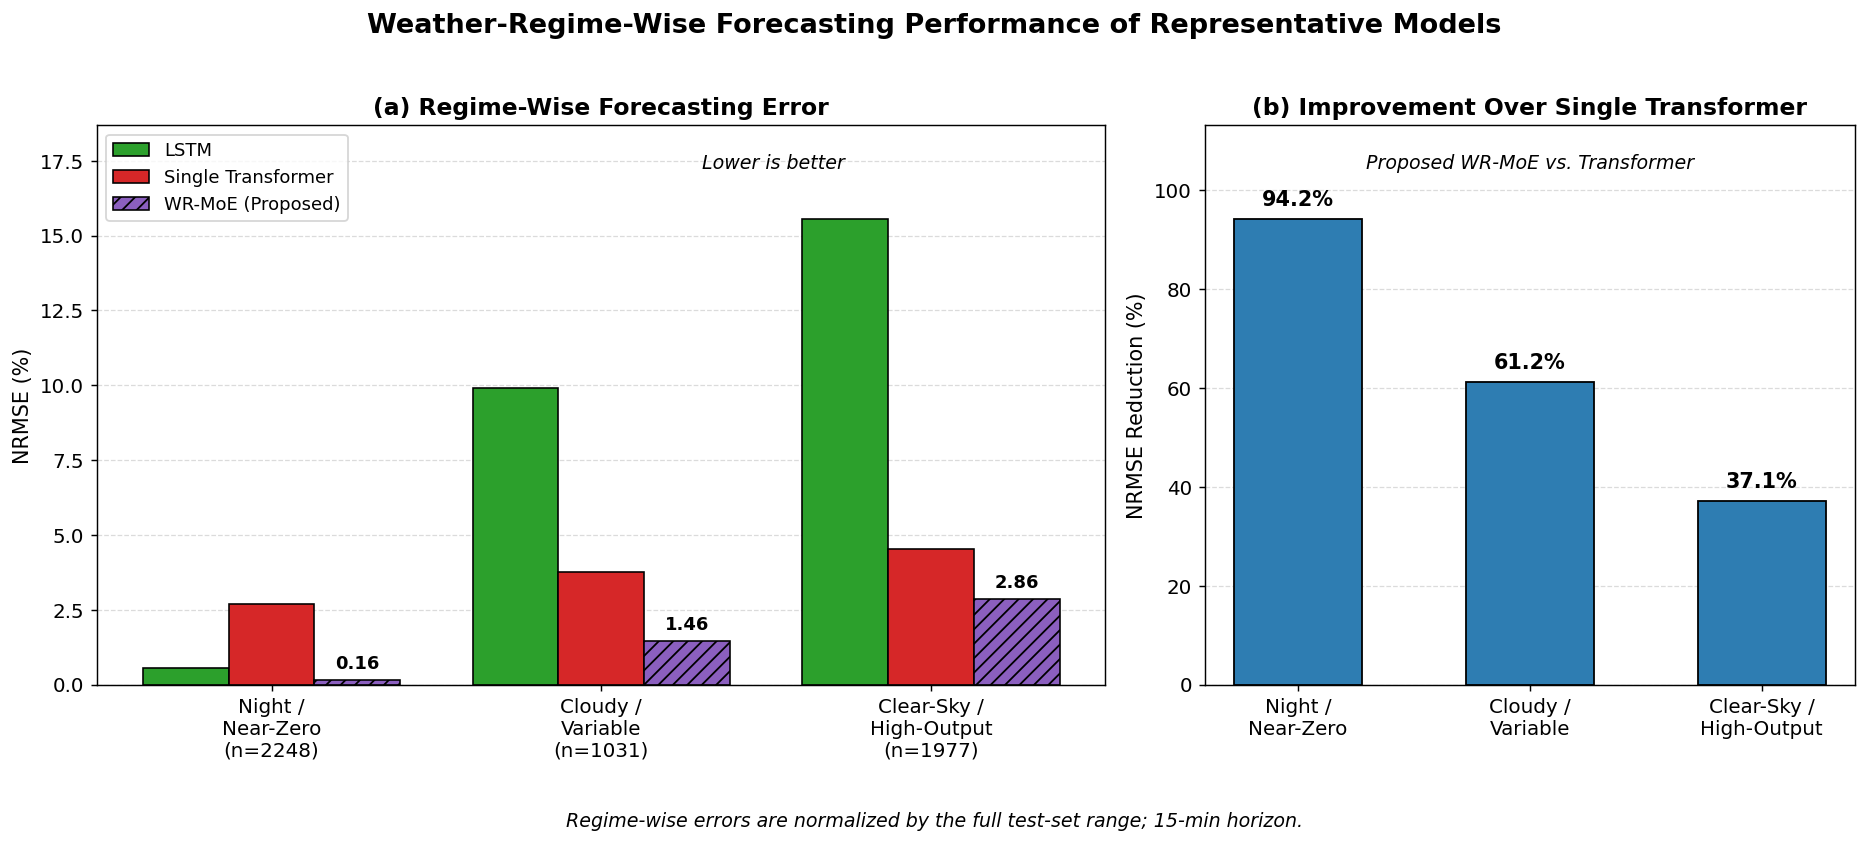

saved outputs/Fig6_weather_regime_wise_performance.png


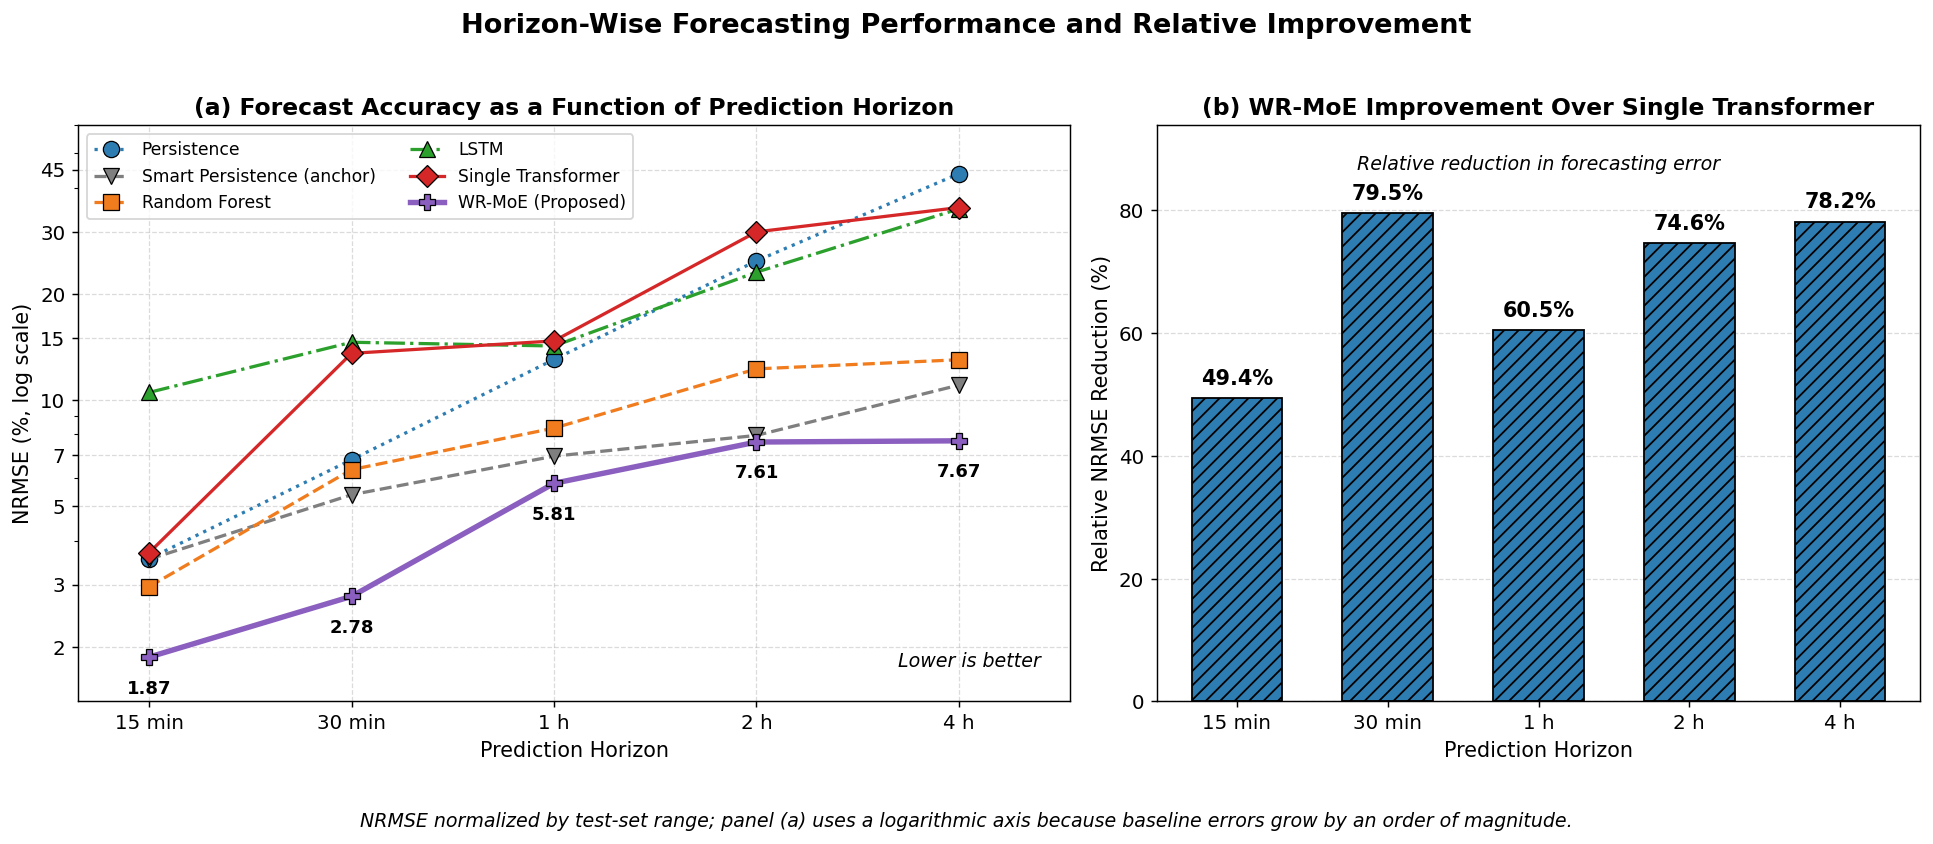

saved outputs/Fig8_forecast_accuracy_vs_horizon.png
Fig 7 skipped: ./moet_test_predictions.npz not found. Add the 3-line dump patch inside main() (see instructions) and re-run the 15-min horizon so per-sample predictions are saved. Fig. 7 is a distribution plot and cannot be produced from summary metrics alone.


In [8]:
import os, json
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.lines import Line2D

RESULTS_PATH = "./results.json"
PRED_PATH    = "./moet_test_predictions.npz"   # written by the Fig-7 patch
FIG_DIR      = "outputs"
os.makedirs(FIG_DIR, exist_ok=True)

R = json.load(open(RESULTS_PATH))
HORIZONS = ["15 min", "30 min", "1 h", "2 h", "4 h"]

# ---- IEEE-ish styling -------------------------------------------------------
plt.rcParams.update({
    "figure.dpi": 130, "savefig.dpi": 400,
    "font.family": "DejaVu Sans", "font.size": 11,
    "axes.titlesize": 13, "axes.titleweight": "bold",
    "axes.labelsize": 11.5, "axes.grid": True,
    "grid.linestyle": "--", "grid.alpha": 0.45, "grid.linewidth": 0.7,
    "axes.axisbelow": True, "legend.frameon": True, "legend.fontsize": 10,
})
C_BAR   = "#2E7DB2"     # baseline blue
C_PROP  = "#2E7DB2"     # proposed (hatched)
PALETTE = ["#2E7DB2", "#F07C1E", "#2CA02C", "#D62728", "#8B5FBF"]

# ---- regime ordering: identical rule to the Section-11 table builder --------
_prof   = R["meta"]["regime_profile"]
_order  = sorted(_prof.keys(), key=lambda k: _prof[k]["pv_actual_norm"])
REGIME_KEYS   = _order                                   # night, cloudy, clear
REGIME_LABELS = ["Night /\nNear-Zero", "Cloudy /\nVariable", "Clear-Sky /\nHigh-Output"]

def m(model, horizon, field):
    return float(R["horizons"][horizon]["metrics"][model][field])

def avg(model, field):
    """Mean across all five horizons -- the Table-III convention."""
    return float(np.mean([m(model, h, field) for h in HORIZONS]))

def _annotate(ax, bars, fmt="{:.2f}", bold_last=True, pad=0.012):
    top = max(b.get_height() for b in bars)
    for i, b in enumerate(bars):
        last = bold_last and i == len(bars) - 1
        ax.text(b.get_x() + b.get_width() / 2, b.get_height() + pad * top,
                fmt.format(b.get_height()), ha="center", va="bottom",
                fontsize=9.5, rotation=90,
                fontweight="bold" if last else "normal")


# =============================================================================
# FIGURE 5 -- Overall forecasting performance comparison
#   Each bar = that model's metric averaged over the five horizons.
# =============================================================================
def plot_fig5(save=f"{FIG_DIR}/Fig5_overall_forecasting_performance.png"):
    models = ["Persistence", "Smart Persistence (anchor)", "SVR", "RF",
              "LSTM", "GRU", "Transformer", "WR-MoE-Transformer"]
    disp   = ["Persistence", "Smart\nPersistence", "SVR", "Random\nForest",
              "LSTM", "GRU", "Transformer", "WR-MoE\n(Proposed)"]

    panels = [("nRMSE_range", "NRMSE", "Normalized Error (%)", "Lower is better"),
              ("nMAE_range",  "NMAE",  "Normalized Error (%)", "Lower is better"),
              ("R2",          r"$R^2$", r"Coefficient of Determination ($R^2$)", "Higher is better")]

    fig, axes = plt.subplots(1, 3, figsize=(15.5, 5.6))
    for ax, (field, title, ylab, hint) in zip(axes, panels):
        vals = [avg(mm, field) for mm in models]
        bars = ax.bar(range(len(models)), vals, color=C_BAR,
                      edgecolor="black", linewidth=1.0, width=0.72)
        bars[-1].set_hatch("///"); bars[-1].set_facecolor("white")
        bars[-1].set_edgecolor("black")

        lo, hi = min(vals), max(vals)
        span = hi - lo if hi > lo else abs(hi) + 1e-6
        if field == "R2":
            ax.set_ylim(lo - 0.18 * span, hi + 0.22 * span)
        else:
            ax.set_ylim(0, hi * 1.24)
        _annotate(ax, bars, "{:.2f}" if field != "R2" else "{:.3f}")

        ax.set_title(title); ax.set_ylabel(ylab)
        ax.set_xticks(range(len(models)))
        ax.set_xticklabels(disp, rotation=40, ha="right", fontsize=9.5)
        ax.text(0.5, 0.955, hint, transform=ax.transAxes, ha="center",
                va="top", fontsize=10, style="italic")
        ax.grid(axis="x", visible=False)

    fig.legend(handles=[Patch(facecolor="white", edgecolor="black", hatch="///",
                              label="Proposed WR-MoE-Transformer")],
               loc="upper center", bbox_to_anchor=(0.5, 0.995), ncol=1)
    fig.suptitle("Overall Forecasting Performance Comparison Across Representative Models",
                 fontsize=15, fontweight="bold", y=1.075)
    fig.text(0.5, -0.11, "Values are averaged over the five forecast horizons "
             "(15 min - 4 h) on the held-out test set.",
             ha="center", fontsize=10.5, style="italic")
    fig.tight_layout(rect=[0, 0, 1, 0.94])
    fig.savefig(save, bbox_inches="tight"); plt.show()
    print("saved", save)


# =============================================================================
# FIGURE 6 -- Weather-regime-wise performance (15-min headline horizon)
# =============================================================================
def plot_fig6(save=f"{FIG_DIR}/Fig6_weather_regime_wise_performance.png"):
    rt = R["regime_table"]
    models = ["LSTM", "Transformer", "WR-MoE-Transformer"]
    disp   = ["LSTM", "Single Transformer", "WR-MoE (Proposed)"]
    cols   = [PALETTE[2], PALETTE[3], PALETTE[4]]

    vals = {mm: [float(rt[k][mm]["nRMSE_range"]) for k in REGIME_KEYS] for mm in models}
    n_s  = [rt[k]["samples"] for k in REGIME_KEYS]

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14.5, 5.8),
                                   gridspec_kw={"width_ratios": [1.55, 1]})
    x, w = np.arange(3), 0.26
    for i, (mm, d, c) in enumerate(zip(models, disp, cols)):
        off = (i - 1) * w
        b = ax1.bar(x + off, vals[mm], w, label=d, color=c,
                    edgecolor="black", linewidth=0.9)
        if mm == "WR-MoE-Transformer":
            for bb in b: bb.set_hatch("///")
            for bb, v in zip(b, vals[mm]):
                ax1.text(bb.get_x() + bb.get_width() / 2, v + 0.25, f"{v:.2f}",
                         ha="center", va="bottom", fontsize=10, fontweight="bold")

    ax1.set_xticks(x)
    ax1.set_xticklabels([f"{l}\n(n={n})" for l, n in zip(REGIME_LABELS, n_s)])
    ax1.set_ylabel("NRMSE (%)")
    ax1.set_title("(a) Regime-Wise Forecasting Error")
    ax1.set_ylim(0, max(max(v) for v in vals.values()) * 1.20)
    ax1.legend(loc="upper left"); ax1.grid(axis="x", visible=False)
    ax1.text(0.60, 0.95, "Lower is better", transform=ax1.transAxes,
             fontsize=10.5, style="italic", va="top")

    imp = [(t - w_) / t * 100 for t, w_ in zip(vals["Transformer"], vals["WR-MoE-Transformer"])]
    b2 = ax2.bar(x, imp, 0.55, color=C_BAR, edgecolor="black", linewidth=1.0)
    for bb, v in zip(b2, imp):
        ax2.text(bb.get_x() + bb.get_width() / 2, v + max(imp) * 0.02, f"{v:.1f}%",
                 ha="center", va="bottom", fontsize=11.5, fontweight="bold")
    ax2.set_xticks(x); ax2.set_xticklabels(REGIME_LABELS)
    ax2.set_ylabel("NRMSE Reduction (%)")
    ax2.set_title("(b) Improvement Over Single Transformer")
    ax2.set_ylim(0, max(imp) * 1.20); ax2.grid(axis="x", visible=False)
    ax2.text(0.5, 0.95, "Proposed WR-MoE vs. Transformer", transform=ax2.transAxes,
             ha="center", va="top", fontsize=10.5, style="italic")

    fig.suptitle("Weather-Regime-Wise Forecasting Performance of Representative Models",
                 fontsize=15, fontweight="bold", y=1.02)
    fig.text(0.5, -0.06, "Regime-wise errors are normalized by the full test-set range; "
             "15-min horizon.", ha="center", fontsize=10.5, style="italic")
    fig.tight_layout(); fig.savefig(save, bbox_inches="tight"); plt.show()
    print("saved", save)


# =============================================================================
# FIGURE 8 -- Accuracy vs. prediction horizon  (+ relative improvement)
# =============================================================================
def plot_fig8(save=f"{FIG_DIR}/Fig8_forecast_accuracy_vs_horizon.png"):
    series = [("Persistence",                "o", ":",   PALETTE[0]),
              ("Smart Persistence (anchor)", "v", "--",  "#7F7F7F"),
              ("RF",                         "s", "--",  PALETTE[1]),
              ("LSTM",                       "^", "-.",  PALETTE[2]),
              ("Transformer",                "D", "-",   PALETTE[3]),
              ("WR-MoE-Transformer",         "P", "-",   PALETTE[4])]
    names = {"RF": "Random Forest", "Transformer": "Single Transformer",
             "WR-MoE-Transformer": "WR-MoE (Proposed)"}

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5.8),
                                   gridspec_kw={"width_ratios": [1.3, 1]})
    x = np.arange(len(HORIZONS))
    for mm, mk, ls, c in series:
        y = [m(mm, h, "nRMSE_range") for h in HORIZONS]
        lw = 3.0 if mm == "WR-MoE-Transformer" else 1.8
        ax1.plot(x, y, marker=mk, linestyle=ls, color=c, linewidth=lw,
                 markersize=9, markeredgecolor="black", markeredgewidth=0.7,
                 label=names.get(mm, mm))
        if mm == "WR-MoE-Transformer":
            for xi, yi in zip(x, y):
                ax1.annotate(f"{yi:.2f}", (xi, yi), textcoords="offset points",
                             xytext=(0, -20), ha="center", fontsize=10,
                             fontweight="bold")
    ax1.set_yscale("log")
    ax1.set_yticks([2, 3, 5, 7, 10, 15, 20, 30, 45])
    ax1.get_yaxis().set_major_formatter(plt.ScalarFormatter())
    ax1.get_yaxis().set_minor_formatter(plt.NullFormatter())
    ax1.set_ylim(1.4, 60)
    ax1.set_xlim(-0.35, len(HORIZONS) - 0.45)
    ax1.set_xticks(x); ax1.set_xticklabels(HORIZONS)
    ax1.set_xlabel("Prediction Horizon"); ax1.set_ylabel("NRMSE (%, log scale)")
    ax1.set_title("(a) Forecast Accuracy as a Function of Prediction Horizon")
    ax1.legend(loc="upper left", ncol=2, fontsize=9.5)
    ax1.text(0.97, 0.06, "Lower is better", transform=ax1.transAxes,
             ha="right", fontsize=10.5, style="italic")

    imp = [(m("Transformer", h, "nRMSE_range") - m("WR-MoE-Transformer", h, "nRMSE_range"))
           / m("Transformer", h, "nRMSE_range") * 100 for h in HORIZONS]
    b = ax2.bar(x, imp, 0.6, color=C_BAR, edgecolor="black",
                linewidth=1.0, hatch="///")
    for bb, v in zip(b, imp):
        ax2.text(bb.get_x() + bb.get_width() / 2, v + max(imp) * 0.02, f"{v:.1f}%",
                 ha="center", va="bottom", fontsize=11.5, fontweight="bold")
    ax2.set_xticks(x); ax2.set_xticklabels(HORIZONS)
    ax2.set_xlabel("Prediction Horizon"); ax2.set_ylabel("Relative NRMSE Reduction (%)")
    ax2.set_title("(b) WR-MoE Improvement Over Single Transformer")
    ax2.set_ylim(0, max(imp) * 1.18); ax2.grid(axis="x", visible=False)
    ax2.text(0.5, 0.95, "Relative reduction in forecasting error",
             transform=ax2.transAxes, ha="center", va="top",
             fontsize=10.5, style="italic")

    fig.suptitle("Horizon-Wise Forecasting Performance and Relative Improvement",
                 fontsize=15, fontweight="bold", y=1.02)
    fig.text(0.5, -0.06, "NRMSE normalized by test-set range; panel (a) uses a "
             "logarithmic axis because baseline errors grow by an order of magnitude.",
             ha="center", fontsize=10.5, style="italic")
    fig.tight_layout(); fig.savefig(save, bbox_inches="tight"); plt.show()
    print("saved", save)


# =============================================================================
# FIGURE 7 -- Error distribution across weather regimes
#   Requires ./moet_test_predictions.npz  (see patch instructions in chat).
# =============================================================================
def plot_fig7(save=f"{FIG_DIR}/Fig7_error_distribution_across_regimes.png",
              pred_path=PRED_PATH):
    if not os.path.exists(pred_path):
        raise FileNotFoundError(
            f"{pred_path} not found. Add the 3-line dump patch inside main() "
            "(see instructions) and re-run the 15-min horizon so per-sample "
            "predictions are saved. Fig. 7 is a distribution plot and cannot be "
            "produced from summary metrics alone.")
    d = np.load(pred_path)
    y_true, y_moe, y_tr, regimes = d["y_true"], d["y_moe"], d["y_transf"], d["regimes"]
    err_tr, err_moe = np.abs(y_true - y_tr), np.abs(y_true - y_moe)

    titles = ["(a) Night / Near-Zero Regime", "(b) Cloudy / Variable Regime",
              "(c) Clear-Sky / High-Output Regime"]
    fig, axes = plt.subplots(1, 3, figsize=(15.5, 6.0))
    for ax, key, title in zip(axes, REGIME_KEYS, titles):
        msk = regimes == int(key)
        data = [err_tr[msk], err_moe[msk]]
        bp = ax.boxplot(data, widths=0.55, patch_artist=True, showmeans=True,
                        meanprops=dict(marker="D", markerfacecolor="white",
                                       markeredgecolor="black", markersize=8),
                        medianprops=dict(color="black", linewidth=2.2),
                        flierprops=dict(marker="o", markerfacecolor="none",
                                        markersize=4, alpha=0.55))
        bp["boxes"][0].set(facecolor="#D9D9D9", edgecolor="black")
        bp["boxes"][1].set(facecolor="white", edgecolor="black", hatch="///")
        for i, dd in enumerate(data, start=1):
            jit = np.random.normal(i, 0.055, size=min(len(dd), 400))
            ax.scatter(jit, np.random.choice(dd, size=len(jit), replace=False),
                       s=5, color="gray", alpha=0.25, zorder=1)
            med = np.median(dd)
            ax.text(i, med, f"Median={med:.4f}", ha="center", va="bottom",
                    fontsize=9.5, fontweight="bold" if i == 2 else "normal",
                    bbox=dict(boxstyle="round,pad=0.2", fc="white", alpha=0.75, lw=0))
        ax.set_xticklabels(["Single\nTransformer", "WR-MoE\n(Proposed)"])
        ax.set_title(title); ax.grid(axis="x", visible=False)
        hi = np.percentile(np.concatenate(data), 99.5)
        ax.set_ylim(-0.02 * hi, hi * 1.25)
    axes[0].set_ylabel("Absolute Prediction Error (p.u.)")

    fig.legend(handles=[Line2D([0], [0], color="black", lw=2.2, label="Median"),
                        Line2D([0], [0], marker="D", color="black", lw=0,
                               markerfacecolor="white", markersize=9, label="Mean"),
                        Patch(facecolor="#D9D9D9", edgecolor="black", label="Single Transformer"),
                        Patch(facecolor="white", edgecolor="black", hatch="///",
                              label="WR-MoE (Proposed)")],
               loc="upper center", bbox_to_anchor=(0.5, 0.99), ncol=4)
    fig.suptitle("Distribution of Absolute Forecasting Errors Across Weather Regimes",
                 fontsize=15, fontweight="bold", y=1.075)
    fig.text(0.5, -0.05, "Box limits indicate the interquartile range; whiskers extend to "
             "1.5xIQR; diamonds denote mean errors; individual markers represent outliers.",
             ha="center", fontsize=10.5, style="italic")
    fig.tight_layout(rect=[0, 0, 1, 0.93])
    fig.savefig(save, bbox_inches="tight"); plt.show()
    print("saved", save)


if __name__ == "__main__":
    plot_fig5(); plot_fig6(); plot_fig8()
    try:
        plot_fig7()
    except FileNotFoundError as e:
        print("Fig 7 skipped:", e)

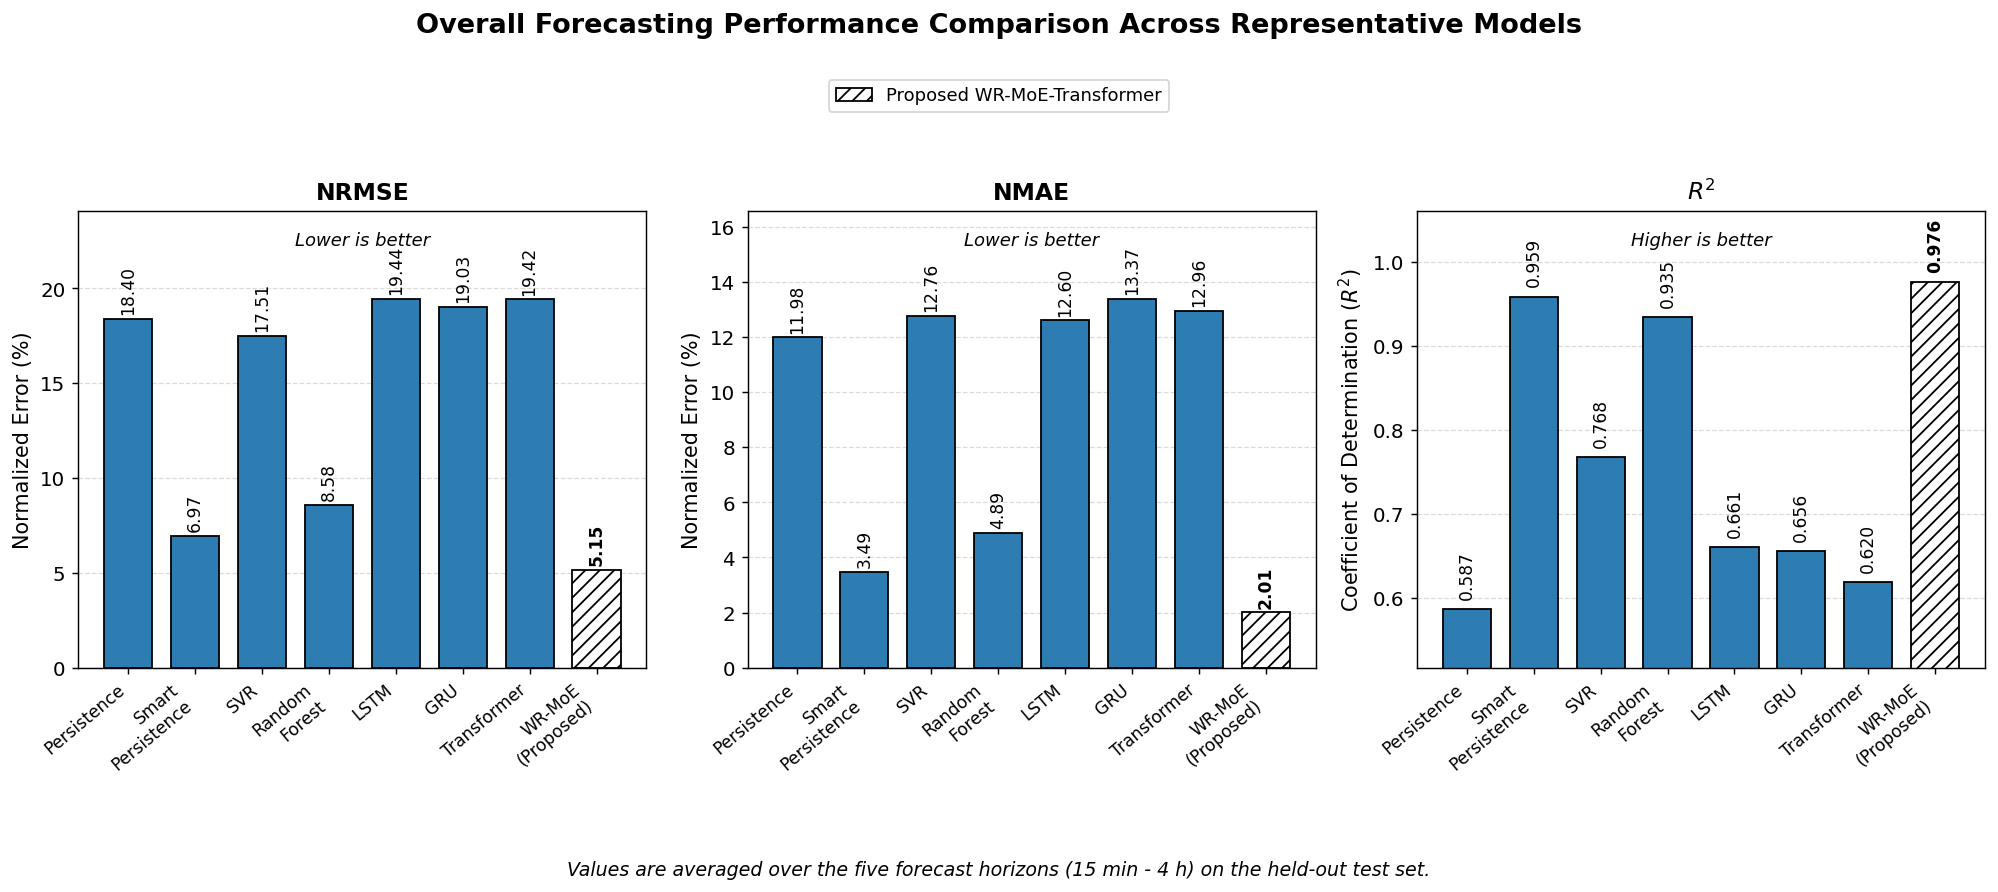

saved outputs/Fig5_overall_forecasting_performance.png


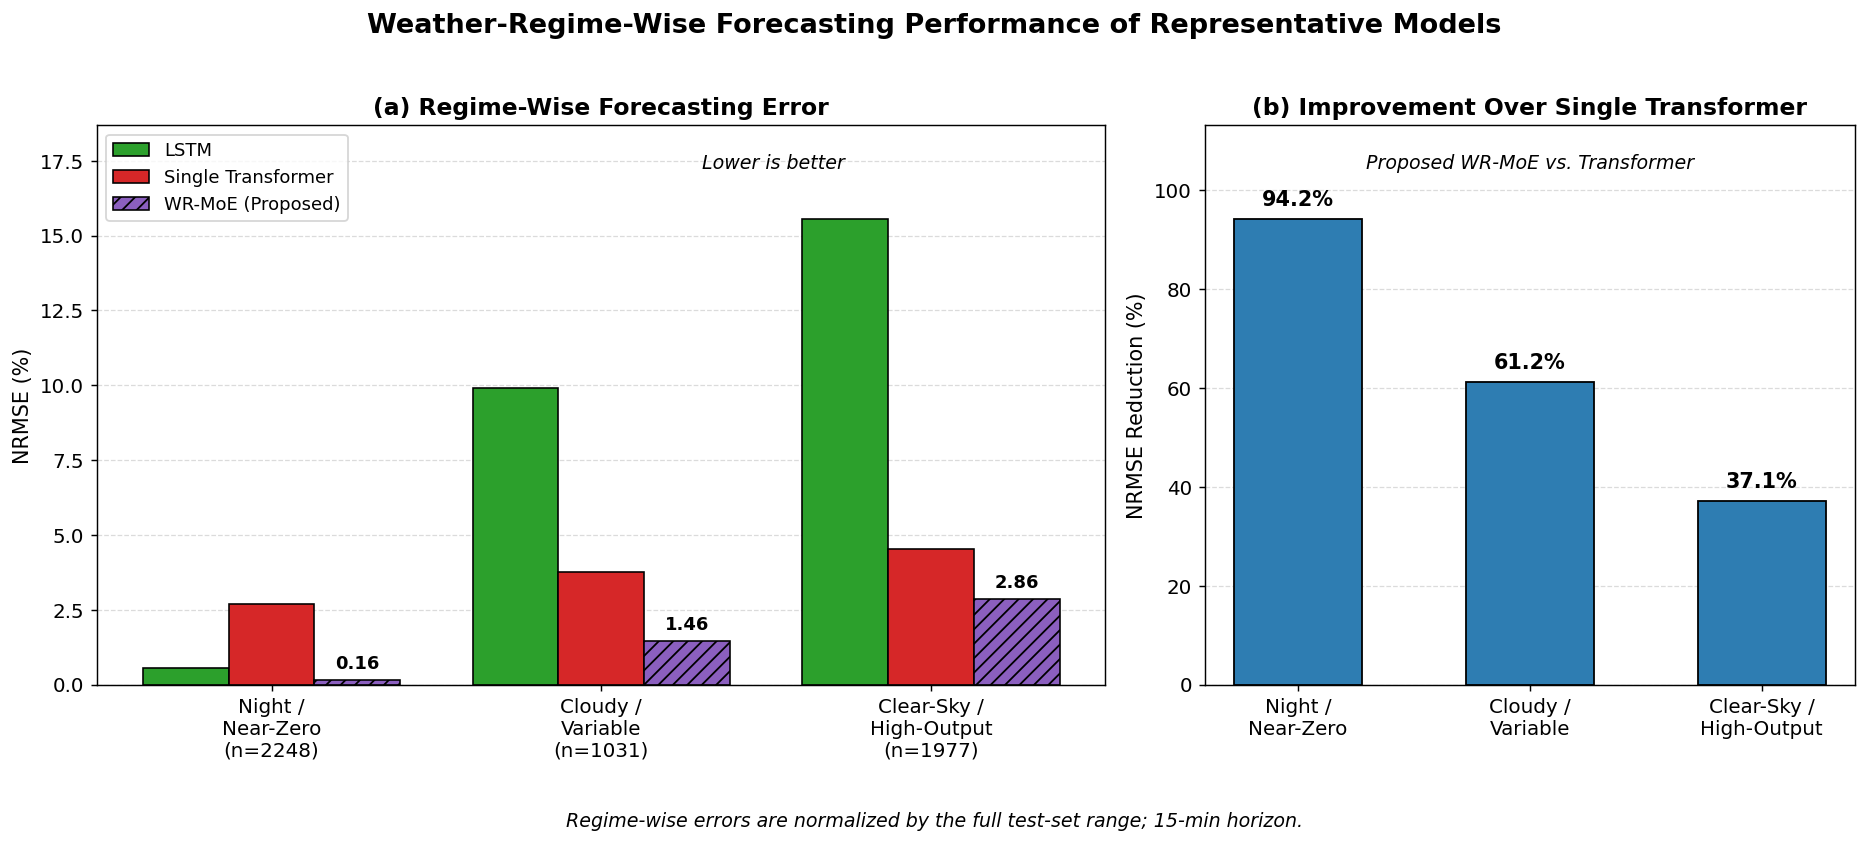

saved outputs/Fig6_weather_regime_wise_performance.png


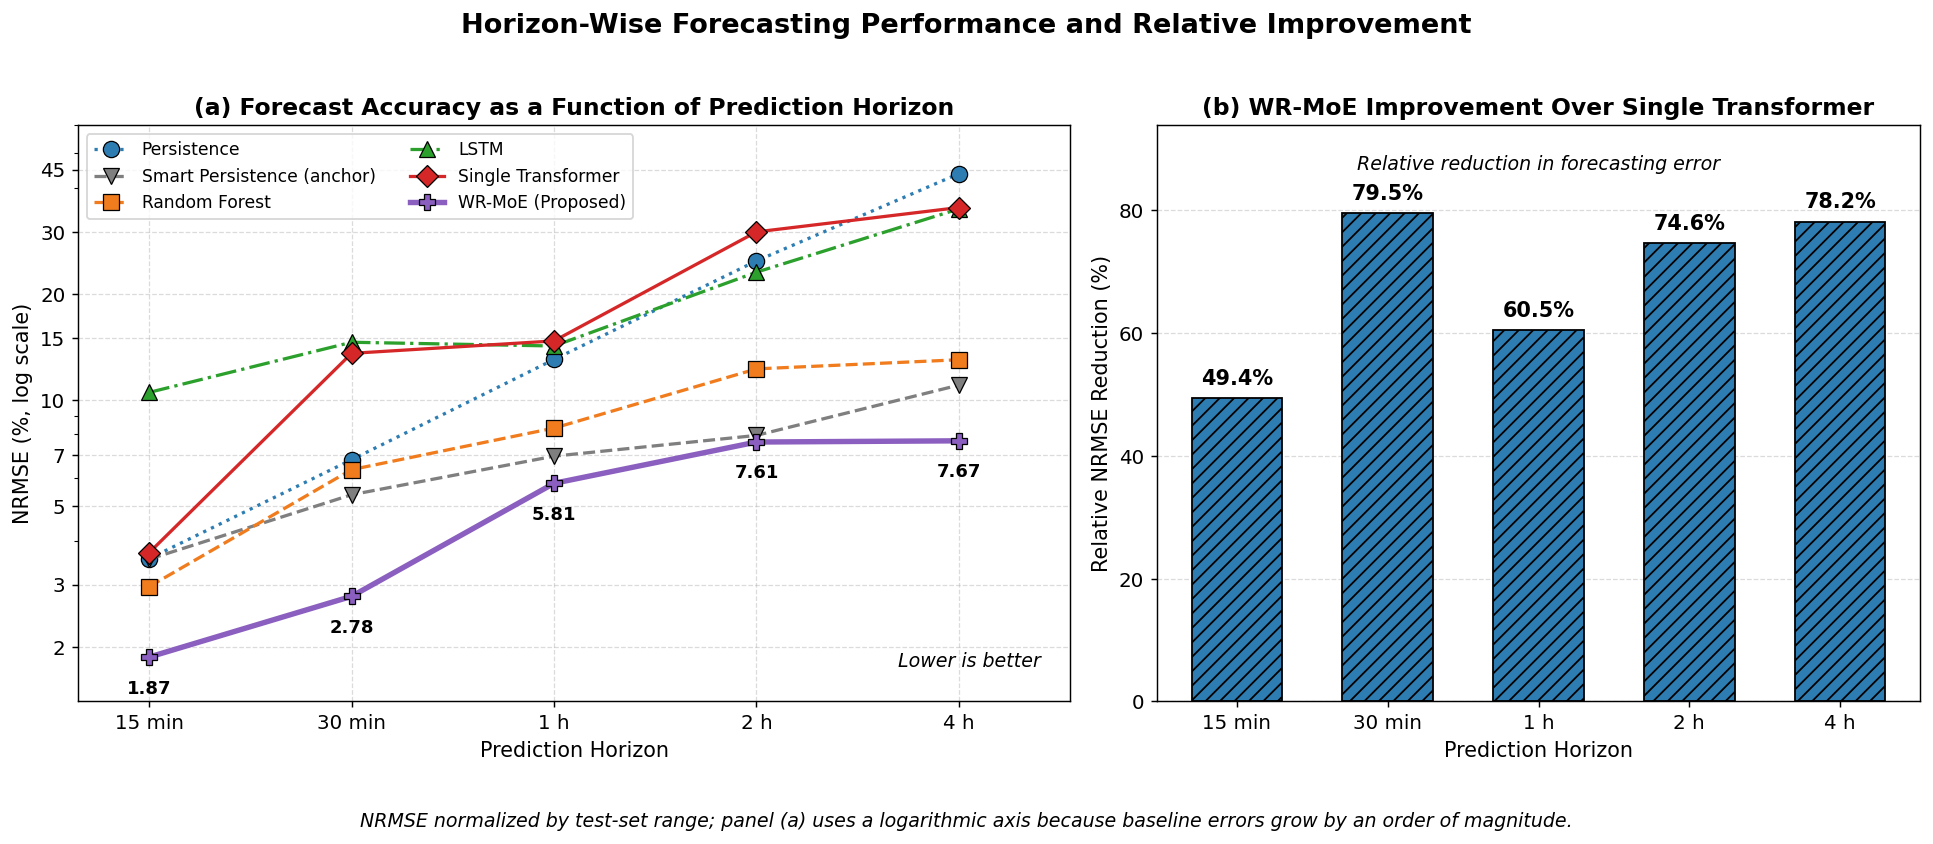

saved outputs/Fig8_forecast_accuracy_vs_horizon.png
Fig 7 skipped: ./moet_test_predictions.npz not found. Add the 3-line dump patch inside main() (see instructions) and re-run the 15-min horizon so per-sample predictions are saved. Fig. 7 is a distribution plot and cannot be produced from summary metrics alone.


In [9]:


import os, json
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.lines import Line2D

RESULTS_PATH = "./results.json"
PRED_PATH    = "./moet_test_predictions.npz"   # written by the Fig-7 patch
FIG_DIR      = "outputs"
os.makedirs(FIG_DIR, exist_ok=True)

R = json.load(open(RESULTS_PATH))
HORIZONS = ["15 min", "30 min", "1 h", "2 h", "4 h"]

# ---- IEEE-ish styling -------------------------------------------------------
plt.rcParams.update({
    "figure.dpi": 130, "savefig.dpi": 400,
    "font.family": "DejaVu Sans", "font.size": 11,
    "axes.titlesize": 13, "axes.titleweight": "bold",
    "axes.labelsize": 11.5, "axes.grid": True,
    "grid.linestyle": "--", "grid.alpha": 0.45, "grid.linewidth": 0.7,
    "axes.axisbelow": True, "legend.frameon": True, "legend.fontsize": 10,
})
C_BAR   = "#2E7DB2"     # baseline blue
C_PROP  = "#2E7DB2"     # proposed (hatched)
PALETTE = ["#2E7DB2", "#F07C1E", "#2CA02C", "#D62728", "#8B5FBF"]

# ---- regime ordering: identical rule to the Section-11 table builder --------
_prof   = R["meta"]["regime_profile"]
_order  = sorted(_prof.keys(), key=lambda k: _prof[k]["pv_actual_norm"])
REGIME_KEYS   = _order                                   # night, cloudy, clear
REGIME_LABELS = ["Night /\nNear-Zero", "Cloudy /\nVariable", "Clear-Sky /\nHigh-Output"]

def m(model, horizon, field):
    return float(R["horizons"][horizon]["metrics"][model][field])

def avg(model, field):
    """Mean across all five horizons -- the Table-III convention."""
    return float(np.mean([m(model, h, field) for h in HORIZONS]))

def _annotate(ax, bars, fmt="{:.2f}", bold_last=True, pad=0.012):
    top = max(b.get_height() for b in bars)
    for i, b in enumerate(bars):
        last = bold_last and i == len(bars) - 1
        ax.text(b.get_x() + b.get_width() / 2, b.get_height() + pad * top,
                fmt.format(b.get_height()), ha="center", va="bottom",
                fontsize=9.5, rotation=90,
                fontweight="bold" if last else "normal")


# =============================================================================
# FIGURE 5 -- Overall forecasting performance comparison
#   Each bar = that model's metric averaged over the five horizons.
# =============================================================================
def plot_fig5(save=f"{FIG_DIR}/Fig5_overall_forecasting_performance.png"):
    models = ["Persistence", "Smart Persistence (anchor)", "SVR", "RF",
              "LSTM", "GRU", "Transformer", "WR-MoE-Transformer"]
    disp   = ["Persistence", "Smart\nPersistence", "SVR", "Random\nForest",
              "LSTM", "GRU", "Transformer", "WR-MoE\n(Proposed)"]

    panels = [("nRMSE_range", "NRMSE", "Normalized Error (%)", "Lower is better"),
              ("nMAE_range",  "NMAE",  "Normalized Error (%)", "Lower is better"),
              ("R2",          r"$R^2$", r"Coefficient of Determination ($R^2$)", "Higher is better")]

    fig, axes = plt.subplots(1, 3, figsize=(15.5, 5.6))
    for ax, (field, title, ylab, hint) in zip(axes, panels):
        vals = [avg(mm, field) for mm in models]
        bars = ax.bar(range(len(models)), vals, color=C_BAR,
                      edgecolor="black", linewidth=1.0, width=0.72)
        bars[-1].set_hatch("///"); bars[-1].set_facecolor("white")
        bars[-1].set_edgecolor("black")

        lo, hi = min(vals), max(vals)
        span = hi - lo if hi > lo else abs(hi) + 1e-6
        if field == "R2":
            ax.set_ylim(lo - 0.18 * span, hi + 0.22 * span)
        else:
            ax.set_ylim(0, hi * 1.24)
        _annotate(ax, bars, "{:.2f}" if field != "R2" else "{:.3f}")

        ax.set_title(title); ax.set_ylabel(ylab)
        ax.set_xticks(range(len(models)))
        ax.set_xticklabels(disp, rotation=40, ha="right", fontsize=9.5)
        ax.text(0.5, 0.955, hint, transform=ax.transAxes, ha="center",
                va="top", fontsize=10, style="italic")
        ax.grid(axis="x", visible=False)

    fig.legend(handles=[Patch(facecolor="white", edgecolor="black", hatch="///",
                              label="Proposed WR-MoE-Transformer")],
               loc="upper center", bbox_to_anchor=(0.5, 0.995), ncol=1)
    fig.suptitle("Overall Forecasting Performance Comparison Across Representative Models",
                 fontsize=15, fontweight="bold", y=1.075)
    fig.text(0.5, -0.11, "Values are averaged over the five forecast horizons "
             "(15 min - 4 h) on the held-out test set.",
             ha="center", fontsize=10.5, style="italic")
    fig.tight_layout(rect=[0, 0, 1, 0.94])
    fig.savefig(save, bbox_inches="tight"); plt.show()
    print("saved", save)


# =============================================================================
# FIGURE 6 -- Weather-regime-wise performance (15-min headline horizon)
# =============================================================================
def plot_fig6(save=f"{FIG_DIR}/Fig6_weather_regime_wise_performance.png"):
    rt = R["regime_table"]
    models = ["LSTM", "Transformer", "WR-MoE-Transformer"]
    disp   = ["LSTM", "Single Transformer", "WR-MoE (Proposed)"]
    cols   = [PALETTE[2], PALETTE[3], PALETTE[4]]

    vals = {mm: [float(rt[k][mm]["nRMSE_range"]) for k in REGIME_KEYS] for mm in models}
    n_s  = [rt[k]["samples"] for k in REGIME_KEYS]

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14.5, 5.8),
                                   gridspec_kw={"width_ratios": [1.55, 1]})
    x, w = np.arange(3), 0.26
    for i, (mm, d, c) in enumerate(zip(models, disp, cols)):
        off = (i - 1) * w
        b = ax1.bar(x + off, vals[mm], w, label=d, color=c,
                    edgecolor="black", linewidth=0.9)
        if mm == "WR-MoE-Transformer":
            for bb in b: bb.set_hatch("///")
            for bb, v in zip(b, vals[mm]):
                ax1.text(bb.get_x() + bb.get_width() / 2, v + 0.25, f"{v:.2f}",
                         ha="center", va="bottom", fontsize=10, fontweight="bold")

    ax1.set_xticks(x)
    ax1.set_xticklabels([f"{l}\n(n={n})" for l, n in zip(REGIME_LABELS, n_s)])
    ax1.set_ylabel("NRMSE (%)")
    ax1.set_title("(a) Regime-Wise Forecasting Error")
    ax1.set_ylim(0, max(max(v) for v in vals.values()) * 1.20)
    ax1.legend(loc="upper left"); ax1.grid(axis="x", visible=False)
    ax1.text(0.60, 0.95, "Lower is better", transform=ax1.transAxes,
             fontsize=10.5, style="italic", va="top")

    imp = [(t - w_) / t * 100 for t, w_ in zip(vals["Transformer"], vals["WR-MoE-Transformer"])]
    b2 = ax2.bar(x, imp, 0.55, color=C_BAR, edgecolor="black", linewidth=1.0)
    for bb, v in zip(b2, imp):
        ax2.text(bb.get_x() + bb.get_width() / 2, v + max(imp) * 0.02, f"{v:.1f}%",
                 ha="center", va="bottom", fontsize=11.5, fontweight="bold")
    ax2.set_xticks(x); ax2.set_xticklabels(REGIME_LABELS)
    ax2.set_ylabel("NRMSE Reduction (%)")
    ax2.set_title("(b) Improvement Over Single Transformer")
    ax2.set_ylim(0, max(imp) * 1.20); ax2.grid(axis="x", visible=False)
    ax2.text(0.5, 0.95, "Proposed WR-MoE vs. Transformer", transform=ax2.transAxes,
             ha="center", va="top", fontsize=10.5, style="italic")

    fig.suptitle("Weather-Regime-Wise Forecasting Performance of Representative Models",
                 fontsize=15, fontweight="bold", y=1.02)
    fig.text(0.5, -0.06, "Regime-wise errors are normalized by the full test-set range; "
             "15-min horizon.", ha="center", fontsize=10.5, style="italic")
    fig.tight_layout(); fig.savefig(save, bbox_inches="tight"); plt.show()
    print("saved", save)


# =============================================================================
# FIGURE 8 -- Accuracy vs. prediction horizon  (+ relative improvement)
# =============================================================================
def plot_fig8(save=f"{FIG_DIR}/Fig8_forecast_accuracy_vs_horizon.png"):
    series = [("Persistence",                "o", ":",   PALETTE[0]),
              ("Smart Persistence (anchor)", "v", "--",  "#7F7F7F"),
              ("RF",                         "s", "--",  PALETTE[1]),
              ("LSTM",                       "^", "-.",  PALETTE[2]),
              ("Transformer",                "D", "-",   PALETTE[3]),
              ("WR-MoE-Transformer",         "P", "-",   PALETTE[4])]
    names = {"RF": "Random Forest", "Transformer": "Single Transformer",
             "WR-MoE-Transformer": "WR-MoE (Proposed)"}

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5.8),
                                   gridspec_kw={"width_ratios": [1.3, 1]})
    x = np.arange(len(HORIZONS))
    for mm, mk, ls, c in series:
        y = [m(mm, h, "nRMSE_range") for h in HORIZONS]
        lw = 3.0 if mm == "WR-MoE-Transformer" else 1.8
        ax1.plot(x, y, marker=mk, linestyle=ls, color=c, linewidth=lw,
                 markersize=9, markeredgecolor="black", markeredgewidth=0.7,
                 label=names.get(mm, mm))
        if mm == "WR-MoE-Transformer":
            for xi, yi in zip(x, y):
                ax1.annotate(f"{yi:.2f}", (xi, yi), textcoords="offset points",
                             xytext=(0, -20), ha="center", fontsize=10,
                             fontweight="bold")
    ax1.set_yscale("log")
    ax1.set_yticks([2, 3, 5, 7, 10, 15, 20, 30, 45])
    ax1.get_yaxis().set_major_formatter(plt.ScalarFormatter())
    ax1.get_yaxis().set_minor_formatter(plt.NullFormatter())
    ax1.set_ylim(1.4, 60)
    ax1.set_xlim(-0.35, len(HORIZONS) - 0.45)
    ax1.set_xticks(x); ax1.set_xticklabels(HORIZONS)
    ax1.set_xlabel("Prediction Horizon"); ax1.set_ylabel("NRMSE (%, log scale)")
    ax1.set_title("(a) Forecast Accuracy as a Function of Prediction Horizon")
    ax1.legend(loc="upper left", ncol=2, fontsize=9.5)
    ax1.text(0.97, 0.06, "Lower is better", transform=ax1.transAxes,
             ha="right", fontsize=10.5, style="italic")

    imp = [(m("Transformer", h, "nRMSE_range") - m("WR-MoE-Transformer", h, "nRMSE_range"))
           / m("Transformer", h, "nRMSE_range") * 100 for h in HORIZONS]
    b = ax2.bar(x, imp, 0.6, color=C_BAR, edgecolor="black",
                linewidth=1.0, hatch="///")
    for bb, v in zip(b, imp):
        ax2.text(bb.get_x() + bb.get_width() / 2, v + max(imp) * 0.02, f"{v:.1f}%",
                 ha="center", va="bottom", fontsize=11.5, fontweight="bold")
    ax2.set_xticks(x); ax2.set_xticklabels(HORIZONS)
    ax2.set_xlabel("Prediction Horizon"); ax2.set_ylabel("Relative NRMSE Reduction (%)")
    ax2.set_title("(b) WR-MoE Improvement Over Single Transformer")
    ax2.set_ylim(0, max(imp) * 1.18); ax2.grid(axis="x", visible=False)
    ax2.text(0.5, 0.95, "Relative reduction in forecasting error",
             transform=ax2.transAxes, ha="center", va="top",
             fontsize=10.5, style="italic")

    fig.suptitle("Horizon-Wise Forecasting Performance and Relative Improvement",
                 fontsize=15, fontweight="bold", y=1.02)
    fig.text(0.5, -0.06, "NRMSE normalized by test-set range; panel (a) uses a "
             "logarithmic axis because baseline errors grow by an order of magnitude.",
             ha="center", fontsize=10.5, style="italic")
    fig.tight_layout(); fig.savefig(save, bbox_inches="tight"); plt.show()
    print("saved", save)


# =============================================================================
# FIGURE 7 -- Error distribution across weather regimes
#   Requires ./moet_test_predictions.npz  (see patch instructions in chat).
# =============================================================================
def plot_fig7(save=f"{FIG_DIR}/Fig7_error_distribution_across_regimes.png",
              pred_path=PRED_PATH):
    if not os.path.exists(pred_path):
        raise FileNotFoundError(
            f"{pred_path} not found. Add the 3-line dump patch inside main() "
            "(see instructions) and re-run the 15-min horizon so per-sample "
            "predictions are saved. Fig. 7 is a distribution plot and cannot be "
            "produced from summary metrics alone.")
    d = np.load(pred_path)
    y_true, y_moe, y_tr, regimes = d["y_true"], d["y_moe"], d["y_transf"], d["regimes"]
    err_tr, err_moe = np.abs(y_true - y_tr), np.abs(y_true - y_moe)

    titles = ["(a) Night / Near-Zero Regime", "(b) Cloudy / Variable Regime",
              "(c) Clear-Sky / High-Output Regime"]
    fig, axes = plt.subplots(1, 3, figsize=(15.5, 6.0))
    for ax, key, title in zip(axes, REGIME_KEYS, titles):
        msk = regimes == int(key)
        data = [err_tr[msk], err_moe[msk]]
        bp = ax.boxplot(data, widths=0.55, patch_artist=True, showmeans=True,
                        meanprops=dict(marker="D", markerfacecolor="white",
                                       markeredgecolor="black", markersize=8),
                        medianprops=dict(color="black", linewidth=2.2),
                        flierprops=dict(marker="o", markerfacecolor="none",
                                        markersize=4, alpha=0.55))
        bp["boxes"][0].set(facecolor="#D9D9D9", edgecolor="black")
        bp["boxes"][1].set(facecolor="white", edgecolor="black", hatch="///")
        for i, dd in enumerate(data, start=1):
            jit = np.random.normal(i, 0.055, size=min(len(dd), 400))
            ax.scatter(jit, np.random.choice(dd, size=len(jit), replace=False),
                       s=5, color="gray", alpha=0.25, zorder=1)
            med = np.median(dd)
            ax.text(i, med, f"Median={med:.4f}", ha="center", va="bottom",
                    fontsize=9.5, fontweight="bold" if i == 2 else "normal",
                    bbox=dict(boxstyle="round,pad=0.2", fc="white", alpha=0.75, lw=0))
        ax.set_xticklabels(["Single\nTransformer", "WR-MoE\n(Proposed)"])
        ax.set_title(title); ax.grid(axis="x", visible=False)
        hi = np.percentile(np.concatenate(data), 99.5)
        ax.set_ylim(-0.02 * hi, hi * 1.25)
    axes[0].set_ylabel("Absolute Prediction Error (p.u.)")

    fig.legend(handles=[Line2D([0], [0], color="black", lw=2.2, label="Median"),
                        Line2D([0], [0], marker="D", color="black", lw=0,
                               markerfacecolor="white", markersize=9, label="Mean"),
                        Patch(facecolor="#D9D9D9", edgecolor="black", label="Single Transformer"),
                        Patch(facecolor="white", edgecolor="black", hatch="///",
                              label="WR-MoE (Proposed)")],
               loc="upper center", bbox_to_anchor=(0.5, 0.99), ncol=4)
    fig.suptitle("Distribution of Absolute Forecasting Errors Across Weather Regimes",
                 fontsize=15, fontweight="bold", y=1.075)
    fig.text(0.5, -0.05, "Box limits indicate the interquartile range; whiskers extend to "
             "1.5xIQR; diamonds denote mean errors; individual markers represent outliers.",
             ha="center", fontsize=10.5, style="italic")
    fig.tight_layout(rect=[0, 0, 1, 0.93])
    fig.savefig(save, bbox_inches="tight"); plt.show()
    print("saved", save)


if __name__ == "__main__":
    plot_fig5(); plot_fig6(); plot_fig8()
    try:
        plot_fig7()
    except FileNotFoundError as e:
        print("Fig 7 skipped:", e)


# =============================================================================
# FIGURE 9 -- Component-wise ablation analysis   (results.json only)
#   Stages map onto results["ablation_table"]:
#     Base Transformer                -> Global Transformer
#     + Multi-Expert Capacity         -> Static Multi-Expert Transformer
#     + Weather-Regime Specialization -> Regime-Specialized Experts (Static)
#     + Dynamic Gating (Full WR-MoE)  -> Full WR-MoE-Transformer
# =============================================================================
ABLATION_STAGES = [
    ("Global Transformer",                  "Base\nTransformer"),
    ("Static Multi-Expert Transformer",     "+ Multi-Expert\nCapacity"),
    ("Regime-Specialized Experts (Static)", "+ Weather-Regime\nSpecialization"),
    ("Full WR-MoE-Transformer",             "+ Dynamic Gating\n(Full WR-MoE)"),
]

def plot_fig9(save=f"{FIG_DIR}/Fig9_component_wise_ablation.png"):
    A = R["ablation_table"]
    keys   = [k for k, _ in ABLATION_STAGES]
    labels = [l for _, l in ABLATION_STAGES]
    nrmse  = [float(A[k]["nRMSE_range"]) for k in keys]
    nmae   = [float(A[k]["nMAE_range"])  for k in keys]
    r2     = [float(A[k]["R2"])          for k in keys]
    params = [int(A[k]["params"])        for k in keys]

    fig, (ax1, ax3) = plt.subplots(1, 2, figsize=(15.5, 6.2),
                                   gridspec_kw={"width_ratios": [1.45, 1]})
    x, w = np.arange(4), 0.33
    b1 = ax1.bar(x - w / 2, nrmse, w, label="NRMSE", color=PALETTE[0],
                 edgecolor="black", linewidth=1.0)
    b2 = ax1.bar(x + w / 2, nmae,  w, label="NMAE",  color=PALETTE[1],
                 edgecolor="black", linewidth=1.0)
    for bb in list(b1) + list(b2):
        bb.set_hatch("")
    for bb in [b1[-1], b2[-1]]:
        bb.set_hatch("///")
    for bb, v in zip(list(b1) + list(b2), nrmse + nmae):
        ax1.text(bb.get_x() + bb.get_width() / 2, v + max(nrmse) * 0.02,
                 f"{v:.2f}", ha="center", va="bottom", fontsize=10)
    ax1.set_ylabel("Normalized Error (%)")
    ax1.set_ylim(0, max(nrmse) * 1.22)
    ax1.set_xticks(x)
    ax1.set_xticklabels([f"{l}\n({p:,} params)" for l, p in zip(labels, params)],
                        fontsize=9.5)
    ax1.set_title("(a) Progressive Component-Wise Ablation Performance")
    ax1.grid(axis="x", visible=False)

    ax2 = ax1.twinx()
    ax2.plot(x, r2, marker="D", color="#333333", linewidth=2.0, markersize=9,
             markerfacecolor="white", markeredgecolor="black", label=r"$R^2$")
    for xi, v in zip(x, r2):
        dy = 11 if xi < len(x) - 1 else -22
        ax2.annotate(f"{v:.4f}", (xi, v), textcoords="offset points",
                     xytext=(0, dy), ha="center", fontsize=9.5)
    ax2.set_ylabel(r"$R^2$")
    ax2.set_ylim(min(r2) - 0.012, max(r2) + 0.010)
    ax2.grid(False)

    h1, l1 = ax1.get_legend_handles_labels()
    h2, l2 = ax2.get_legend_handles_labels()
    ax1.legend(h1 + h2, l1 + l2, loc="center right", fontsize=10)
    ax1.text(0.33, 0.965, "Lower is better", transform=ax1.transAxes,
             fontsize=10.5, style="italic", va="top")

    inc = [(nrmse[i - 1] - nrmse[i]) / nrmse[i - 1] * 100 for i in range(1, 4)]
    total = (nrmse[0] - nrmse[-1]) / nrmse[0] * 100
    b3 = ax3.bar(np.arange(3), inc, 0.55, color=PALETTE[0],
                 edgecolor="black", linewidth=1.0, hatch="///")
    for bb, v in zip(b3, inc):
        ax3.text(bb.get_x() + bb.get_width() / 2, v + max(inc) * 0.02, f"{v:.1f}%",
                 ha="center", va="bottom", fontsize=12, fontweight="bold")
    ax3.set_xticks(np.arange(3))
    ax3.set_xticklabels(["Multi-Expert\nCapacity", "Weather-Regime\nSpecialization",
                         "Dynamic\nGating"])
    ax3.set_ylabel("Incremental NRMSE Reduction (%)")
    ax3.set_title("(b) Incremental Contribution of Proposed Components")
    ax3.set_ylim(0, max(inc) * 1.22); ax3.grid(axis="x", visible=False)
    ax3.text(0.97, 0.93, f"Total reduction vs.\nBase Transformer: {total:.1f}%",
             transform=ax3.transAxes, ha="right", va="top", fontsize=11,
             bbox=dict(boxstyle="round,pad=0.45", fc="white", ec="black", lw=1.2))

    fig.suptitle("Component-Wise Ablation Analysis of the Proposed WR-MoE Transformer",
                 fontsize=15, fontweight="bold", y=1.02)
    fig.text(0.5, -0.09, "All variants trained under identical settings at the 15-min "
             "horizon; each stage adds one component to the one on its left.",
             ha="center", fontsize=10.5, style="italic")
    fig.tight_layout(); fig.savefig(save, bbox_inches="tight"); plt.show()
    print("saved", save)


# =============================================================================
# FIGURE 10 -- Dynamic expert gating behaviour
#   Panel (c) needs results.json only.
#   Panels (a)+(b) need ./moet_gating_trace.npz  (see the dump patch).
# =============================================================================
SHORT_LABELS = ["Night", "Cloudy", "Clear"]     # aligned with REGIME_KEYS order

def _expert_names():
    """Name each expert after the regime whose gate weight it dominates."""
    ec = R["expert_contribution_table"]
    n = len(ec[REGIME_KEYS[0]])
    names = {}
    for e in range(n):
        key = f"Expert {e+1}"
        best = int(np.argmax([ec[k][key] for k in REGIME_KEYS]))
        names[e] = f"Expert {e+1} ({SHORT_LABELS[best]})"
    return [names[e] for e in range(n)]


def plot_fig10(save=f"{FIG_DIR}/Fig10_dynamic_expert_gating.png",
               trace_path="./moet_gating_trace.npz", window=192, seed=0):
    if not os.path.exists(trace_path):
        raise FileNotFoundError(
            f"{trace_path} not found. Add the gating-trace dump inside main() "
            "(15-min horizon block) and re-run that horizon.")
    d = np.load(trace_path, allow_pickle=True)
    gate_w, regimes, ghi = d["gate_w"], d["regimes"], d["ghi"]
    n_exp = gate_w.shape[1]
    enames = _expert_names()
    ecols  = [PALETTE[0], PALETTE[1], PALETTE[2], PALETTE[3], PALETTE[4]][:n_exp]
    estyle = ["-", "--", "-."][:n_exp] * 3
    emark  = ["o", "s", "^", "D", "P"][:n_exp]

    # pick the contiguous window containing the most regime transitions
    best_s, best_score = 0, -1
    for s in range(0, len(regimes) - window, window // 4):
        seg = regimes[s:s + window]
        score = np.sum(np.diff(seg) != 0) + 3 * len(np.unique(seg))
        if score > best_score:
            best_s, best_score = s, score
    sl = slice(best_s, best_s + window)
    t = np.arange(window)
    seg_r, seg_ghi, seg_w = regimes[sl], ghi[sl], gate_w[sl]

    key2pos = {int(k): i for i, k in enumerate(REGIME_KEYS)}
    shades  = ["#E8E8E8", "#CFCFCF", "#F7F7F7"]

    fig = plt.figure(figsize=(15.5, 12.5))
    gs = fig.add_gridspec(3, 1, height_ratios=[1.0, 1.25, 1.0], hspace=0.42)
    axA, axB, axC = (fig.add_subplot(gs[i]) for i in range(3))

    # ---- (a) irradiance with regime bands ----
    bounds = [0] + list(np.where(np.diff(seg_r) != 0)[0] + 1) + [window]
    for i in range(len(bounds) - 1):
        a, b = bounds[i], bounds[i + 1]
        pos = key2pos[int(seg_r[a])]
        axA.axvspan(a, b, color=shades[pos], zorder=0)
        if i:
            for ax in (axA, axB):
                ax.axvline(a, color="black", linestyle="--", linewidth=1.1, zorder=3)
    axA.plot(t, seg_ghi, color="black", linewidth=1.6, zorder=2)
    axA.set_ylabel("Irradiance\n(W/m$^2$)")
    axA.set_title("(a) Observed Weather-Regime Transitions (test set)")
    axA.set_xlim(0, window - 1); axA.grid(axis="x", visible=False)
    # redraw labels now that ylim is settled
    for i in range(len(bounds) - 1):
        a, b = bounds[i], bounds[i + 1]
        if b - a > window * 0.04:
            axA.text((a + b) / 2, axA.get_ylim()[1] * 0.93,
                     SHORT_LABELS[key2pos[int(seg_r[a])]],
                     ha="center", va="top", fontsize=11, fontweight="bold")

    # ---- (b) gate weights ----
    for i in range(len(bounds) - 1):
        axB.axvspan(bounds[i], bounds[i + 1],
                    color=shades[key2pos[int(seg_r[bounds[i]])]], alpha=0.5, zorder=0)
    for e in range(n_exp):
        axB.plot(t, seg_w[:, e], color=ecols[e], linestyle=estyle[e], linewidth=2.0,
                 marker=emark[e], markevery=max(window // 14, 1), markersize=7,
                 markerfacecolor="white", markeredgecolor=ecols[e],
                 label=enames[e], zorder=2)
    axB.set_ylabel("Gating Weight $g_k(t)$")
    axB.set_xlabel("Time Index (15-min samples)")
    axB.set_title("(b) Dynamic Expert Selection and Weight Adaptation")
    axB.set_ylim(-0.03, 1.12); axB.set_xlim(0, window - 1)
    axB.legend(loc="upper center", ncol=n_exp, fontsize=10)
    axB.grid(axis="x", visible=False)

    # ---- (c) mean gate weight per regime (from results.json) ----
    ec = R["expert_contribution_table"]
    M = np.array([[ec[k][f"Expert {e+1}"] for e in range(n_exp)] for k in REGIME_KEYS])
    im = axC.imshow(M, cmap="Greys", vmin=0, vmax=1, aspect="auto")
    for i in range(M.shape[0]):
        for j in range(M.shape[1]):
            axC.text(j, i, f"{M[i, j]:.2f}", ha="center", va="center",
                     fontsize=13, fontweight="bold",
                     color="white" if M[i, j] > 0.55 else "black")
    axC.set_xticks(range(n_exp)); axC.set_xticklabels(enames, fontsize=10.5)
    axC.set_yticks(range(len(REGIME_KEYS)))
    axC.set_yticklabels([l.replace("\n", " ") for l in REGIME_LABELS], fontsize=10.5)
    axC.set_ylabel("Observed Weather Regime")
    axC.set_title("(c) Average Gating Allocation Conditioned on Weather Regime")
    axC.grid(False)
    cb = fig.colorbar(im, ax=axC, fraction=0.025, pad=0.015)
    cb.set_label("Mean Gating Weight")

    fig.suptitle("Dynamic Expert Gating Behaviour of the Proposed "
                 "Weather-Regime-Aware Mixture-of-Experts Framework",
                 fontsize=15, fontweight="bold", y=0.975)
    fig.text(0.5, 0.048,
             r"Dynamic fusion:  $\hat{y}_{t+h}=\sum_{k=1}^{K} g_k(\mathbf{x}_t)\,"
             r"\hat{y}^{(k)}_{t+h}$,   $\sum_{k=1}^{K} g_k(\mathbf{x}_t)=1$",
             ha="center", fontsize=13,
             bbox=dict(boxstyle="round,pad=0.5", fc="white", ec="black", lw=1.2))
    fig.text(0.5, 0.018, "Gating weights and regime assignments are taken from the "
             "held-out test set at the 15-min horizon.",
             ha="center", fontsize=10.5, style="italic")
    fig.savefig(save, bbox_inches="tight"); plt.show()
    print("saved", save)

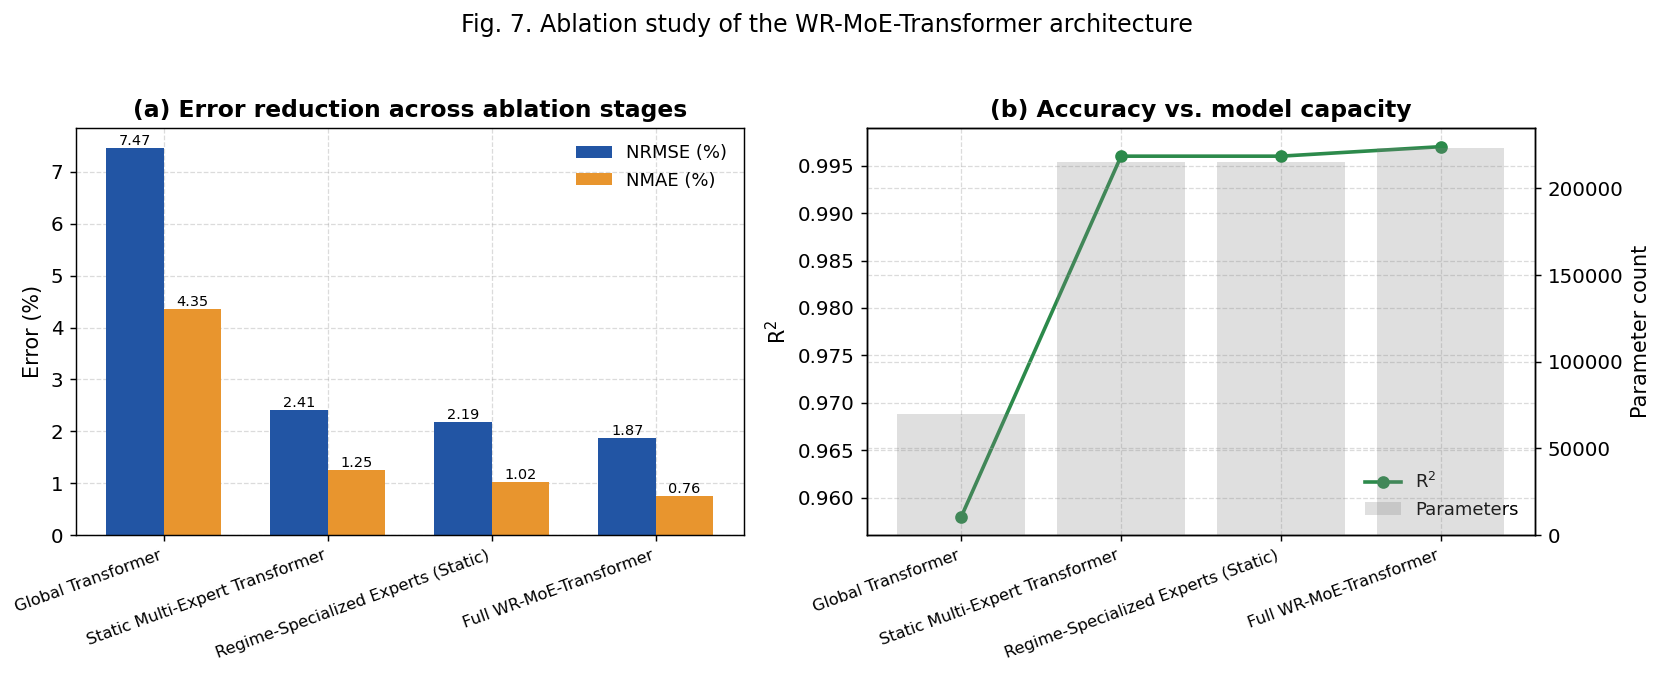

In [12]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

with open("table_data.json") as f:
    tdata = json.load(f)

OUT_DIR = "outputs"
import os; os.makedirs(OUT_DIR, exist_ok=True)

def plot_fig7_ablation(tdata, save_path):
    rows = tdata['table7']
    names = [r['name'] for r in rows]
    nrmse = [r['NRMSE'] for r in rows]
    nmae = [r['NMAE'] for r in rows]
    r2 = [r['R2'] for r in rows]
    params = [int(r['params'].replace(',', '')) for r in rows]

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))
    x = np.arange(len(names))
    w = 0.35
    b1 = ax1.bar(x - w/2, nrmse, width=w, label='NRMSE (%)', color='#2255a4')
    b2 = ax1.bar(x + w/2, nmae, width=w, label='NMAE (%)', color='#e8952e')
    ax1.set_xticks(x)
    ax1.set_xticklabels(names, rotation=20, ha='right', fontsize=9)
    ax1.set_ylabel("Error (%)")
    ax1.set_title("(a) Error reduction across ablation stages")
    ax1.legend(frameon=False)
    for b in list(b1) + list(b2):
        ax1.annotate(f"{b.get_height():.2f}", (b.get_x() + b.get_width()/2, b.get_height()),
                     ha='center', va='bottom', fontsize=8)

    ax2b = ax2.twinx()
    l1, = ax2.plot(x, r2, '-o', color='#2c8a4b', lw=2, label='R$^2$')
    b3 = ax2b.bar(x, params, alpha=0.25, color='gray', label='Parameters')
    ax2.set_xticks(x)
    ax2.set_xticklabels(names, rotation=20, ha='right', fontsize=9)
    ax2.set_ylabel("R$^2$")
    ax2b.set_ylabel("Parameter count")
    ax2.set_title("(b) Accuracy vs. model capacity")
    ax2.legend(handles=[l1, b3], frameon=False, loc='lower right')

    fig.suptitle("Fig. 7. Ablation study of the WR-MoE-Transformer architecture", y=1.03)
    fig.tight_layout()
    fig.savefig(save_path, dpi=200, bbox_inches='tight')
    plt.show()

plot_fig7_ablation(tdata, f"{OUT_DIR}/Fig_ablation.png")

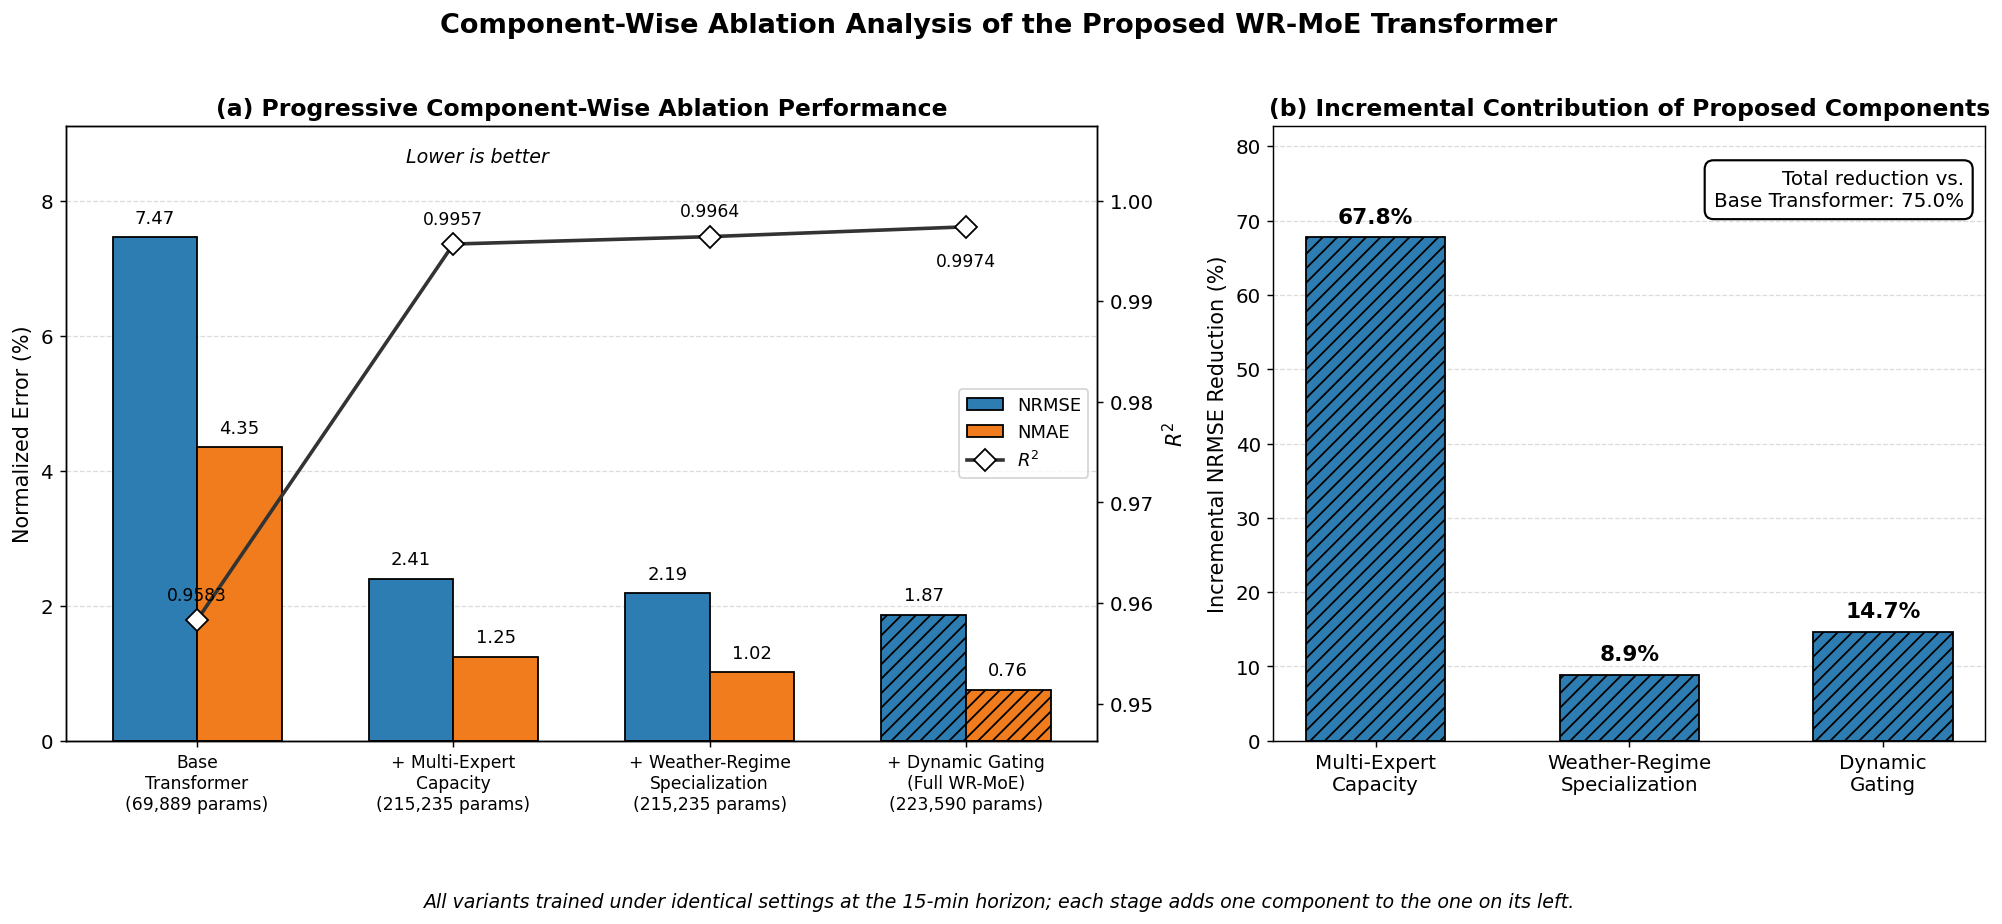

saved figures/Fig9_component_wise_ablation.png
skipped: ./moet_test_predictions.npz not found. Add the 3-line dump patch inside main() (see instructions) and re-run the 15-min horizon so per-sample predictions are saved. Fig. 7 is a distribution plot and cannot be produced from summary metrics alone.
skipped: ./moet_gating_trace.npz not found. Add the gating-trace dump inside main() (15-min horizon block) and re-run that horizon.


In [13]:
"""
================================================================================
 MoET v15/16 -- PAPER FIGURES 7, 9, 10 FROM ACTUAL EXPERIMENTAL RESULTS
================================================================================
 Paste as new cells at the end of MoET_Model_16.ipynb.

 Fig. 9  -> runs immediately from ./results.json, nothing else needed.
 Fig. 7  -> needs ./moet_test_predictions.npz
 Fig. 10 -> needs ./moet_gating_trace.npz

 To produce those two .npz files, add the DUMP PATCH below inside main(), in the
 `if horizon == 1:` block (right after `results["expert_contribution_table"] =
 expert_contrib`), then delete the "15 min" entry from results.json and re-run
 main() so that horizon executes once more:

     np.savez("./moet_test_predictions.npz",
              y_true=np.asarray(ys_test), y_moe=np.asarray(y_pred_moe),
              y_transf=np.asarray(y_pred_transf), y_lstm=np.asarray(y_pred_lstm),
              regimes=np.asarray(regime_test))
     np.savez("./moet_gating_trace.npz",
              gate_w=np.asarray(gate_w_test),
              regimes=np.asarray(regime_test),
              ghi=state["df"]["ghi"].values[idx][test_mask],
              pv_true=np.asarray(y_abs_test))
     log("[H=15 min] saved per-sample predictions + gating trace for Figs. 7/10")
================================================================================
"""

import os, json
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.lines import Line2D

RESULTS_PATH = "./results.json"
PRED_PATH    = "./moet_test_predictions.npz"   # written by the Fig-7 patch
FIG_DIR      = "figures"
os.makedirs(FIG_DIR, exist_ok=True)

R = json.load(open(RESULTS_PATH))
HORIZONS = ["15 min", "30 min", "1 h", "2 h", "4 h"]

# ---- IEEE-ish styling -------------------------------------------------------
plt.rcParams.update({
    "figure.dpi": 130, "savefig.dpi": 400,
    "font.family": "DejaVu Sans", "font.size": 11,
    "axes.titlesize": 13, "axes.titleweight": "bold",
    "axes.labelsize": 11.5, "axes.grid": True,
    "grid.linestyle": "--", "grid.alpha": 0.45, "grid.linewidth": 0.7,
    "axes.axisbelow": True, "legend.frameon": True, "legend.fontsize": 10,
})
C_BAR   = "#2E7DB2"     # baseline blue
C_PROP  = "#2E7DB2"     # proposed (hatched)
PALETTE = ["#2E7DB2", "#F07C1E", "#2CA02C", "#D62728", "#8B5FBF"]

# ---- regime ordering: identical rule to the Section-11 table builder --------
_prof   = R["meta"]["regime_profile"]
_order  = sorted(_prof.keys(), key=lambda k: _prof[k]["pv_actual_norm"])
REGIME_KEYS   = _order                                   # night, cloudy, clear
REGIME_LABELS = ["Night /\nNear-Zero", "Cloudy /\nVariable", "Clear-Sky /\nHigh-Output"]

def m(model, horizon, field):
    return float(R["horizons"][horizon]["metrics"][model][field])

def avg(model, field):
    """Mean across all five horizons -- the Table-III convention."""
    return float(np.mean([m(model, h, field) for h in HORIZONS]))

def _annotate(ax, bars, fmt="{:.2f}", bold_last=True, pad=0.012):
    top = max(b.get_height() for b in bars)
    for i, b in enumerate(bars):
        last = bold_last and i == len(bars) - 1
        ax.text(b.get_x() + b.get_width() / 2, b.get_height() + pad * top,
                fmt.format(b.get_height()), ha="center", va="bottom",
                fontsize=9.5, rotation=90,
                fontweight="bold" if last else "normal")


# =============================================================================
# FIGURE 7 -- Error distribution across weather regimes
#   Requires ./moet_test_predictions.npz  (see patch instructions in chat).
# =============================================================================
def plot_fig7(save=f"{FIG_DIR}/Fig7_error_distribution_across_regimes.png",
              pred_path=PRED_PATH):
    if not os.path.exists(pred_path):
        raise FileNotFoundError(
            f"{pred_path} not found. Add the 3-line dump patch inside main() "
            "(see instructions) and re-run the 15-min horizon so per-sample "
            "predictions are saved. Fig. 7 is a distribution plot and cannot be "
            "produced from summary metrics alone.")
    d = np.load(pred_path)
    y_true, y_moe, y_tr, regimes = d["y_true"], d["y_moe"], d["y_transf"], d["regimes"]
    err_tr, err_moe = np.abs(y_true - y_tr), np.abs(y_true - y_moe)

    titles = ["(a) Night / Near-Zero Regime", "(b) Cloudy / Variable Regime",
              "(c) Clear-Sky / High-Output Regime"]
    fig, axes = plt.subplots(1, 3, figsize=(15.5, 6.0))
    for ax, key, title in zip(axes, REGIME_KEYS, titles):
        msk = regimes == int(key)
        data = [err_tr[msk], err_moe[msk]]
        bp = ax.boxplot(data, widths=0.55, patch_artist=True, showmeans=True,
                        meanprops=dict(marker="D", markerfacecolor="white",
                                       markeredgecolor="black", markersize=8),
                        medianprops=dict(color="black", linewidth=2.2),
                        flierprops=dict(marker="o", markerfacecolor="none",
                                        markersize=4, alpha=0.55))
        bp["boxes"][0].set(facecolor="#D9D9D9", edgecolor="black")
        bp["boxes"][1].set(facecolor="white", edgecolor="black", hatch="///")
        for i, dd in enumerate(data, start=1):
            jit = np.random.normal(i, 0.055, size=min(len(dd), 400))
            ax.scatter(jit, np.random.choice(dd, size=len(jit), replace=False),
                       s=5, color="gray", alpha=0.25, zorder=1)
            med = np.median(dd)
            ax.text(i, med, f"Median={med:.4f}", ha="center", va="bottom",
                    fontsize=9.5, fontweight="bold" if i == 2 else "normal",
                    bbox=dict(boxstyle="round,pad=0.2", fc="white", alpha=0.75, lw=0))
        ax.set_xticklabels(["Single\nTransformer", "WR-MoE\n(Proposed)"])
        ax.set_title(title); ax.grid(axis="x", visible=False)
        hi = np.percentile(np.concatenate(data), 99.5)
        ax.set_ylim(-0.02 * hi, hi * 1.25)
    axes[0].set_ylabel("Absolute Prediction Error (p.u.)")

    fig.legend(handles=[Line2D([0], [0], color="black", lw=2.2, label="Median"),
                        Line2D([0], [0], marker="D", color="black", lw=0,
                               markerfacecolor="white", markersize=9, label="Mean"),
                        Patch(facecolor="#D9D9D9", edgecolor="black", label="Single Transformer"),
                        Patch(facecolor="white", edgecolor="black", hatch="///",
                              label="WR-MoE (Proposed)")],
               loc="upper center", bbox_to_anchor=(0.5, 0.99), ncol=4)
    fig.suptitle("Distribution of Absolute Forecasting Errors Across Weather Regimes",
                 fontsize=15, fontweight="bold", y=1.075)
    fig.text(0.5, -0.05, "Box limits indicate the interquartile range; whiskers extend to "
             "1.5xIQR; diamonds denote mean errors; individual markers represent outliers.",
             ha="center", fontsize=10.5, style="italic")
    fig.tight_layout(rect=[0, 0, 1, 0.93])
    fig.savefig(save, bbox_inches="tight"); plt.show()
    print("saved", save)


# =============================================================================
# FIGURE 9 -- Component-wise ablation analysis   (results.json only)
#   Stages map onto results["ablation_table"]:
#     Base Transformer                -> Global Transformer
#     + Multi-Expert Capacity         -> Static Multi-Expert Transformer
#     + Weather-Regime Specialization -> Regime-Specialized Experts (Static)
#     + Dynamic Gating (Full WR-MoE)  -> Full WR-MoE-Transformer
# =============================================================================
ABLATION_STAGES = [
    ("Global Transformer",                  "Base\nTransformer"),
    ("Static Multi-Expert Transformer",     "+ Multi-Expert\nCapacity"),
    ("Regime-Specialized Experts (Static)", "+ Weather-Regime\nSpecialization"),
    ("Full WR-MoE-Transformer",             "+ Dynamic Gating\n(Full WR-MoE)"),
]

def plot_fig9(save=f"{FIG_DIR}/Fig9_component_wise_ablation.png"):
    A = R["ablation_table"]
    keys   = [k for k, _ in ABLATION_STAGES]
    labels = [l for _, l in ABLATION_STAGES]
    nrmse  = [float(A[k]["nRMSE_range"]) for k in keys]
    nmae   = [float(A[k]["nMAE_range"])  for k in keys]
    r2     = [float(A[k]["R2"])          for k in keys]
    params = [int(A[k]["params"])        for k in keys]

    fig, (ax1, ax3) = plt.subplots(1, 2, figsize=(15.5, 6.2),
                                   gridspec_kw={"width_ratios": [1.45, 1]})
    x, w = np.arange(4), 0.33
    b1 = ax1.bar(x - w / 2, nrmse, w, label="NRMSE", color=PALETTE[0],
                 edgecolor="black", linewidth=1.0)
    b2 = ax1.bar(x + w / 2, nmae,  w, label="NMAE",  color=PALETTE[1],
                 edgecolor="black", linewidth=1.0)
    for bb in list(b1) + list(b2):
        bb.set_hatch("")
    for bb in [b1[-1], b2[-1]]:
        bb.set_hatch("///")
    for bb, v in zip(list(b1) + list(b2), nrmse + nmae):
        ax1.text(bb.get_x() + bb.get_width() / 2, v + max(nrmse) * 0.02,
                 f"{v:.2f}", ha="center", va="bottom", fontsize=10)
    ax1.set_ylabel("Normalized Error (%)")
    ax1.set_ylim(0, max(nrmse) * 1.22)
    ax1.set_xticks(x)
    ax1.set_xticklabels([f"{l}\n({p:,} params)" for l, p in zip(labels, params)],
                        fontsize=9.5)
    ax1.set_title("(a) Progressive Component-Wise Ablation Performance")
    ax1.grid(axis="x", visible=False)

    ax2 = ax1.twinx()
    ax2.plot(x, r2, marker="D", color="#333333", linewidth=2.0, markersize=9,
             markerfacecolor="white", markeredgecolor="black", label=r"$R^2$")
    for xi, v in zip(x, r2):
        dy = 11 if xi < len(x) - 1 else -22
        ax2.annotate(f"{v:.4f}", (xi, v), textcoords="offset points",
                     xytext=(0, dy), ha="center", fontsize=9.5)
    ax2.set_ylabel(r"$R^2$")
    ax2.set_ylim(min(r2) - 0.012, max(r2) + 0.010)
    ax2.grid(False)

    h1, l1 = ax1.get_legend_handles_labels()
    h2, l2 = ax2.get_legend_handles_labels()
    ax1.legend(h1 + h2, l1 + l2, loc="center right", fontsize=10)
    ax1.text(0.33, 0.965, "Lower is better", transform=ax1.transAxes,
             fontsize=10.5, style="italic", va="top")

    inc = [(nrmse[i - 1] - nrmse[i]) / nrmse[i - 1] * 100 for i in range(1, 4)]
    total = (nrmse[0] - nrmse[-1]) / nrmse[0] * 100
    b3 = ax3.bar(np.arange(3), inc, 0.55, color=PALETTE[0],
                 edgecolor="black", linewidth=1.0, hatch="///")
    for bb, v in zip(b3, inc):
        ax3.text(bb.get_x() + bb.get_width() / 2, v + max(inc) * 0.02, f"{v:.1f}%",
                 ha="center", va="bottom", fontsize=12, fontweight="bold")
    ax3.set_xticks(np.arange(3))
    ax3.set_xticklabels(["Multi-Expert\nCapacity", "Weather-Regime\nSpecialization",
                         "Dynamic\nGating"])
    ax3.set_ylabel("Incremental NRMSE Reduction (%)")
    ax3.set_title("(b) Incremental Contribution of Proposed Components")
    ax3.set_ylim(0, max(inc) * 1.22); ax3.grid(axis="x", visible=False)
    ax3.text(0.97, 0.93, f"Total reduction vs.\nBase Transformer: {total:.1f}%",
             transform=ax3.transAxes, ha="right", va="top", fontsize=11,
             bbox=dict(boxstyle="round,pad=0.45", fc="white", ec="black", lw=1.2))

    fig.suptitle("Component-Wise Ablation Analysis of the Proposed WR-MoE Transformer",
                 fontsize=15, fontweight="bold", y=1.02)
    fig.text(0.5, -0.09, "All variants trained under identical settings at the 15-min "
             "horizon; each stage adds one component to the one on its left.",
             ha="center", fontsize=10.5, style="italic")
    fig.tight_layout(); fig.savefig(save, bbox_inches="tight"); plt.show()
    print("saved", save)


# =============================================================================
# FIGURE 10 -- Dynamic expert gating behaviour
#   Panel (c) needs results.json only.
#   Panels (a)+(b) need ./moet_gating_trace.npz  (see the dump patch).
# =============================================================================
SHORT_LABELS = ["Night", "Cloudy", "Clear"]     # aligned with REGIME_KEYS order

def _expert_names():
    """Name each expert after the regime whose gate weight it dominates."""
    ec = R["expert_contribution_table"]
    n = len(ec[REGIME_KEYS[0]])
    names = {}
    for e in range(n):
        key = f"Expert {e+1}"
        best = int(np.argmax([ec[k][key] for k in REGIME_KEYS]))
        names[e] = f"Expert {e+1} ({SHORT_LABELS[best]})"
    return [names[e] for e in range(n)]


def plot_fig10(save=f"{FIG_DIR}/Fig10_dynamic_expert_gating.png",
               trace_path="./moet_gating_trace.npz", window=192, seed=0):
    if not os.path.exists(trace_path):
        raise FileNotFoundError(
            f"{trace_path} not found. Add the gating-trace dump inside main() "
            "(15-min horizon block) and re-run that horizon.")
    d = np.load(trace_path, allow_pickle=True)
    gate_w, regimes, ghi = d["gate_w"], d["regimes"], d["ghi"]
    n_exp = gate_w.shape[1]
    enames = _expert_names()
    ecols  = [PALETTE[0], PALETTE[1], PALETTE[2], PALETTE[3], PALETTE[4]][:n_exp]
    estyle = ["-", "--", "-."][:n_exp] * 3
    emark  = ["o", "s", "^", "D", "P"][:n_exp]

    # pick the contiguous window containing the most regime transitions
    best_s, best_score = 0, -1
    for s in range(0, len(regimes) - window, window // 4):
        seg = regimes[s:s + window]
        score = np.sum(np.diff(seg) != 0) + 3 * len(np.unique(seg))
        if score > best_score:
            best_s, best_score = s, score
    sl = slice(best_s, best_s + window)
    t = np.arange(window)
    seg_r, seg_ghi, seg_w = regimes[sl], ghi[sl], gate_w[sl]

    key2pos = {int(k): i for i, k in enumerate(REGIME_KEYS)}
    shades  = ["#E8E8E8", "#CFCFCF", "#F7F7F7"]

    fig = plt.figure(figsize=(15.5, 12.5))
    gs = fig.add_gridspec(3, 1, height_ratios=[1.0, 1.25, 1.0], hspace=0.42)
    axA, axB, axC = (fig.add_subplot(gs[i]) for i in range(3))

    # ---- (a) irradiance with regime bands ----
    bounds = [0] + list(np.where(np.diff(seg_r) != 0)[0] + 1) + [window]
    for i in range(len(bounds) - 1):
        a, b = bounds[i], bounds[i + 1]
        pos = key2pos[int(seg_r[a])]
        axA.axvspan(a, b, color=shades[pos], zorder=0)
        if i:
            for ax in (axA, axB):
                ax.axvline(a, color="black", linestyle="--", linewidth=1.1, zorder=3)
    axA.plot(t, seg_ghi, color="black", linewidth=1.6, zorder=2)
    axA.set_ylabel("Irradiance\n(W/m$^2$)")
    axA.set_title("(a) Observed Weather-Regime Transitions (test set)")
    axA.set_xlim(0, window - 1); axA.grid(axis="x", visible=False)
    # redraw labels now that ylim is settled
    for i in range(len(bounds) - 1):
        a, b = bounds[i], bounds[i + 1]
        if b - a > window * 0.04:
            axA.text((a + b) / 2, axA.get_ylim()[1] * 0.93,
                     SHORT_LABELS[key2pos[int(seg_r[a])]],
                     ha="center", va="top", fontsize=11, fontweight="bold")

    # ---- (b) gate weights ----
    for i in range(len(bounds) - 1):
        axB.axvspan(bounds[i], bounds[i + 1],
                    color=shades[key2pos[int(seg_r[bounds[i]])]], alpha=0.5, zorder=0)
    for e in range(n_exp):
        axB.plot(t, seg_w[:, e], color=ecols[e], linestyle=estyle[e], linewidth=2.0,
                 marker=emark[e], markevery=max(window // 14, 1), markersize=7,
                 markerfacecolor="white", markeredgecolor=ecols[e],
                 label=enames[e], zorder=2)
    axB.set_ylabel("Gating Weight $g_k(t)$")
    axB.set_xlabel("Time Index (15-min samples)")
    axB.set_title("(b) Dynamic Expert Selection and Weight Adaptation")
    axB.set_ylim(-0.03, 1.12); axB.set_xlim(0, window - 1)
    axB.legend(loc="upper center", ncol=n_exp, fontsize=10)
    axB.grid(axis="x", visible=False)

    # ---- (c) mean gate weight per regime (from results.json) ----
    ec = R["expert_contribution_table"]
    M = np.array([[ec[k][f"Expert {e+1}"] for e in range(n_exp)] for k in REGIME_KEYS])
    im = axC.imshow(M, cmap="Greys", vmin=0, vmax=1, aspect="auto")
    for i in range(M.shape[0]):
        for j in range(M.shape[1]):
            axC.text(j, i, f"{M[i, j]:.2f}", ha="center", va="center",
                     fontsize=13, fontweight="bold",
                     color="white" if M[i, j] > 0.55 else "black")
    axC.set_xticks(range(n_exp)); axC.set_xticklabels(enames, fontsize=10.5)
    axC.set_yticks(range(len(REGIME_KEYS)))
    axC.set_yticklabels([l.replace("\n", " ") for l in REGIME_LABELS], fontsize=10.5)
    axC.set_ylabel("Observed Weather Regime")
    axC.set_title("(c) Average Gating Allocation Conditioned on Weather Regime")
    axC.grid(False)
    cb = fig.colorbar(im, ax=axC, fraction=0.025, pad=0.015)
    cb.set_label("Mean Gating Weight")

    fig.suptitle("Dynamic Expert Gating Behaviour of the Proposed "
                 "Weather-Regime-Aware Mixture-of-Experts Framework",
                 fontsize=15, fontweight="bold", y=0.975)
    fig.text(0.5, 0.048,
             r"Dynamic fusion:  $\hat{y}_{t+h}=\sum_{k=1}^{K} g_k(\mathbf{x}_t)\,"
             r"\hat{y}^{(k)}_{t+h}$,   $\sum_{k=1}^{K} g_k(\mathbf{x}_t)=1$",
             ha="center", fontsize=13,
             bbox=dict(boxstyle="round,pad=0.5", fc="white", ec="black", lw=1.2))
    fig.text(0.5, 0.018, "Gating weights and regime assignments are taken from the "
             "held-out test set at the 15-min horizon.",
             ha="center", fontsize=10.5, style="italic")
    fig.savefig(save, bbox_inches="tight"); plt.show()
    print("saved", save)


if __name__ == "__main__":
    plot_fig9()                     # results.json only
    for fn in (plot_fig7, plot_fig10):
        try:
            fn()
        except FileNotFoundError as e:
            print("skipped:", e)